# Notebook 13: More Long/Short Strategies

**References:** Lehmann, B. N. (1990). Fads, martingales, and market efficiency. *Quarterly Journal of Economics* 105(1), 1-28. Lo, A. W. and MacKinlay, A. C. (1990). When are contrarian profits due to stock market overreaction? *Review of Financial Studies* 3(2), 175-205. Jegadeesh, N. and Titman, S. (1993). Returns to buying winners and selling losers: implications for stock market efficiency. *Journal of Finance* 48(1), 65-91. Hou, K. (2007). Industry information diffusion and the lead-lag effect in stock returns. *Review of Financial Studies* 20(4), 1113-1138. Cont, R., Kukanov, A. and Stoikov, S. (2014). The price impact of order book events. *Journal of Financial Econometrics* 12(1), 47-88. Gârleanu, N. and Pedersen, L. H. (2013). Dynamic trading with predictable returns and transaction costs. *Journal of Finance* 68(6), 2309-2340. Davis, M. H. A. and Norman, A. R. (1990). Portfolio selection with transaction costs. *Mathematics of Operations Research* 15(4), 676-713. Box, G. E. P. and Tiao, G. C. (1977). A canonical analysis of multiple time series. *Biometrika* 64(2), 355-365. d'Aspremont, A. (2011). Identifying small mean-reverting portfolios. *Quantitative Finance* 11(3), 351-364. Cuturi, M. and d'Aspremont, A. (2013). Mean reversion with a variance threshold. *Proceedings of the 30th International Conference on Machine Learning*, 271-279.

Notebook 12 traded relations among books: pairs, baskets and residuals, each a bet that a gap closes. This notebook tries other ways to be long and short in the same books, in four stages. The first three are here: four cross-sectional signals (sections 1 to 4), trading less for the same signal (section 5), and sparse mean-reverting baskets (section 6). Each of the four signals scores every book at a rebalance, takes the scores less their projection on a vector of ones and on the books' exposures to the PCA factors, and holds lots in proportion to what is left: a book of longs and shorts whose weights have no exposure to the dollar or to the estimated factors (rounding to whole lots, and the errors of the estimates, leave the lots some: the exposure column of section 3 runs from 1.6 to 4.6 lots, root mean square, of exposure to the true factors for the new traders, against about 25 lots held). The signals are *reversal* (buy the books that fell: Lehmann 1990; Lo and MacKinlay 1990), *momentum* (buy those that rose: Jegadeesh and Titman 1993), *lead-lag* (buy those that the other books' last moves say will rise: Lo and MacKinlay 1990; Hou 2007) and *order flow* (buy those with the buying, in their trades or in their queues, after Cont, Kukanov and Stoikov 2014). Section 5 asks whether these signals (momentum apart), and notebook 12's pairs and residuals, can be traded less: by holding longer, by going only part of the way to the target at each decision (Gârleanu and Pedersen 2013), or by not trading within a band of it (Davis and Norman 1990). Section 6 goes back to notebook 12's baskets and asks whether choosing them by Box and Tiao's (1977) predictability, with few legs (d'Aspremont 2011; Cuturi and d'Aspremont 2013), trades better than choosing them by Johansen's test.

**The market** is notebook 12's (`lob/statarb.py`): twelve books whose fair values share common factors through a table of loadings, each with a part of its own that mean-reverts and is moved by order flow, and traders around each fair value whose orders the mids follow. The two tables are the same, *sectors* (a market factor and three sector factors) and *mixed* (three factors, with loadings in no order). A trader here takes out as many factors as its market's fair values share: three in each, the rank of the loadings (the sectors table has four columns, but its market column is the sum of its three sector columns).

**The conventions** are notebook 12's. Every trader is alone in its market, with market orders, and pays what crossing the spreads costs in the books. Every setting was chosen on seeds 1 to 8, except two rows of section 6 (the dashboard's default baskets row, and Box-Tiao's 4 of 4 at an entry of 1, set like for like with Johansen's). Section 3's tables are on seeds 101 to 112, over 20,000 units of time after a warm-up, and section 4's cards on seed 101. Section 5's frontier is on seeds 101 to 108, in the sectors market alone, over 10,000 units of time after each trader's own warm-up and 100 more; its test is section 3's, on seeds 101 to 112 in both markets with the same burn and span, and its cards are on seed 101. Section 6 looks at what the choosers pick on seeds 101 to 108, from the history that a trader passes to its chooser at its first choice (the mids at its first 2,000 decisions, with the trader alone in the market, so that the baskets are the ones traded), tests them as section 3 does (seeds 101 to 112 in both markets, with the same burn and span), and has its card in the mixed market on seed 101. Sections 1 and 2, which vary one thing, use seeds 101 to 108 and bare markets of 12,000 units of time, with no trader in them and none of the run discarded (section 2's listeners record only once their PCA window of 500 decisions has filled). The costs in section 2 come from one trader of each of four kinds, on seed 101, over 4,000 units of time after its warm-up and 400 more. P&L is after costs, in ticks x lots, with its standard error across seeds, and per unit of risk it is the mean change in a unit of time over their standard deviation. Every backtest has a scorecard and a signal chart.

In [1]:
import math
import sys

sys.path.insert(0, '..')
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from joblib import Parallel, delayed
from IPython.display import display
from quant_plots import Backtest, scorecard, signal_chart

from lob.analysis.plotting import set_style
from lob.crosssection import (
    FlowTrader,
    LeadLagTrader,
    MomentumTrader,
    ReversalTrader,
    contrarian_decomposition,
    estimate_factors,
    neutralize,
)
from lob.statarb import (
    BookMarket,
    FactorValues,
    RelationTrader,
    ResidualTrader,
    mixed_loadings,
    pairs_by_distance,
    score_portfolio,
    sector_loadings,
)

set_style()
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

SEEDS = range(101, 113)  # none of the settings below was chosen on these
FEW = range(101, 109)  # for the tables that vary one thing
EVERY = 5.0  # a trader decides this often, in units of time, unless it says otherwise
SPAN = 20_000.0
BARE = 12_000.0  # units of time of a market with no trader in it
# Each market's loadings and the number of factors its fair values share, the rank of the loadings: three in each (the
# sectors table's market column is the sum of its three sector columns).
MARKETS = {'sectors': (sector_loadings(3, 4), 3), 'mixed': (mixed_loadings(12, 3, seed=3), 3)}
COLUMNS = [
    'pnl',
    'se',
    'positive',
    'before_costs',
    'costs',
    'lots',
    'cost_a_lot',
    'entries',
    'gross',
    'exposure',
    'risk_adjusted',
]


def scored(make, loadings, seed, burn, span=SPAN):
    trader = make()
    market = BookMarket(FactorValues(loadings), seed=seed, traders=(trader,))
    return score_portfolio(market, trader, burn, span)


def compare(traders, burn, markets=MARKETS, seeds=SEEDS, span=SPAN):
    # Every trader alone in every market on every seed: the same span after the same warm-up. A trader is made
    # from the number of factors its market has.
    def row(market_name, name, seed):
        loadings, factors = markets[market_name]
        return {
            'market': market_name,
            'trader': name,
            'seed': seed,
            **scored(partial(traders[name], factors), loadings, seed, burn, span),
        }

    frame = pd.DataFrame(
        Parallel(n_jobs=-1)(
            delayed(row)(market_name, name, seed) for market_name in markets for name in traders for seed in seeds
        )
    )
    table = frame.groupby(['market', 'trader'], sort=False).agg(
        pnl=('pnl', 'mean'),
        se=('pnl', lambda p: p.std() / math.sqrt(len(p))),
        positive=('pnl', lambda p: f'{(p > 0).sum()} of {len(p)}'),
        before_costs=('before_costs', 'mean'),
        costs=('costs', 'mean'),
        lots=('lots', 'mean'),
        entries=('entries', 'mean'),
        gross=('gross', 'mean'),
        exposure=('exposure', 'mean'),
        risk_adjusted=('risk_adjusted', 'mean'),
    )
    table['cost_a_lot'] = table.costs / table.lots.replace(0, np.nan)
    return frame, table


def shown(table, *drop):
    return (
        table[[column for column in COLUMNS if column not in drop]]
        .round(
            {
                'pnl': 0,
                'se': 0,
                'before_costs': 0,
                'costs': 0,
                'lots': 0,
                'entries': 0,
                'gross': 1,
                'exposure': 1,
                'risk_adjusted': 3,
                'cost_a_lot': 2,
            }
        )
        .to_string()
    )


# Ticks x lots: more than the cards of section 4 hold at their most (each prints its peak as a multiple of it).
CAPITAL = 150_000.0


def record_of(trader):
    times, mids, held, signals = zip(*trader.history, strict=True)
    held = np.array(held)
    first = max(int(np.argmax(np.abs(held).sum(axis=1) > 0)) - 1, 0)
    days = pd.bdate_range('2026-01-01', periods=len(times) - first)
    columns = [f'book {i}' for i in range(held.shape[1])]
    prices = pd.DataFrame(np.array(mids)[first:], index=days, columns=columns)
    weights = pd.DataFrame(held[first:] * np.array(mids)[first:] / CAPITAL, index=days, columns=columns)
    returns = prices.pct_change().fillna(0.0)
    turnover = Backtest(weights, returns, cost_bp=0.0).turnover.sum() * CAPITAL
    cost_bp = trader.spread_paid / turnover * 1e4
    return Backtest(weights, returns, cost_bp=cost_bp), prices, weights, signals[first:], days, cost_bp, times[first:]


def card(
    trader,
    fills,
    strategy,
    detail,
    title,
    setting,
    signal_label,
    levels,
    relation,
    book,
    per_unit=5,
    start=200,
    end=900,
):
    bt, prices, weights, signals, days, cost_bp, times = record_of(trader)
    note = (
        f"Simulated: {setting}. A card day is one decision of the trader, {per_unit} unit"
        f"{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); it trades at once, with market "
        f"orders in the books it changes. The record holds what it held after each decision, valued at the mids just "
        f"before its orders, on capital of {CAPITAL:,.0f} ticks x lots; its costs, {cost_bp:.1f} bp of the record's "
        f"turnover, add up to what crossing the spreads cost. Its fills "
        f"made {fills:+,.0f}, this record {bt.net.sum() * CAPITAL:+,.0f}. The record runs from the trader's first "
        f"order, at time {times[0]:,.0f}, to the end of the run, at {times[-1]:,.0f}; the tables count only the last "
        f"{SPAN:,.0f} units, so their figure for this trader differs."
    )
    # The library's note on the circles, which follows this footnote, is for a backtest that fills after it decides.
    chart_note = (
        f"The position is what the trader held after each decision, in ticks x lots: the weight times {CAPITAL:,.0f} "
        f"of capital. Marker area grows with the lots traded; re-sizing trades under a quarter of the window's largest "
        f"are not marked. The note on the circles that follows is the library's, for a backtest that fills after it "
        f"decides; here the record holds the position after each decision's own orders, so a circle sits on the step "
        f"it caused."
    )
    display(scorecard(bt, strategy, detail=detail, capital=CAPITAL, title=title, footnote=note))
    name = f'book {book}'
    signal = pd.Series([np.nan if s is None or len(s) <= relation else s[relation] for s in signals], index=days)
    held = weights[name]
    side, before = np.sign(held), np.sign(held).shift(fill_value=0)
    signal_chart(
        name,
        prices[name],
        held,
        signal,
        capital=CAPITAL,
        strategy=strategy,
        signal_label=signal_label,
        levels=levels,
        entries=list(days[((side != 0) & (side != before)).to_numpy()]),
        exits=list(days[((before != 0) & (side != before)).to_numpy()]),
        start=days[start],
        end=days[end],
        footnote=chart_note,
        asset_name='one of the twelve books it trades',
    )
    plt.show()
    return fills, bt.net.sum() * CAPITAL


def recorded(make, burn, market='sectors'):
    loadings, factors = MARKETS[market]
    trader = make(factors)
    trader.record = True
    book = BookMarket(FactorValues(loadings), seed=SEEDS[0], traders=(trader,))
    while book.time < burn + SPAN:
        book.step()
    return trader, trader.value(book.marks())

## 1. What the Moves Remember

Before trading anything, look at what the books' moves remember. Each signal is a bet on how a book's next move relates to its own past (reversal and momentum) or to the other books' (lead-lag), and the market's construction says what to expect. A mid follows its fair value a few units of time late, so a move should carry on a little at short horizons. A book's own part reverts with a half-life of 50 units, so over longer horizons some of what a book gained should be given back. The factors are random walks, with no memory, and the PCA takes them out of the moves. What is left, a book's residual, is mostly its own part, which is independent of the other books': a book's past should say little of another's future.

The test is a bare market for each market and seed, with no trader in it, run for 12,000 units of time with the mids sampled every unit. The residual moves are the one-unit moves less what three PCA factors, as many as the fair values share, take of them, as the library finds it. For each horizon $h$ the residual moves are added up in non-overlapping stretches of $h$ units. *Own* is the correlation of a book's sum with its next, averaged over the books; *cross* is the correlation of one book's sum with another book's next, averaged over ordered pairs of distinct books. Both are averaged over the seeds, with the standard error across seeds. *Cross* is not free of *own*, though. The PCA leaves residuals that sum to about 0 across the books (each in units of its standard deviation), so when a book's sum predicts its own next, the other books' sums must predict that book's next by about the opposite, shared among the other books: on average $-$own$/(n-1)$ for $n$ books. That is the *forced* value, the dashed line below, and it is exact if the books' standard deviations are equal. What the cross correlation shows beyond it, *beyond* (cross less forced), is the part that could be lead-lag. The lead-lag signal is tested directly in section 2. Last, Lo and MacKinlay's (1990) split of a contrarian portfolio's profit into the books' own autocovariances and their cross-autocovariances is computed at lags of 1, 5 and 25 units, on the moves before any factor is taken out.

Correlation of the residual moves summed over h units with the next h units; mean over seeds, and its se
Forced: what the PCA fixes the cross at, -own / (n - 1). Beyond: cross less forced.
                   own  own_se  cross  cross_se  forced  beyond  beyond_se
market  horizon                                                           
sectors 1       -0.159   0.002  0.014     0.000   0.014  -0.000        0.0
        2       -0.121   0.002  0.011     0.000   0.011  -0.000        0.0
        5       -0.013   0.003  0.001     0.000   0.001  -0.000        0.0
        10       0.038   0.005 -0.003     0.000  -0.003   0.000        0.0
        25      -0.045   0.004  0.004     0.000   0.004  -0.000        0.0
        50      -0.206   0.009  0.019     0.001   0.019  -0.000        0.0
        100     -0.344   0.006  0.031     0.001   0.031  -0.000        0.0
        200     -0.439   0.016  0.039     0.001   0.040  -0.000        0.0
mixed   1       -0.140   0.001  0.012     0.000   0.013  -0.0

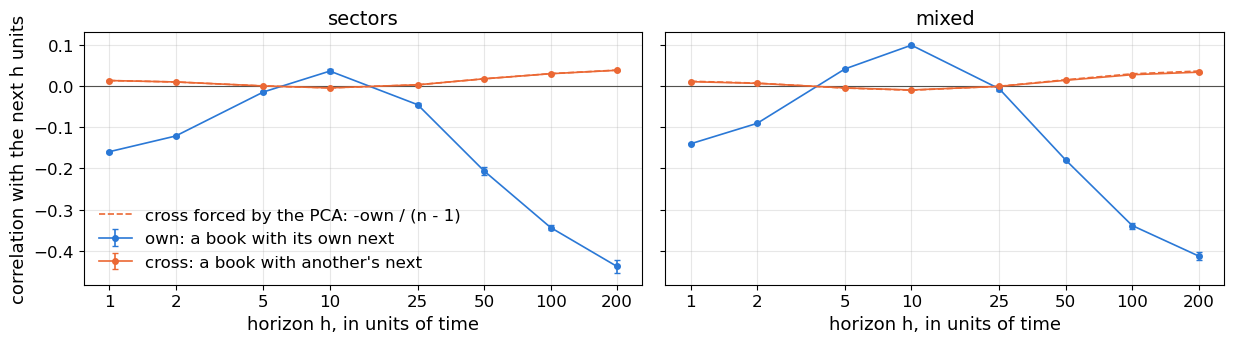


Profit of the contrarian portfolio a decision, in thousandths of a tick, and where it comes from (mean)
             profit     se     own   cross  means
market  lag                                      
sectors 1    45.052  1.631 -19.445  64.575 -0.078
        5   -24.317  0.999 -60.544  36.305 -0.078
        25    0.175  0.342  -4.018   4.269 -0.076
mixed   1    40.458  0.749  -2.635  43.124 -0.031
        5   -18.460  0.287 -41.937  23.508 -0.031
        25    0.075  0.603  -2.233   2.339 -0.031


In [2]:
HORIZONS = (1, 2, 5, 10, 25, 50, 100, 200)  # units of time
LAGS = (1, 5, 25)


def bare_moves(market, seed):
    # The one-unit moves of the mids in a market with no trader, and the same less what the true number of estimated
    # factors takes of them: (moves - mean) @ eigen @ betas, as the library does.
    loadings, factors = MARKETS[market]
    frame = BookMarket(FactorValues(loadings), seed=seed).run(BARE)
    moves = np.diff(frame.filter(like='mid_').ffill().to_numpy(float), axis=0)
    eigen, betas = estimate_factors(moves, factors)
    return moves, moves - (moves - moves.mean(axis=0)) @ eigen @ betas


def autocorrelations(residual, h):
    # The correlations of non-overlapping h-unit sums with the next: of a book's with its own next (own, the mean over
    # books), and of one book's with another's next (cross, the mean over ordered pairs of distinct books). The
    # residuals are orthogonal to the estimated factors, so they sum to about 0 across the books in units of their
    # standard deviations. That forces the cross correlations into a book's next to sum to minus its own: -own / (n - 1)
    # on average, and exactly if the books' standard deviations were equal. Cross less forced could be lead-lag.
    sums = residual[: len(residual) // h * h].reshape(-1, h, residual.shape[1]).sum(axis=1)
    n = sums.shape[1]
    c = np.corrcoef(sums[:-1], sums[1:], rowvar=False)[:n, n:]  # row i: book i's sum, column j: book j's next
    own, cross = np.trace(c) / n, (c.sum() - np.trace(c)) / (n * (n - 1))
    return own, cross, -own / (n - 1)


def remembered(market, seed):
    moves, residual = bare_moves(market, seed)
    memory_rows = []
    for h in HORIZONS:
        own, cross, forced = autocorrelations(residual, h)
        memory_rows.append(
            {
                'market': market,
                'seed': seed,
                'horizon': h,
                'own': own,
                'cross': cross,
                'forced': forced,
                'beyond': cross - forced,
            }
        )
    split_rows = [
        {'market': market, 'seed': seed, 'lag': lag, **contrarian_decomposition(moves, lag)} for lag in LAGS
    ]
    return memory_rows, split_rows


runs = Parallel(n_jobs=-1)(delayed(remembered)(market, seed) for market in MARKETS for seed in FEW)
memory = pd.DataFrame([row for rows, _ in runs for row in rows])
split = pd.DataFrame([row for _, rows in runs for row in rows])

by_horizon = memory.groupby(['market', 'horizon'], sort=False)[['own', 'cross', 'forced', 'beyond']]
memory_mean, memory_se = by_horizon.mean(), by_horizon.sem()
print('Correlation of the residual moves summed over h units with the next h units; mean over seeds, and its se')
print('Forced: what the PCA fixes the cross at, -own / (n - 1). Beyond: cross less forced.')
columns = ['own', 'own_se', 'cross', 'cross_se', 'forced', 'beyond', 'beyond_se']
print(memory_mean.join(memory_se, rsuffix='_se')[columns].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
LINES = (('own', BLUE, 'own: a book with its own next'), ('cross', ORANGE, "cross: a book with another's next"))
for ax, market in zip(axes, MARKETS, strict=True):
    for column, color, label in LINES:
        ax.errorbar(
            HORIZONS,
            memory_mean.loc[market][column],
            yerr=memory_se.loc[market][column],
            color=color,
            marker='o',
            ms=4,
            lw=1.2,
            capsize=2,
            label=label,
        )
    ax.plot(
        HORIZONS,
        memory_mean.loc[market].forced,
        color=ORANGE,
        ls='--',
        lw=1.2,
        label='cross forced by the PCA: -own / (n - 1)',
    )
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.set_xscale('log')
    ax.set_xticks(HORIZONS, [str(h) for h in HORIZONS])
    ax.minorticks_off()
    ax.set_title(market)
    ax.set_xlabel('horizon h, in units of time')
axes[0].set_ylabel('correlation with the next h units')
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

by_lag = split.groupby(['market', 'lag'], sort=False)
decomposition = by_lag[['profit', 'own', 'cross', 'means']].mean()
decomposition.insert(1, 'se', by_lag.profit.sem())
print('\nProfit of the contrarian portfolio a decision, in thousandths of a tick, and where it comes from (mean)')
print((1000 * decomposition).round(3).to_string())

**A book's residual moves bounce, then continue, then revert.** Over one or two units of time a book's residual move and its next correlate negatively (-0.16 and -0.12 in the sectors market, -0.14 and -0.09 in the mixed): a mid that jumps with an order falls back as the book refills. Around 10 units they correlate positively (+0.04 in the sectors market, +0.10 in the mixed), as a mid follows its fair value a few units late. At 25 units they have reverted in the sectors market (-0.05) and not yet in the mixed (-0.01, se 0.005). From 50 units on they revert in both, more the longer the horizon (-0.21 and -0.18 at 50, -0.34 at 100 in both, -0.44 and -0.41 at 200), as each book's own part decays with its half-life of 50.

**Nothing passes between the books once the factors are out.** The cross-correlation is what the PCA forces, to within 0.003 at every horizon: a book's residual past says nothing of another's residual future.

**On raw moves, the contrarian portfolio lives on the factors catching up.** Lo and MacKinlay's portfolio on one-unit moves with a lag of 1 makes +45 thousandths of a tick a decision in the sectors market (se 1.6) and +40 in the mixed (se 0.7), more than all of it from the cross part (+65 and +43): with the factors in them, one book's move foretells the others' as their mids catch up. Its own part is negative (-19 and -3): a book's raw moves continue. With a lag of 5 it loses (-24 and -18), and with a lag of 25 it makes nothing (+0.2 and +0.1, se 0.3 and 0.6). These are profits of a portfolio with weights of 1/n, before any cost.

## 2. Do the Signals Know Anything?

A signal can know something and still lose to what trading it costs, so first ask what each signal knows, apart from the trading. The test is a *listener*: a trader of each kind in a bare market with a size so small that its lots round to zero, so that it never trades and the market is untouched (the cell checks that every listener's lots stay at 0). At each decision it records the factor-neutral weights it would hold. Two measures of what they know, over the next decision:

- The **edge** is the paper P&L of the weights over the next decision, per gross lot held (the sum of the weights' absolute values), in ticks.
- The **IC** is the correlation across the books of the weights with the books' next moves, averaged over decisions.

Fourteen listeners share each bare market, which is run for the same 12,000 units of time on the same eight seeds as in section 1. *Every* is the interval between a listener's decisions, in units of time, and it records its weights at each. The edge is earned on the lots held for a decision, but a signal that changes pays to trade the change, so it is set against what a lot traded costs. The **turnover** is the lots a listener trades at a decision per gross lot it holds, on average: the sum over books of the change in each weight as a share of the gross, which is 2 if the weights turn over in full and less if they carry on. The **edge per lot traded** is the edge over the turnover, the most a lot traded could cost for the signal to pay. For comparison, what a lot traded costs: one trader of each of four kinds (reversal with look back 5, momentum with 20, lead-lag and the queues; not trade flow) that rebalances at every decision of 5 units, in a market of its own on seed 101, over 4,000 units of time after its warm-up, and what it paid to cross the spreads for each lot it traded. A round trip of a lot, twice that, is the hurdle for a decision only if the weights turn over in full.

Lots traded by the 14 listeners, in 16 runs of a bare market: 0

Edge: ticks a gross lot held a decision. Turnover: lots traded a decision, a gross lot held. Per lot: edge per lot traded, in ticks.
IC: correlation with the next move. Mean over seeds, and its se.
                                                 edge  edge_se  turnover  per_lot  per_lot_se     ic  ic_se  decisions
market  listener                                                                                                      
sectors reversal, look back 1, every 1         0.1051   0.0012      1.49    0.070       0.001  0.104  0.001    11444.0
        reversal, look back 1, every 5         0.0054   0.0052      1.39    0.004       0.004 -0.008  0.002     1897.0
        reversal, look back 5, every 5        -0.0283   0.0041      0.61   -0.046       0.007 -0.020  0.002     1897.0
        reversal, look back 20, every 5        0.0946   0.0041      0.35    0.268       0.010  0.044  0.002     1897.0
        momentum, look 

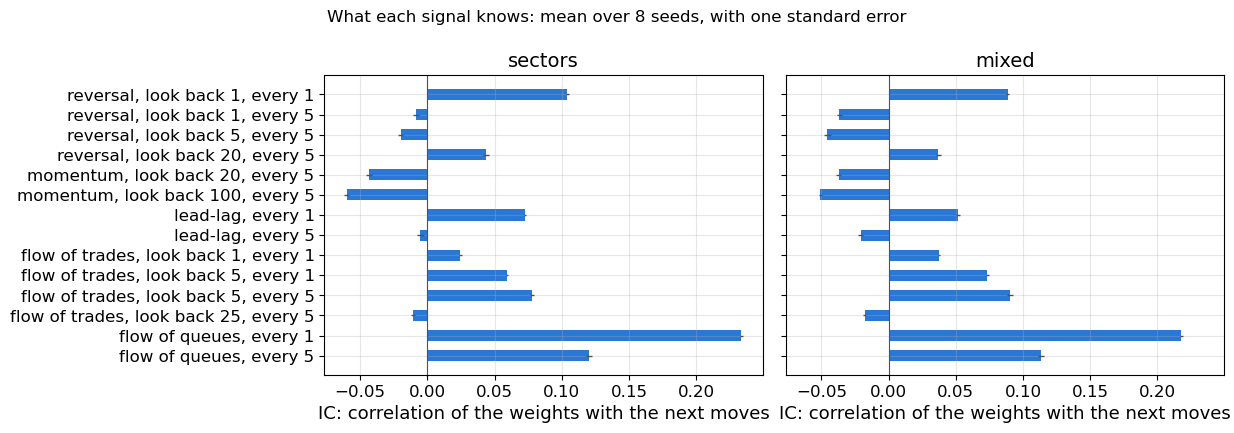


What crossing the spreads cost, in ticks a lot traded, for a trader that rebalances at every decision
                         lots  cost_a_lot
market  kind                             
sectors reversal        12614        1.12
        momentum         7513        1.02
        lead-lag        26910        1.30
        flow of queues  28009        1.36
mixed   reversal        11876        1.08
        momentum         6460        0.98
        lead-lag        26249        1.24
        flow of queues  27613        1.34


In [3]:
TINY = 1e-6  # lots of the largest leg: so few that every lot rounds to 0
LISTENERS = {  # name: kind, interval and settings (the weights are those of a rebalance at every decision)
    'reversal, look back 1, every 1': (ReversalTrader, 1.0, dict(lookback=1)),
    'reversal, look back 1, every 5': (ReversalTrader, 5.0, dict(lookback=1)),
    'reversal, look back 5, every 5': (ReversalTrader, 5.0, dict(lookback=5)),
    'reversal, look back 20, every 5': (ReversalTrader, 5.0, dict(lookback=20)),
    'momentum, look back 20, every 5': (MomentumTrader, 5.0, dict(lookback=20)),
    'momentum, look back 100, every 5': (MomentumTrader, 5.0, dict(lookback=100)),
    'lead-lag, every 1': (LeadLagTrader, 1.0, dict(lookback=1)),
    'lead-lag, every 5': (LeadLagTrader, 5.0, dict(lookback=1)),
    'flow of trades, look back 1, every 1': (FlowTrader, 1.0, dict(lookback=1)),
    'flow of trades, look back 5, every 1': (FlowTrader, 1.0, dict(lookback=5)),
    'flow of trades, look back 5, every 5': (FlowTrader, 5.0, dict(lookback=5)),
    'flow of trades, look back 25, every 5': (FlowTrader, 5.0, dict(lookback=25)),
    'flow of queues, every 1': (FlowTrader, 1.0, dict(lookback=1, measure='queues')),
    'flow of queues, every 5': (FlowTrader, 5.0, dict(lookback=1, measure='queues')),
}


def listener(kind, interval, settings, factors):
    # A trader of this kind that keeps, at each decision it rebalances at, the mids and the weights it would hold.
    class Listening(kind):
        def __post_init__(self):
            super().__post_init__()
            self.log = []

        def decide(self, mids):
            before = self._since
            moves = super().decide(mids)
            if self._since > before:
                self.log.append((mids.copy(), neutralize(self._scores, self._betas if self.factors else None)))
            return moves

    return Listening(size=TINY, interval=interval, hold=1, factors=factors, **settings)


def listen(market, seed):
    loadings, factors = MARKETS[market]
    traders = {name: listener(*spec, factors) for name, spec in LISTENERS.items()}
    book = BookMarket(FactorValues(loadings), seed=seed, traders=tuple(traders.values()))
    while book.time < BARE:
        book.step()
    rows = []
    for name, trader in traders.items():
        mids = np.array([m for m, _ in trader.log])
        weights = np.array([w for _, w in trader.log])[:-1]
        moves = np.diff(mids, axis=0)  # over the next decision
        gross = np.abs(weights).sum(axis=1)
        w, m = weights[gross > 0], moves[gross > 0]
        held = w / gross[gross > 0][:, None]  # the weights as shares of the gross lots held
        centered_w, centered_m = w - w.mean(axis=1, keepdims=True), m - m.mean(axis=1, keepdims=True)
        scale = np.sqrt((centered_w**2).sum(axis=1) * (centered_m**2).sum(axis=1))
        ic = (centered_w * centered_m).sum(axis=1)[scale > 0] / scale[scale > 0]
        edge = ((w * m).sum(axis=1) / gross[gross > 0]).mean()
        turnover = np.abs(np.diff(held, axis=0)).sum(axis=1).mean()  # lots traded a decision, a gross lot held
        rows.append(
            {
                'market': market,
                'seed': seed,
                'listener': name,
                'edge': edge,
                'turnover': turnover,
                'per_lot': edge / turnover,
                'ic': ic.mean(),
                'decisions': len(w),
                'lots': trader.lots,
            }
        )
    return rows


heard = pd.DataFrame(
    [row for rows in Parallel(n_jobs=-1)(delayed(listen)(m, s) for m in MARKETS for s in FEW) for row in rows]
)
assert (heard.lots == 0).all(), 'a listener traded'
runs_heard = len(heard) // len(LISTENERS)
print(f'Lots traded by the {len(LISTENERS)} listeners, in {runs_heard} runs of a bare market: {heard.lots.sum()}')
by_listener = heard.groupby(['market', 'listener'], sort=False)
knows = pd.DataFrame(
    {
        'edge': by_listener.edge.mean(),
        'edge_se': by_listener.edge.sem(),
        'turnover': by_listener.turnover.mean(),
        'per_lot': by_listener.per_lot.mean(),
        'per_lot_se': by_listener.per_lot.sem(),
        'ic': by_listener.ic.mean(),
        'ic_se': by_listener.ic.sem(),
        'decisions': by_listener.decisions.mean(),
    }
)
print(
    '\nEdge: ticks a gross lot held a decision. Turnover: lots traded a decision, a gross lot held. Per lot: edge per '
    'lot traded, in ticks.\nIC: correlation with the next move. Mean over seeds, and its se.'
)
print(
    knows.round(
        {'edge': 4, 'edge_se': 4, 'turnover': 2, 'per_lot': 3, 'per_lot_se': 3, 'ic': 3, 'ic_se': 3, 'decisions': 0}
    ).to_string()
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True, sharey=True)
for ax, market in zip(axes, MARKETS, strict=True):
    rows = knows.loc[market]
    place = np.arange(len(rows))[::-1]
    ax.barh(place, rows.ic, xerr=rows.ic_se, height=0.55, color=BLUE, error_kw=dict(ecolor=GRAY, lw=1))
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_yticks(place, rows.index)
    ax.set_title(market)
    ax.set_xlabel('IC: correlation of the weights with the next moves')
fig.suptitle(f'What each signal knows: mean over {len(FEW)} seeds, with one standard error', fontsize=12)
fig.tight_layout()
plt.show()

# What crossing the spreads costs a lot: one trader of each kind, 5 lots of the largest, rebalancing at every decision.
COSTING = {
    'reversal': (ReversalTrader, dict(lookback=5)),
    'momentum': (MomentumTrader, dict(lookback=20)),
    'lead-lag': (LeadLagTrader, dict(lookback=1)),
    'flow of queues': (FlowTrader, dict(lookback=1, measure='queues')),
}


def costing(market, name):
    loadings, factors = MARKETS[market]
    kind, settings = COSTING[name]
    trader = kind(size=5.0, interval=EVERY, hold=1, factors=factors, **settings)
    got = scored(lambda: trader, loadings, FEW[0], trader.warm_up + 400.0, 4_000.0)
    return {'market': market, 'kind': name, 'lots': got['lots'], 'cost_a_lot': got['costs'] / got['lots']}


crossing = pd.DataFrame(Parallel(n_jobs=-1)(delayed(costing)(m, name) for m in MARKETS for name in COSTING))
print('\nWhat crossing the spreads cost, in ticks a lot traded, for a trader that rebalances at every decision')
print(crossing.set_index(['market', 'kind']).round({'lots': 0, 'cost_a_lot': 2}).to_string())

**Every signal knows something, at its own horizon.** In a market none of them trades, the queue imbalance knows most: its weights correlate 0.23 and 0.22 with the next unit's moves, and 0.12 and 0.11 with the next five. Trade flow over the last 5 decisions knows some (0.06 to 0.09). Reversal knows something one unit ahead (0.10 and 0.09) and over 20 decisions of five units (0.04), but not in between, where moves continue. Momentum knows the opposite of reversal, as it must here: -0.04 to -0.06. Lead-lag knows something one unit ahead (0.07 and 0.05) and nothing, or a little less, five ahead. Section 1 found nothing passing between the books once the factors are out, so what its factor-neutral weights know is most likely the last move's bounce seen through the other books' moves, which stand in for minus a book's own when the residuals add to about nothing.

**What they know is small against what trading it costs.** Rebalanced at every decision of five units, the best, trade flow over 5 decisions, earns 0.31 and 0.33 ticks a lot traded, against the 1.21 and 1.15 a lot that trading it costs in section 3. The queue imbalance, deciding every five units like the trader costed beside it, earns 0.17 and 0.15 a lot traded, about an eighth of what a lot costs it (1.36 and 1.34, the most of the four kinds costed). So no signal here pays at the turnover of a rebalance at every decision. A signal held longer earns over more decisions for each lot traded, which is how a slow reversal can pay where this figure says no: section 3 tries that.

## 3. Can They Be Traded?

Each kind alone in its market, with market orders, after the same warm-up, over 20,000 units of time on the twelve seeds. A trader decides every 1 or every 5 units of time (*every*) and rebalances every *hold* decisions, with 5 lots of the largest book. Its settings are from small grids looked at on seeds 1 to 8, and every trader is neutral to three estimated factors, as many as the fair values share. The baselines are two traders of notebook 12 with the settings found there: eight pairs chosen by distance, and stat-arb on PCA residuals. The burn is the same for all: the longest warm-up among them, the baselines included, and 400 units of time more. That is a little longer than notebook 12's, so the baselines differ a little from its table. The settings were fixed in advance, from seeds 1 to 8, so the tables below are on seeds that chose none of them; a count of settings that earn more than two standard errors is a count over that fixed list, not a test, and the best of a kind is the best of the few tried, on these seeds.

                                                             pnl     se  positive  before_costs     costs      lots  cost_a_lot  entries  gross  exposure  risk_adjusted
market  trader                                                                                                                                                          
sectors reversal, look back 20, hold 100, every 5          968.0  106.0  12 of 12        2779.0    1811.0    1439.0        1.26    240.0   25.2       1.7          0.007
        reversal, look back 5, hold 20, every 5          -4137.0  237.0   0 of 12        5098.0    9236.0    7265.0        1.27   1211.0   25.1       1.6         -0.025
        reversal, look back 1, hold 5, every 5          -36214.0  318.0   0 of 12         791.0   37005.0   28326.0        1.31   4704.0   24.9       1.6         -0.166
        momentum, look back 100, hold 100, every 5       -5087.0  137.0   0 of 12       -2916.0    2170.0    1706.0        1.27    294.0   25.5       1.7  

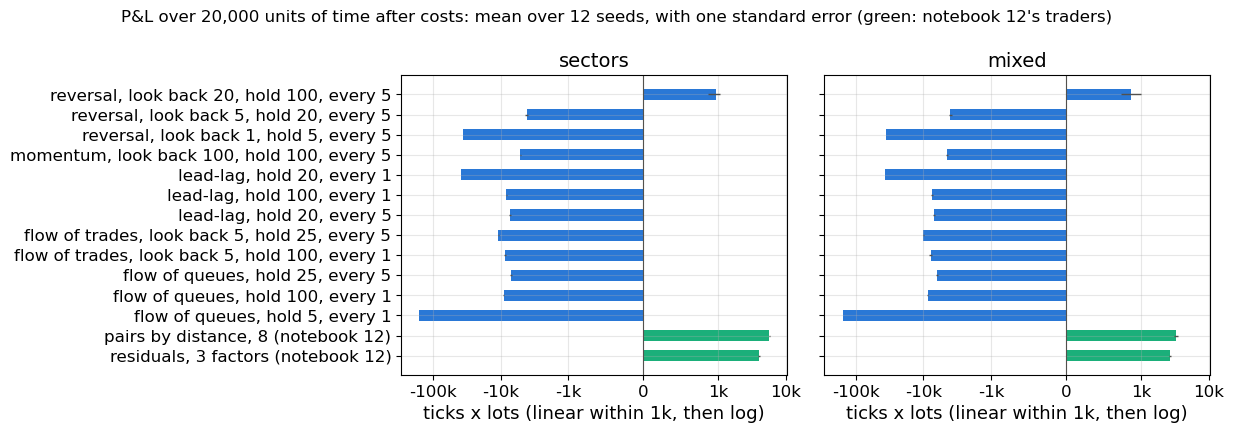

In [4]:
FORMATION = 2_000  # the decisions' mids a trader of notebook 12 chooses its pairs from: 10,000 units of time
Z = dict(window=400, entry=2.0, interval=EVERY, formation=FORMATION)  # a window of 2,000 units of time
RESIDUAL_BEST = dict(window=400, open_at=1.5, close_long=0.0, close_short=0.0)


def cross_section(kind, **settings):
    # A trader of this kind with 5 lots of the largest, made for the number of factors its market has.
    return lambda factors: kind(size=5.0, factors=factors, **settings)


TRADERS = {
    'reversal, look back 20, hold 100, every 5': cross_section(ReversalTrader, lookback=20, hold=100, interval=5.0),
    'reversal, look back 5, hold 20, every 5': cross_section(ReversalTrader, lookback=5, hold=20, interval=5.0),
    'reversal, look back 1, hold 5, every 5': cross_section(ReversalTrader, lookback=1, hold=5, interval=5.0),
    'momentum, look back 100, hold 100, every 5': cross_section(MomentumTrader, lookback=100, hold=100, interval=5.0),
    'lead-lag, hold 20, every 1': cross_section(LeadLagTrader, lookback=1, hold=20, interval=1.0),
    'lead-lag, hold 100, every 1': cross_section(LeadLagTrader, lookback=1, hold=100, interval=1.0),
    'lead-lag, hold 20, every 5': cross_section(LeadLagTrader, lookback=1, hold=20, interval=5.0),
    'flow of trades, look back 5, hold 25, every 5': cross_section(FlowTrader, lookback=5, hold=25, interval=5.0),
    'flow of trades, look back 5, hold 100, every 1': cross_section(FlowTrader, lookback=5, hold=100, interval=1.0),
    'flow of queues, hold 25, every 5': cross_section(FlowTrader, lookback=1, hold=25, interval=5.0, measure='queues'),
    'flow of queues, hold 100, every 1': cross_section(
        FlowTrader, lookback=1, hold=100, interval=1.0, measure='queues'
    ),
    'flow of queues, hold 5, every 1': cross_section(FlowTrader, lookback=1, hold=5, interval=1.0, measure='queues'),
}
BASELINES = {
    'pairs by distance, 8 (notebook 12)': lambda factors: RelationTrader(
        choose=partial(pairs_by_distance, count=8), size=2.5, **Z
    ),
    'residuals, 3 factors (notebook 12)': lambda factors: ResidualTrader(
        factors=3, interval=EVERY, size=5.0, **RESIDUAL_BEST
    ),
}
EVERYONE = {**TRADERS, **BASELINES}
BURN = max(make(3).warm_up for make in EVERYONE.values()) + 400.0

# The before-cost column adds back what crossing the spreads cost. At high turnover it also holds the trader's own
# impact on the mid it is marked at: its buys move the book's mid up, and it is marked at the new mid. A review of the
# library found that this can be nearly all of the before-cost figure, so the column is not the worth of a signal;
# section 2 measures that without trading.
frame, table = compare(EVERYONE, BURN)
print(shown(table))
print(
    "\nBefore costs is P&L with what crossing the spreads cost added back. At high turnover it also holds the trader's "
    "own impact on the mid it is marked at,\nand so is not the worth of its signal: section 2 measures that without "
    'trading. Entries are books newly held long or short (relations entered, for the baselines).'
)
print(
    f"The burn is {BURN:,.0f} units of time, {BURN - (FORMATION * EVERY + 400.0):,.0f} more than notebook 12's, so the "
    "baselines differ a little from its table."
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True, sharey=True)
for ax, name in zip(axes, MARKETS, strict=True):
    rows = table.loc[name]
    place = np.arange(len(rows))[::-1]
    colors = [AQUA if trader in BASELINES else BLUE for trader in rows.index]
    ax.barh(place, rows.pnl, xerr=rows.se, height=0.55, color=colors, error_kw=dict(ecolor=GRAY, lw=1))
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_yticks(place, rows.index)
    ax.set_title(name)
    ax.set_xlabel('ticks x lots (linear within 1k, then log)')
    ax.set_xscale('symlog', linthresh=1_000)  # since some lose a hundred times what others make
    ax.set_xticks([-100_000, -10_000, -1_000, 0, 1_000, 10_000])
    ax.minorticks_off()
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:,.0f}k' if x else '0'))
fig.suptitle(
    f'P&L over {SPAN:,.0f} units of time after costs: mean over {len(SEEDS)} seeds, with one standard error '
    "(green: notebook 12's traders)",
    fontsize=12,
)
fig.tight_layout()
plt.show()

**Only the slow reversal pays, and little.** Over 20,000 units, reversal over 20 decisions, rebalanced every 100, makes +968 (se 106) in the sectors market and +868 (se 138) in the mixed, on 12 and 11 of the 12 seeds: a sixth and a quarter of what eight pairs make (+5,706 and +3,283), for fewer lots (1,439 against 2,387 in the sectors market). It was the best of the three reversal settings on seeds 1 to 8 as well, where it was chosen. Every other setting loses, in both markets and on every seed.

**The faster the same signal is traded, the more it loses.** The queue imbalance rebalanced every 5 decisions of one unit loses 162,450 in the sectors market: 141,273 lots at 1.40 a lot, against +35,156 before costs, a figure that at this turnover holds its own orders' push on the mids it is marked at, and so says little of the signal (section 2 measures that). Held for 100 decisions of one unit, it trades a nineteenth of the lots and loses 9,047, what it makes before costs (+1,168) being a ninth of its costs. Lead-lag held for 20 decisions of one unit loses 38,679, and for 100 decisions 8,196. Trade flow, tried at two settings only, loses about as much at either (10,798 and 8,549).

**Momentum loses, as it must here.** It loses 5,087 and 4,459, and before costs as well (-2,916 and -2,466): over its 100 decisions of five units the books' residuals revert, and the factors, random walks, have nothing to continue.

**So in these books, the cross-sectional signals are too fast or too weak for market orders, reversal at a longer look back apart.** What could change that is trading less for the same signal: going part of the way to the target, with a band inside which it does not trade (Gârleanu and Pedersen 2013; Davis and Norman 1990). Section 5 tries that: reversal, at a look back of 50 and a rate of 0.1, then makes +4,364 (se 109) in the sectors market, and the flows and lead-lag still lose.

## 4. In a Backtest's Terms

The scorecard and signal chart of each new kind, in the sectors market, on seed 101, which played no part in choosing any setting. Reversal, momentum, lead-lag and the flow of the queues are at the dashboard's default look back, hold and interval as they were in stage 1 (reversal's default is now section 5's look back of 50, rebalanced at every decision with a trade rate of 0.1, whose card is in section 5); the flow of the trades, which the dashboard offers as the other reading of the flow, is at look back 5, hold 25 and interval 5. They are the traders of the previous section's table, so each is neutral to three factors, as the dashboard's are. As in notebooks 10 to 12, the record has one row per decision: what the trader held after it, valued at the mids just before its orders, with costs that add up to what crossing the spreads cost. The signal chart shows one book, one that the trader changes often, with that book's raw score and a line at a score of 0. The trader holds its weights, the scores less their projection on the ones and the factors, so it can be long a book whose score is under 0.

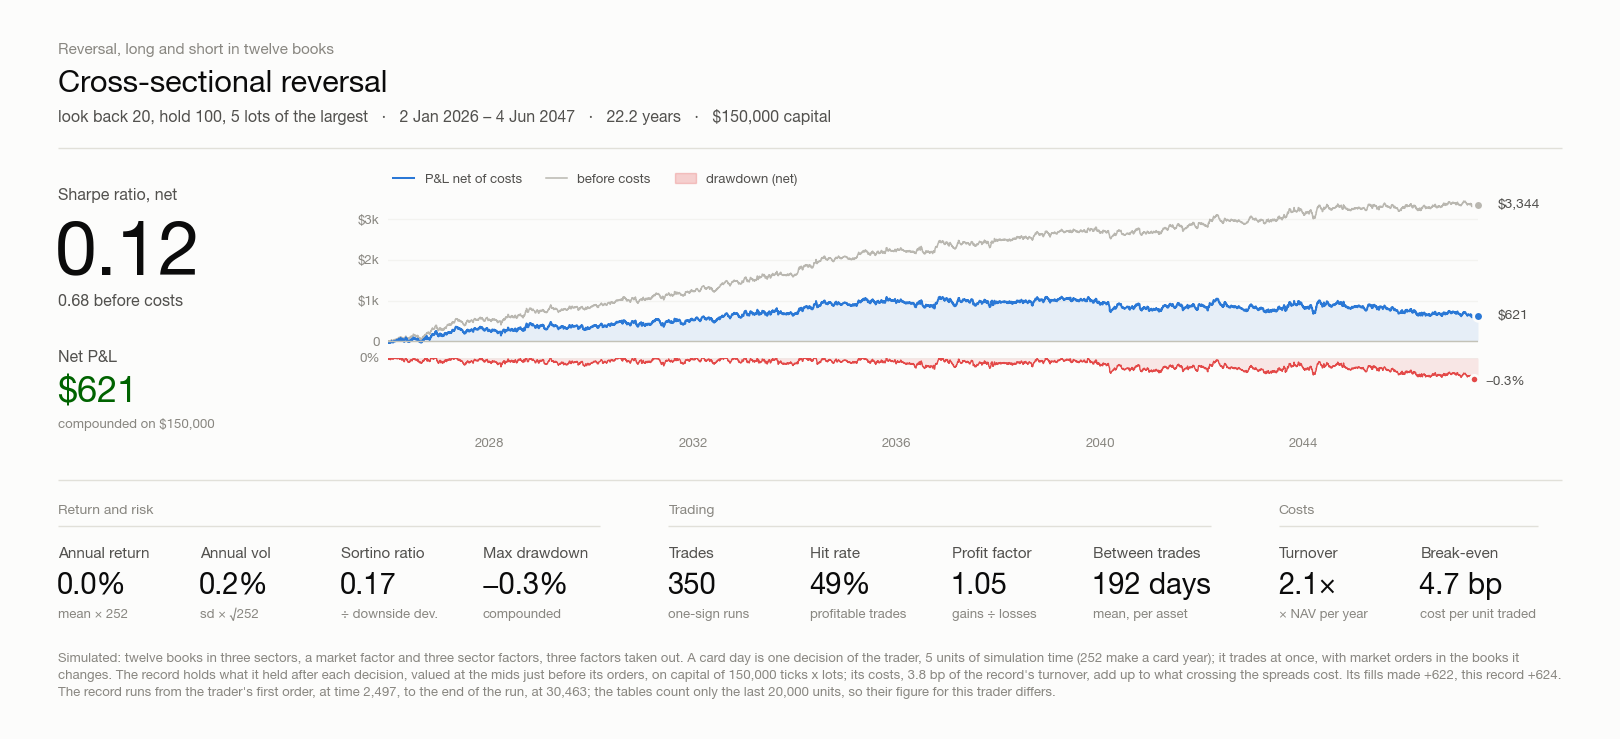

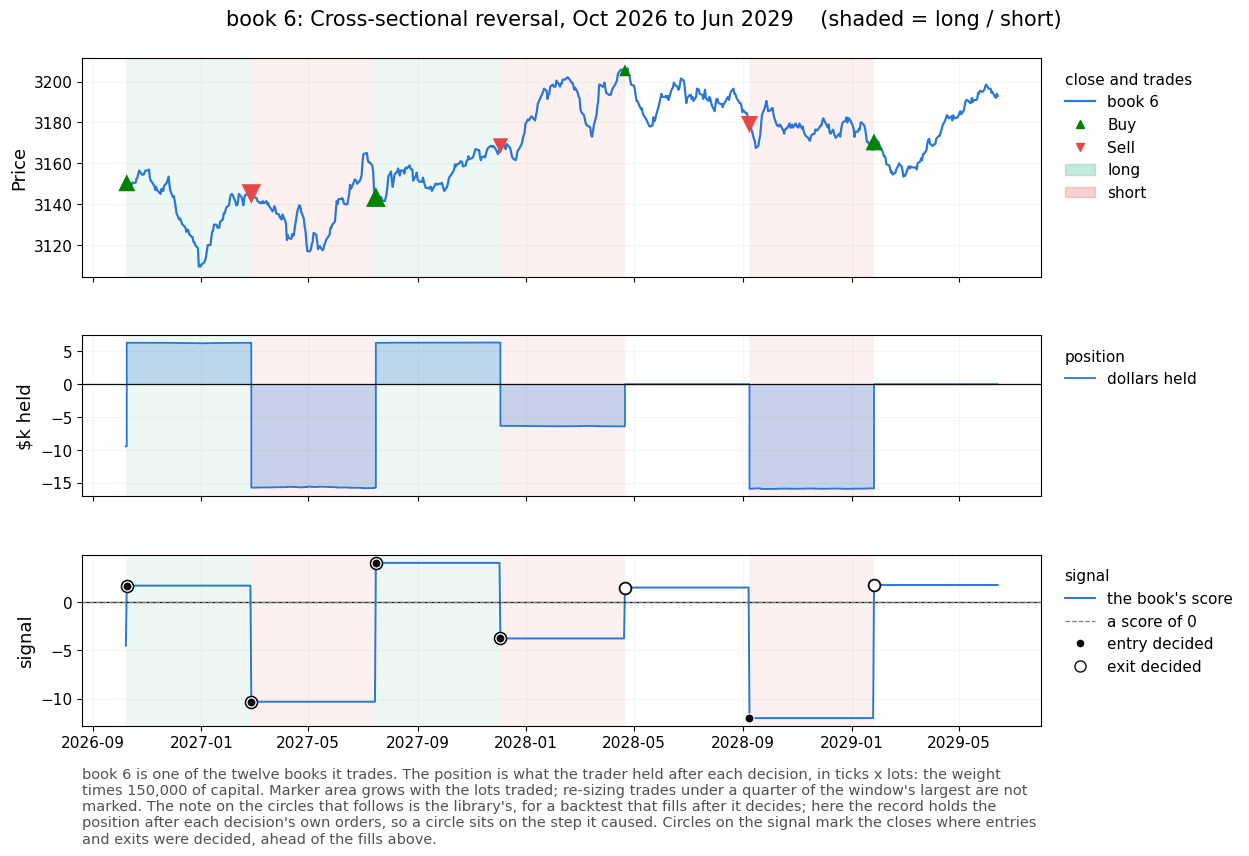

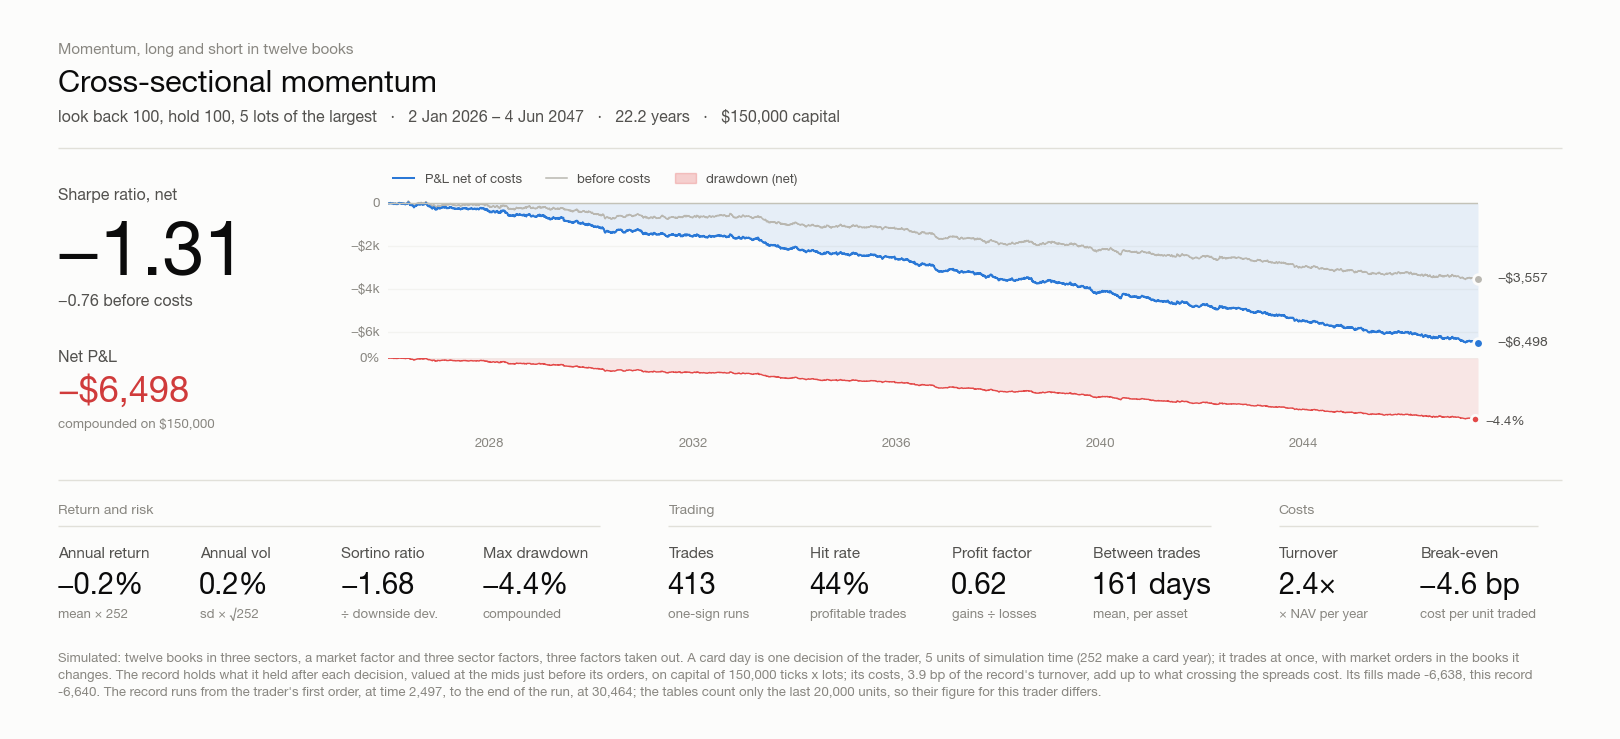

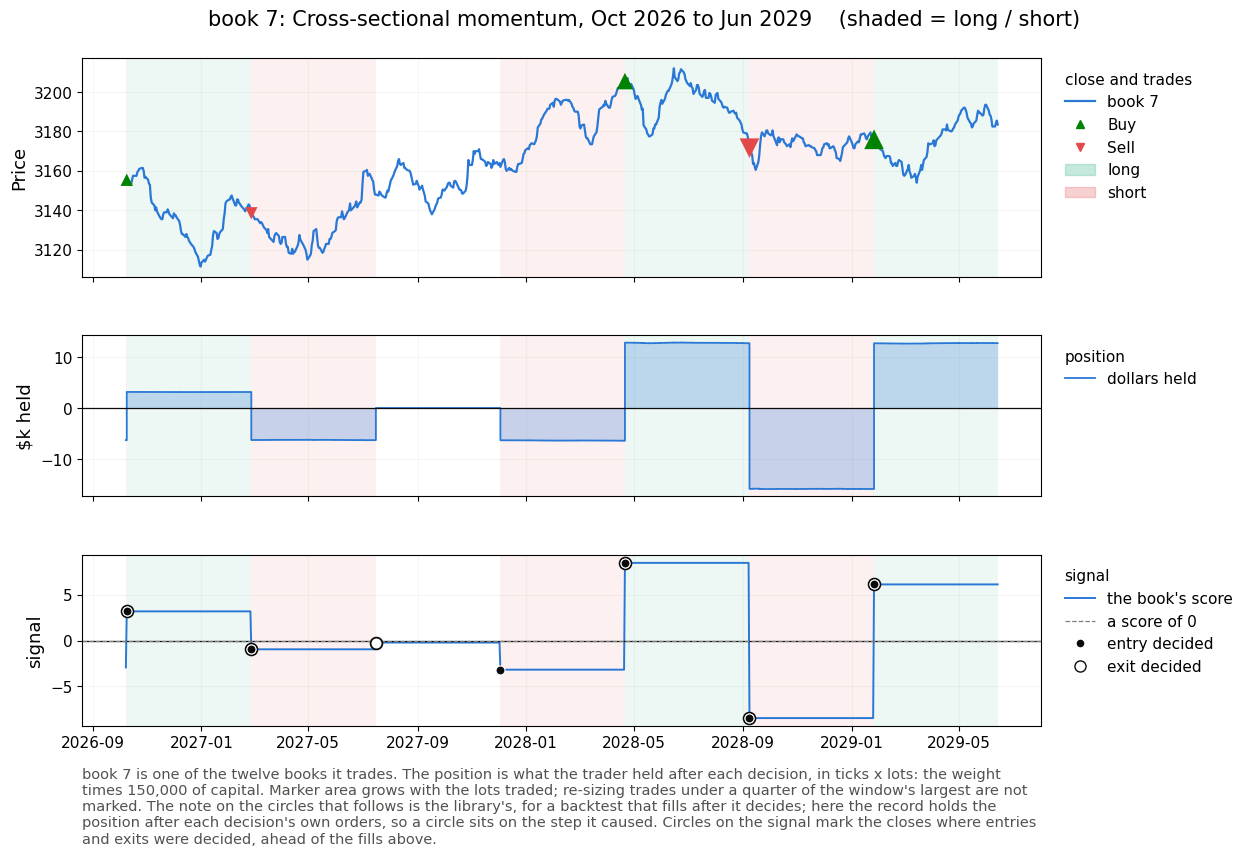

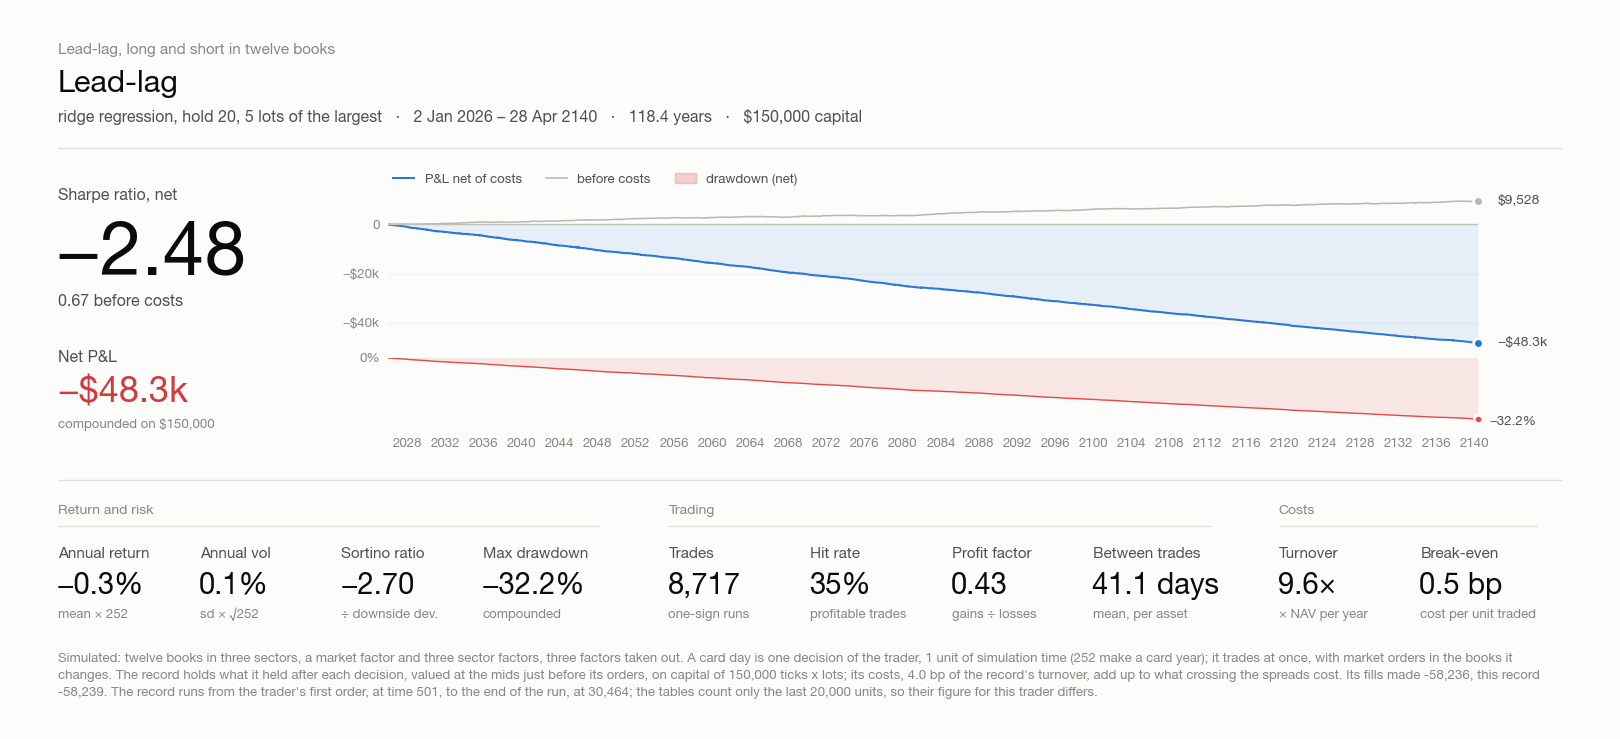

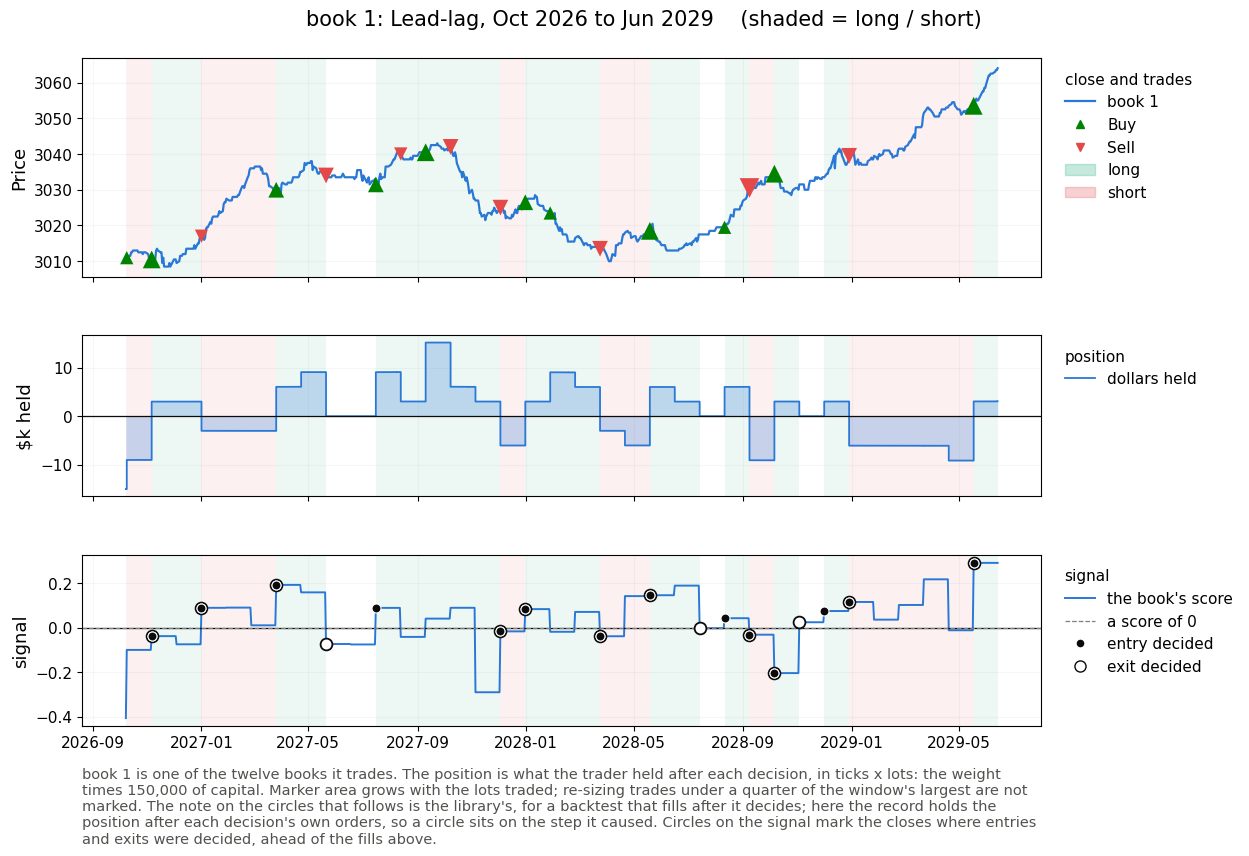

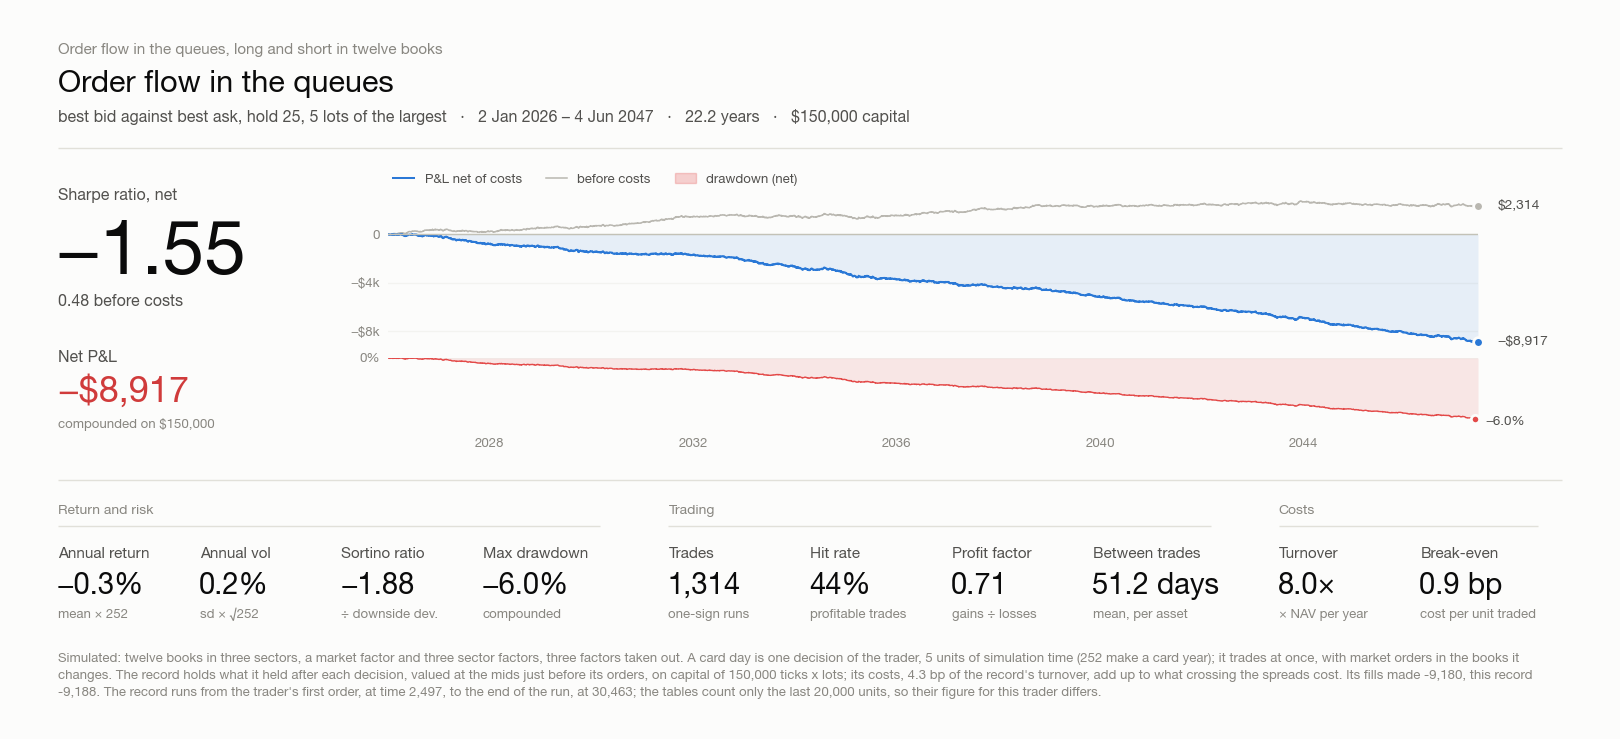

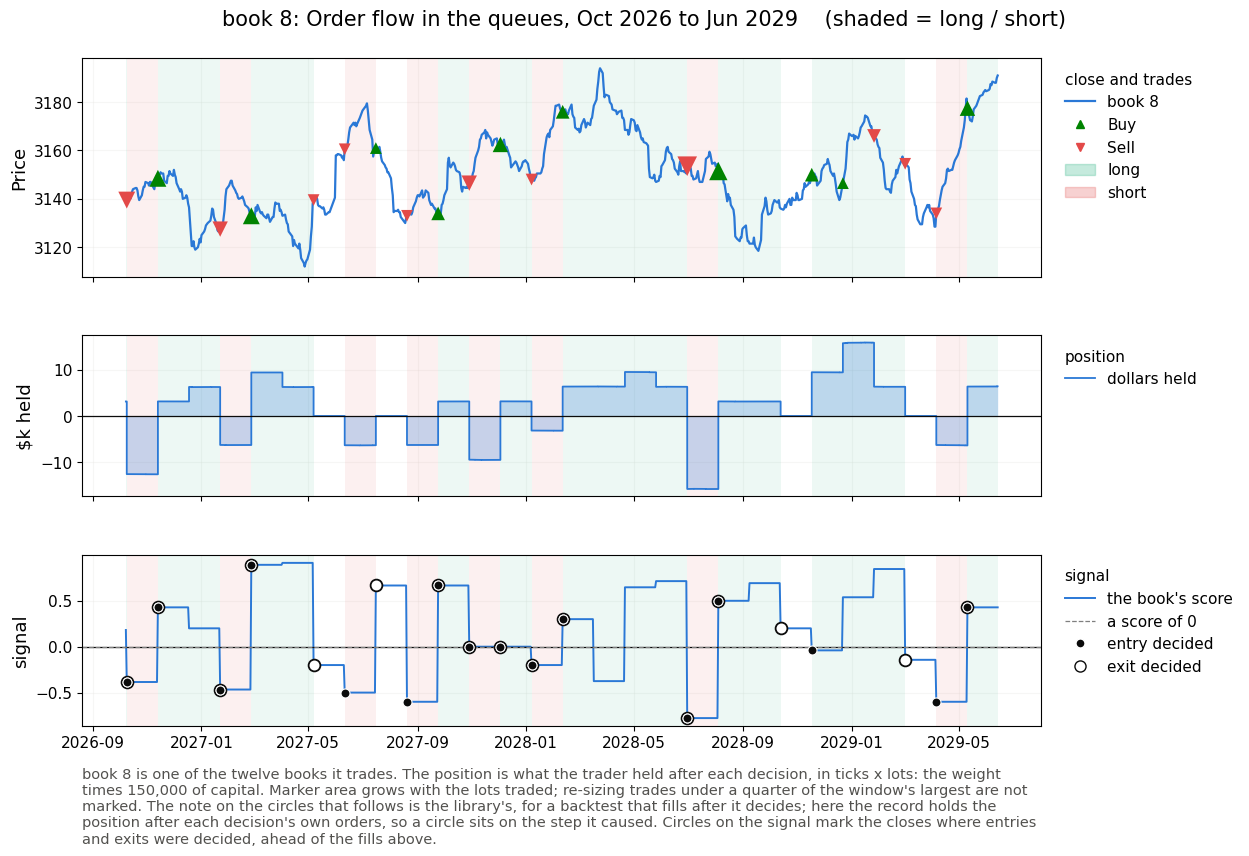

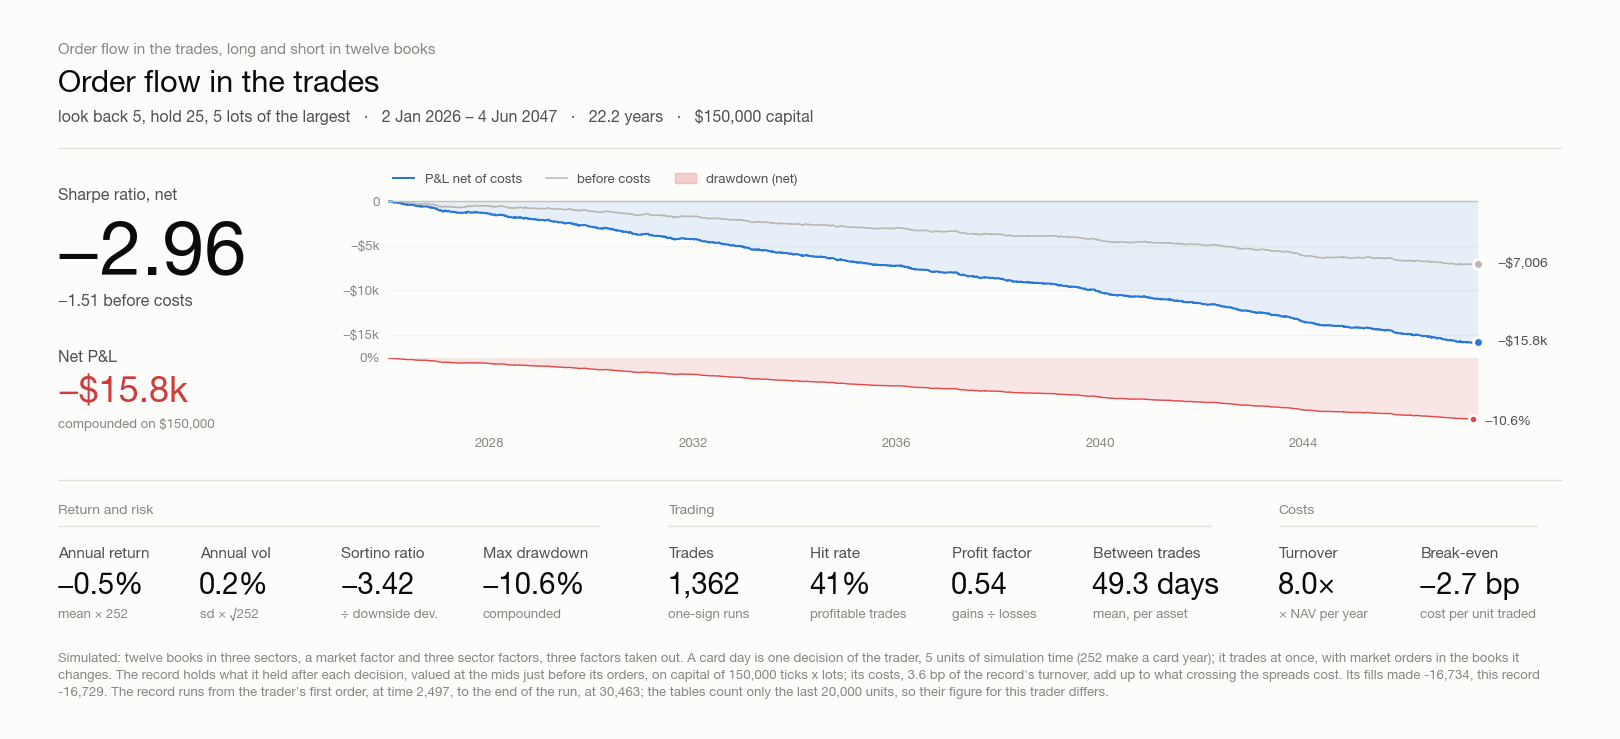

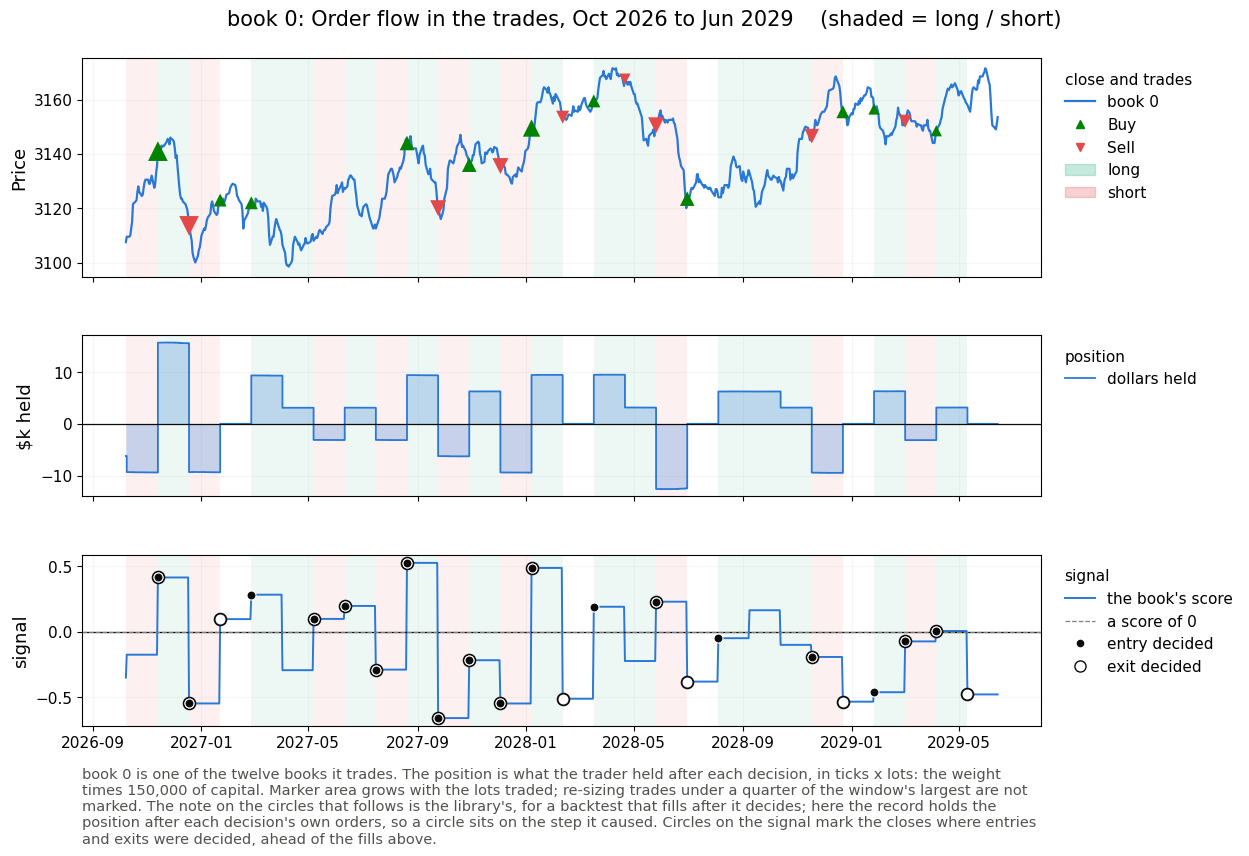

Each card against the fills, within what the run moves after its last decision: {'reversal': '+622 and +624', 'momentum': '-6,638 and -6,640', 'lead-lag': '-58,236 and -58,239', 'flow of queues': '-9,180 and -9,188', 'flow of trades': '-16,734 and -16,729'}
The most each card holds, as a multiple of the capital (above 1 the figure is leveraged): {'reversal': '0.82, above 1 on 0.0% of days', 'momentum': '0.85, above 1 on 0.0% of days', 'lead-lag': '0.98, above 1 on 0.0% of days', 'flow of queues': '0.99, above 1 on 0.0% of days', 'flow of trades': '0.80, above 1 on 0.0% of days'}
The tables' figure for these runs, the last 20,000 units only: {'reversal': '+67', 'momentum': '-5,134', 'lead-lag': '-39,432', 'flow of queues': '-7,385', 'flow of trades': '-12,297'}


In [5]:
CARDS = {
    'reversal': dict(
        trader='reversal, look back 20, hold 100, every 5',
        strategy='Cross-sectional reversal',
        detail='look back 20, hold 100, 5 lots of the largest',
        title='Reversal, long and short in twelve books',
        every=5,
    ),
    'momentum': dict(
        trader='momentum, look back 100, hold 100, every 5',
        strategy='Cross-sectional momentum',
        detail='look back 100, hold 100, 5 lots of the largest',
        title='Momentum, long and short in twelve books',
        every=5,
    ),
    'lead-lag': dict(
        trader='lead-lag, hold 20, every 1',
        strategy='Lead-lag',
        detail='ridge regression, hold 20, 5 lots of the largest',
        title='Lead-lag, long and short in twelve books',
        every=1,
    ),
    'flow of queues': dict(
        trader='flow of queues, hold 25, every 5',
        strategy='Order flow in the queues',
        detail='best bid against best ask, hold 25, 5 lots of the largest',
        title='Order flow in the queues, long and short in twelve books',
        every=5,
    ),
    'flow of trades': dict(
        trader='flow of trades, look back 5, hold 25, every 5',
        strategy='Order flow in the trades',
        detail='look back 5, hold 25, 5 lots of the largest',
        title='Order flow in the trades, long and short in twelve books',
        every=5,
    ),
}
SETTING = 'twelve books in three sectors, a market factor and three sector factors, three factors taken out'
runs_of_cards = Parallel(n_jobs=-1)(delayed(recorded)(TRADERS[form['trader']], BURN) for form in CARDS.values())
done = dict(zip(CARDS, runs_of_cards, strict=True))
agreement, peaks = {}, {}
for name, form in CARDS.items():
    trader, fills = done[name]
    held = np.array([step[2] for step in trader.history])
    book = int(np.argmax((np.diff(held, axis=0) != 0).sum(axis=0)))  # the book whose lots change most often
    gross = record_of(trader)[2].abs().sum(axis=1)  # what it holds, as a multiple of the capital
    peaks[name] = f'{gross.max():.2f}, above 1 on {(gross > 1).mean():.1%} of days'
    agreement[name] = card(
        trader,
        fills,
        form['strategy'],
        form['detail'],
        form['title'],
        SETTING,
        "the book's score",
        [(0.0, 'C7', 'a score of 0')],
        book,
        book,
        per_unit=form['every'],
    )
print(
    'Each card against the fills, within what the run moves after its last decision:',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in agreement.items()},
)
print('The most each card holds, as a multiple of the capital (above 1 the figure is leveraged):', peaks)
# The cards run from each trader's first order to the end; the tables count only the last SPAN units after the burn.
counted = {
    name: frame[(frame.market == 'sectors') & (frame.trader == form['trader']) & (frame.seed == SEEDS[0])].pnl.item()
    for name, form in CARDS.items()
}
print(
    f"The tables' figure for these runs, the last {SPAN:,.0f} units only:",
    {k: f'{v:+,.0f}' for k, v in counted.items()},
)

## 5. Trading Less for the Same Signal

Section 3 found that the faster a signal is traded, the more it loses. Can the same signal be traded less? There are three ways, and the library gives a rate and a band to every trader that holds lots in many books and nets its orders, as they do by default (`BookTrader`, in `lob/statarb.py`):

- **Hold longer, or enter later.** A cross-sectional trader rebalances every *hold* decisions, as in section 3, so its target changes less often. A trader of pairs or of residuals opens a position only beyond a level of its z-score or s-score, its *entry*, and a higher entry asks for fewer positions.
- **A rate below 1.** The trader keeps an *aim*, in lots that need not be whole, and at each decision the aim goes only that share of the way to its target (partial adjustment: Gârleanu and Pedersen 2013). The trader trades the gap from its position to its aim, in whole lots, so its position follows a smoothed path of its targets.
- **A band.** The trader does not trade within that many lots of its aim, and from outside the band it trades to the band's edge (Davis and Norman 1990). A band applies to each book alone, so one leg of a relation can sit inside it while another trades. In a book whose target is 0 the trader trades all the way to its aim, whatever the band, so a band does not keep a position that the rule has closed.

With a rate of 1 and no band the aim is the target, the whole way, as in section 3. A cross-sectional trader with a rate below 1 or a band trades toward its target at every decision, and not only at a rebalance: the rebalance sets the target, and between rebalances its aim and its position go on toward it.

**This is not Gârleanu and Pedersen's trader.** For one signal that decays at a steady rate, their aim is the mean-variance portfolio of the signal now, scaled down the faster the signal decays and the more trading costs. Here the target is the trader's own rule's, scaled to its size whatever the signal's strength, so how much it holds is the user's choice, not the costs'. Their costs grow with the square of what is traded, for which going part of the way is best; for costs in proportion to what is traded, as a spread's are, a band is (Davis and Norman 1990). Crossing the spreads here costs some of each. So this section asks what each way does to these traders, and not what the best policy for these costs would be.

**The frontier** is seven traders, each alone in the sectors market, on seeds 101 to 108, over 10,000 units of time after its own warm-up and 100 more: reversal at a look back of 50 and of 20, the flow of queues, lead-lag, the flow of trades, and notebook 12's eight pairs by distance and stat-arb on PCA residuals. Each starts at the whole way to its target at every decision (a hold of 1, a rate of 1 and no band; the pairs enter at 1.25 and the residuals beyond 1), and its panel draws one curve for each way: P&L after costs against the lots traded, each point the mean over the eight seeds with one standard error. Reversal also has a band held for 25 decisions.

**The test** takes four families (reversal at a look back of 50, the flow of queues, pairs and residuals) on section 3's twelve seeds in both markets, with its burn and its span, so that its rows and these compare to the tick. For each family it sets section 3's row beside the best alone (with neither a rate nor a band: its hold or entry changed, and for reversal its look back too), the best with a rate and the best with a band, and gives the paired differences by seed: one trader less another, on the same market and seed. A table after it counts, for each of the test's twelve traders on three of its seeds in the sectors market, the sizes of its orders and what a lot cost in orders of each size. The values on the frontier's curves and the test's settings were chosen on seeds 1 to 8 (in the test, the best by P&L after costs summed over the two markets), and none of the seeds reported here chose any of them. With a rate or a band, *entries* are the states a trader asked for, and not its trades: *lots* is the lots traded.

Sectors market, mean over 8 seeds of 10,000 units of time after each trader's own warm-up and 100 more. A setting is a hold (decisions between rebalances), a rate and a band, or an entry (the level to open at), a rate and a band.
The burn, a warm-up and 100 more, in units of time: {'reversal, look back 50, every 5': '2,625', 'reversal, look back 20, every 5': '2,625', 'flow of queues, every 1': '617', 'lead-lag, every 1': '617', 'flow of trades, look back 5, every 5': '2,625', 'pairs by distance, 8': '10,165', 'residuals, 3 factors': '2,625'}

reversal, look back 50, every 5
                               pnl     se positive  before_costs    costs     lots  cost_a_lot  gross  exposure  risk_adjusted
setting                                                                                                                       
hold 1, rate 1, band 0    -10056.0  166.0   0 of 8        6977.0  17033.0  16207.0        1.05   25.3       1.6         -0.125
hold 5, rate 1, band 0     -1026.0  1

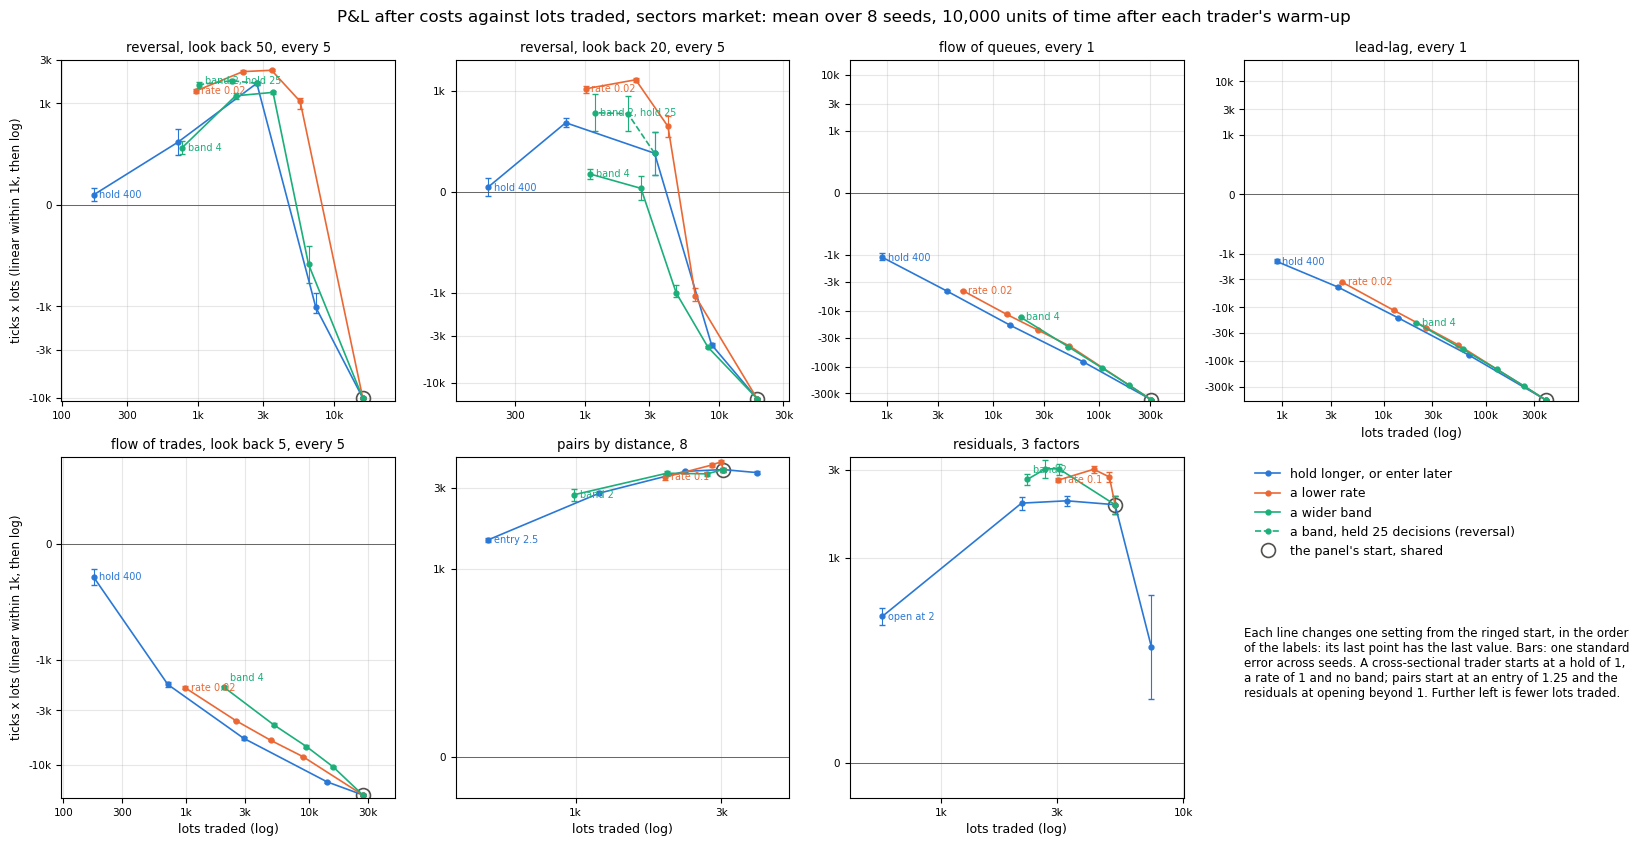

In [6]:
# Seven kinds of trader, each alone in the sectors market, and three ways to make each trade less: hold longer (or
# enter later), go only a share of the way to the target at a decision (a lower rate), or not trade within some lots of
# the aim (a wider band). The values were chosen on seeds 1 to 8: within each family, the best by P&L after costs summed
# over the two markets, for each way. The seeds here chose none of them.
from matplotlib.ticker import FixedLocator

LESS_SPAN = 10_000.0  # units of time of a run, after the trader's own warm-up and 100 more
LOADINGS, FACTORS = MARKETS['sectors']  # FACTORS: the true count, three


def pairs_by(**settings):
    # Section 3's eight pairs by distance, with some settings changed.
    return lambda factors: RelationTrader(choose=partial(pairs_by_distance, count=8), size=2.5, **{**Z, **settings})


def residuals_by(**settings):
    # Notebook 12's stat-arb on PCA residuals, with some settings changed.
    return lambda factors: ResidualTrader(
        factors=factors, interval=EVERY, size=5.0, window=400, close_long=0.0, close_short=0.0, **settings
    )


def cross_panel(kind, curves, **settings):
    # A cross-sectional trader of this kind, starting at the whole way to the target at every decision.
    return {
        'make': lambda **knobs: cross_section(kind, **settings, **knobs),
        'start': dict(hold=1, rate=1.0, band=0.0),
        'curves': curves,
    }


# A curve is the setting it changes, the values it takes in order, and the settings it holds other than the start's.
SLOWER = {
    'hold longer': ('hold', (1, 5, 25, 100, 400), {}),
    'a lower rate': ('rate', (1.0, 0.2, 0.1, 0.05, 0.02), {}),
    'a wider band': ('band', (0.0, 1.0, 2.0, 3.0, 4.0), {}),
}
BAND_HELD_25 = {'a band, held 25': ('band', (0.0, 1.0, 2.0), {'hold': 25})}
REVERSAL_CURVES = {**SLOWER, **BAND_HELD_25}
PANELS = {
    'reversal, look back 50, every 5': cross_panel(ReversalTrader, REVERSAL_CURVES, lookback=50, interval=5.0),
    'reversal, look back 20, every 5': cross_panel(ReversalTrader, REVERSAL_CURVES, lookback=20, interval=5.0),
    'flow of queues, every 1': cross_panel(FlowTrader, SLOWER, measure='queues', lookback=1, interval=1.0),
    'lead-lag, every 1': cross_panel(LeadLagTrader, SLOWER, lookback=1, interval=1.0),
    'flow of trades, look back 5, every 5': cross_panel(FlowTrader, SLOWER, measure='trades', lookback=5, interval=5.0),
    'pairs by distance, 8': {
        'make': pairs_by,
        'start': dict(entry=1.25, rate=1.0, band=0.0),
        'curves': {
            'enter later': ('entry', (1.0, 1.25, 1.5, 2.0, 2.5), {}),
            'a lower rate': ('rate', (1.0, 0.5, 0.25, 0.1), {}),
            'a wider band': ('band', (0.0, 0.5, 1.0, 2.0), {}),
        },
    },
    'residuals, 3 factors': {
        'make': residuals_by,
        'start': dict(open_at=1.0, rate=1.0, band=0.0),
        'curves': {
            'enter later': ('open_at', (0.75, 1.0, 1.25, 1.5, 2.0), {}),
            'a lower rate': ('rate', (1.0, 0.5, 0.25, 0.1), {}),
            'a wider band': ('band', (0.0, 1.0, 1.5, 2.0), {}),
        },
    },
}


def label_of(knobs):
    return ', '.join(f'{knob} {value:g}' for knob, value in knobs.items())


def points_of(panel, curve):
    # The settings along a curve, in the order of its values: the panel's start with the curve's changes.
    knob, values, held = panel['curves'][curve]
    return [{**panel['start'], **held, knob: value} for value in values]


# Every distinct setting of a panel, by its label, in order of first appearance: curves share their start, and a
# shared setting is run once.
TRIED = {
    name: {label_of(knobs): knobs for curve in panel['curves'] for knobs in points_of(panel, curve)}
    for name, panel in PANELS.items()
}
BURNS = {}  # a trader's own warm-up and 100 more, the same for every point of a panel
for name, panel in PANELS.items():
    warm_ups = {panel['make'](**knobs)(FACTORS).warm_up for knobs in TRIED[name].values()}
    assert len(warm_ups) == 1, f'{name}: a setting changed the warm-up'
    BURNS[name] = warm_ups.pop() + 100.0

jobs = [(name, label, seed) for name, tried in TRIED.items() for label in tried for seed in FEW]
results = Parallel(n_jobs=-1)(
    delayed(scored)(
        partial(PANELS[name]['make'](**TRIED[name][label]), FACTORS), LOADINGS, seed, BURNS[name], LESS_SPAN
    )
    for name, label, seed in jobs
)
ran = dict(zip(jobs, results, strict=True))
sweep_frame = pd.DataFrame(
    [
        {
            'panel': name,
            'curve': curve,
            'knob': knob,
            'value': value,
            'setting': label_of(knobs),
            'seed': seed,
            **ran[(name, label_of(knobs), seed)],
        }
        for name, panel in PANELS.items()
        for curve, (knob, values, _) in panel['curves'].items()
        for value, knobs in zip(values, points_of(panel, curve), strict=True)
        for seed in FEW
    ]
)
by_setting = sweep_frame.drop_duplicates(['panel', 'setting', 'seed']).groupby(['panel', 'setting'], sort=False)
sweep_table = by_setting.agg(
    pnl=('pnl', 'mean'),
    se=('pnl', lambda p: p.std() / math.sqrt(len(p))),
    positive=('pnl', lambda p: f'{(p > 0).sum()} of {len(p)}'),
    before_costs=('before_costs', 'mean'),
    costs=('costs', 'mean'),
    lots=('lots', 'mean'),
    gross=('gross', 'mean'),
    exposure=('exposure', 'mean'),
    risk_adjusted=('risk_adjusted', 'mean'),
)
sweep_table['cost_a_lot'] = sweep_table.costs / sweep_table.lots.replace(0, np.nan)

print(
    f"Sectors market, mean over {len(FEW)} seeds of {LESS_SPAN:,.0f} units of time after each trader's own warm-up and "
    '100 more. A setting is a hold (decisions between rebalances), a rate and a band, or an entry (the level to open '
    'at), a rate and a band.'
)
print('The burn, a warm-up and 100 more, in units of time:', {name: f'{burn:,.0f}' for name, burn in BURNS.items()})
for name in PANELS:
    print(f'\n{name}')
    print(shown(sweep_table.loc[name], 'entries'))

CURVE_STYLE = {
    'hold longer': (BLUE, '-'),
    'enter later': (BLUE, '-'),
    'a lower rate': (ORANGE, '-'),
    'a wider band': (AQUA, '-'),
    'a band, held 25': (AQUA, '--'),
}
PNL_TICKS = [-300_000, -100_000, -30_000, -10_000, -3_000, -1_000, 0, 1_000, 3_000, 10_000]  # 1, 3, 10 as the lots'
LOT_TICKS = [10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000, 300_000]  # 1, 3, 10: panels span decades
SETTING_WORD = {'open_at': 'open at'}


def kilo(x, _):
    return f'{x / 1000:,.0f}k' if x else '0'


def declutter(fig, notes):
    # Move up any label that overlaps one already placed, from the lowest, until it does not.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    placed = []
    for note in sorted(notes, key=lambda n: n.get_window_extent(renderer).y0):
        for _ in range(40):
            box = note.get_window_extent(renderer)
            hits = [other.get_window_extent(renderer) for other in placed]
            hits = [other for other in hits if box.overlaps(other)]
            if not hits:
                break
            dx, dy = note.xyann
            note.xyann = (dx, dy + (max(other.y1 for other in hits) - box.y0) * 72 / fig.dpi + 0.5)
        placed.append(note)


fig, axes = plt.subplots(2, 4, figsize=(17, 8.6), sharey=False)
ends = {}  # the last point of each curve, with its label
for ax, name in zip(axes.flat[:7], PANELS, strict=True):
    panel, rows = PANELS[name], sweep_table.loc[name]
    ends[name] = []
    for curve, (knob, values, held) in panel['curves'].items():
        color, style = CURVE_STYLE[curve]
        along = rows.loc[[label_of(knobs) for knobs in points_of(panel, curve)]]
        ax.errorbar(
            along.lots,
            along.pnl,
            yerr=along.se,
            color=color,
            ls=style,
            marker='o',
            ms=3.5,
            lw=1.2,
            capsize=2,
            elinewidth=0.8,
        )
        text = ', '.join(f'{SETTING_WORD.get(k, k)} {v:g}' for k, v in {knob: values[-1], **held}.items())
        ends[name].append((text, along.lots.iloc[-1], along.pnl.iloc[-1], color))
    start = rows.loc[label_of(panel['start'])]
    ax.plot(start.lots, start.pnl, ls='none', marker='o', ms=10, mfc='none', mec=GRAY, mew=1.2)
    ax.axhline(0, color=GRAY, lw=0.6)
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1_000)  # since some lose a hundred times what others make
    ax.margins(x=0.12)
    ax.minorticks_off()
    ax.xaxis.set_major_locator(FixedLocator(LOT_TICKS))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:g}k' if x >= 1000 else f'{x:g}'))
    ax.yaxis.set_major_locator(FixedLocator(PNL_TICKS))
    ax.yaxis.set_major_formatter(FuncFormatter(kilo))
    ax.tick_params(labelsize=7.5)
    ax.set_title(name, fontsize=9.5)
for ax in axes[1, :3]:
    ax.set_xlabel('lots traded (log)', fontsize=9)
axes[0, 3].set_xlabel('lots traded (log)', fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel('ticks x lots (linear within 1k, then log)', fontsize=8.5)

key = axes[1, 3]
key.axis('off')
for label, color, style in (
    ('hold longer, or enter later', BLUE, '-'),
    ('a lower rate', ORANGE, '-'),
    ('a wider band', AQUA, '-'),
    ('a band, held 25 decisions (reversal)', AQUA, '--'),
):
    key.plot([], [], color=color, ls=style, marker='o', ms=3.5, lw=1.2, label=label)
key.plot([], [], ls='none', marker='o', ms=10, mfc='none', mec=GRAY, mew=1.2, label="the panel's start, shared")
key.legend(loc='upper left', frameon=False, fontsize=9)
key.text(
    0.0,
    0.5,
    'Each line changes one setting from the ringed start, in the order\n'
    'of the labels: its last point has the last value. Bars: one standard\n'
    'error across seeds. A cross-sectional trader starts at a hold of 1,\n'
    'a rate of 1 and no band; pairs start at an entry of 1.25 and the\n'
    'residuals at opening beyond 1. Further left is fewer lots traded.',
    transform=key.transAxes,
    fontsize=8.5,
    va='top',
)
fig.suptitle(
    f'P&L after costs against lots traded, sectors market: mean over {len(FEW)} seeds, {LESS_SPAN:,.0f} units of time '
    "after each trader's warm-up",
    fontsize=12,
)
fig.tight_layout()
notes = []
for ax, name in zip(axes.flat[:7], PANELS, strict=True):
    for text, x, y, color in ends[name]:
        right = ax.transAxes.inverted().transform(ax.transData.transform((x, y)))[0] > 0.7
        notes.append(
            ax.annotate(
                text,
                (x, y),
                xytext=(-4 if right else 4, 0),
                textcoords='offset points',
                ha='right' if right else 'left',
                va='center',
                fontsize=7,
                color=color,
            )
        )
declutter(fig, notes)
plt.show()

**Reversal pays on every curve, and at a look back of 50 more than at 20.** At a look back of 50, a rebalance at every decision loses 10,056 (se 166) on 16,207 lots. Holding for 25 decisions makes +1,662 (se 68) on 2,700 lots; a rate of 0.1 makes +2,308 (se 65) on 3,468; a band of 2 makes +1,322 (se 38) on 3,553; and a band of 1 held for 25 decisions makes +1,772 (se 92) on 1,774, about what the hold makes on about two thirds of its lots. Each is positive on all eight seeds. At a look back of 20 the best of each curve is lower: +686 (se 45) at a hold of 100, +1,333 (se 63) at a rate of 0.05, +177 (se 54, 7 of 8 seeds) at a band of 4, and +785 (se 185) at a band of 2 held for 25 decisions. A band alone, at a hold of 1, loses at the narrow widths: at a look back of 20, 4,000 (se 124) at 1 and 1,016 (se 95) at 2; at 50, 585 (se 180) at 1.

**The flow of queues, lead-lag and the flow of trades never pay, however they are traded less.** They lose at every setting on their curves, and on every one of the eight seeds (0 of 8 at each). The least loss is at the longest hold, which trades the fewest lots: 1,102 (se 141) on 896 lots for the queues, 1,376 (se 124) on 877 for lead-lag and 288 (se 71) on 177 for the trades. The lowest rate, 0.02, loses 4,341 (se 50), 3,371 (se 65) and 1,838 (se 63), on 5,135, 3,878 and 981 lots; the widest band, 4, loses 12,995 (se 74), 19,252 (se 93) and 1,816 (se 53), on 18,128, 20,761 and 2,029. Trading them less shrinks the loss toward nothing, and leaves almost nothing before costs: at a hold of 400 the three make +153, -260 and -71. Where they are traded more they make more before costs (the queues +856 at a rate of 0.02 and +6,276 at a band of 4), and pay more than that in costs; the before-cost figure at high turnover holds the trader's own impact (see the limitations).

**For pairs the start is hard to beat, and a rate of 0.5 does it by a little.** From an entry of 1 to 1.5 the P&L is about the same (+3,699, se 83; +3,856, se 103, at the start of 1.25; +3,764, se 74) on fewer lots the later it enters (3,927, 3,042 and 2,284), and from 2 it falls (+2,799, se 75, on 1,198 lots; +1,479, se 40, on 517 at 2.5). A rate of 0.5, with the entry at 1.25, makes more than the start on about its lots: +4,288 (se 97) on 2,994 lots, against +3,856 (se 103) on 3,042. A rate of 0.25 makes +4,100 (se 92) on 2,788, which is less clear. These are differences of means on the same eight seeds, not paired by seed: the gain is about three of their combined standard errors for a rate of 0.5 and under two for 0.25. A rate of 0.1 makes less (+3,480, se 136). No band beats none: +3,638 (se 110) at 0.5, +3,670 (se 127) at 1 and +2,737 (se 221) at 2.

**Residuals gain most from a rate or a band.** The start, opening beyond 1, makes +1,947 (se 215) on 5,235 lots, and no later entry does much better: +2,044 (se 130), beyond 1.25, on 3,306 lots. A rate of 0.25 makes +3,029 (se 126) on 4,275 lots, a band of 1 makes +3,046 (se 208) on 3,066 and a band of 1.5 makes +3,045 (se 337) on 2,698, each positive on all eight seeds. Every rate tried (0.5 to 0.1) makes +2,649 to +3,029, and every band (1 to 2) +2,669 to +3,046.

**A lot costs about a tick at every rate below 1.** In all seven panels, every point with a rate below 1 costs 0.99 to 1.04 ticks a lot, and every point with a rate of 1 and no band, the starts and every longer hold or later entry among them, costs 1.05 to 1.56. A band's lots cost 0.99 to 1.44. In the five cross-sectional panels they cost 0.99 to 1.06 at a band of 4 and up to 1.44 at narrower ones (the queues at 1); in the pairs' and residuals' panels, whose bands go to 2, they cost 1.12 to 1.22. The table of orders after the test shows why: with a rate, a trader's orders are of one lot. And it does not decide the P&L: the queues at a rate of 0.02 pay 1.01 a lot and lose 4,341 (se 50) on 5,135 lots, about what a hold of 100 loses, 4,410 (se 254), on 3,636 lots at 1.38 a lot.

**A rate or a band holds less, and a longer hold does not.** In the five cross-sectional panels the trader holds 25.3 to 26.4 lots at the start and 24.7 to 27.2 at every hold. At a rate of 0.02 it holds 8.7, 5.4, 3.2, 1.7 and 3.4 lots (reversal at 50 and at 20, the queues, lead-lag, the trades), and at a band of 4, 4.1, 4.1, 4.7, 4.0 and 4.0. So a rate or a band changes what is held as well as how often it is traded.

**In five panels a band raises the exposure to the factors, and a rate does not.** In the panels of reversal at 50 and at 20, the flow of trades, pairs and residuals, a band raises it at most of its widths: to 3.3 lots for reversal at a band of 2 at either look back, 3.4 for the trades at 2, 4.1 for pairs at 2 and 3.8 for residuals at 1, against starts of 1.6 (reversal at either look back, and the trades), 1.3 and 2.1. In those five a rate leaves it within 0.2 of its start at every rate. In the queues' and lead-lag's panels, which start at 4.8 and 5.2, a band lowers it at every width (to 2.7 and 2.5 at 4), and so does a rate (to 1.6 and 1.3 at 0.02).

**The best point of a curve is the best of three to five on the seeds that report it.** It flatters its curve, and the conclusions below list them. The test, whose settings were chosen on seeds 1 to 8 and not as the best of a curve on the seeds that report it, and which adds the mixed market and four more seeds to the frontier's eight, says how much of it holds.

P&L over 20,000 units of time after a burn of 10,465, on seeds 101 to 112: the same as section 3's, whose row for each family comes first.
Entries are the states a trader asked for, which with a rate or a band is not the number of trades: lots is.

sectors
                                                      pnl     se  positive  before_costs    costs     lots  cost_a_lot  entries  gross  exposure  risk_adjusted
trader                                                                                                                                                         
reversal, look back 20, hold 100, every 5           968.0  106.0  12 of 12        2779.0   1811.0   1439.0        1.26    240.0   25.2       1.7          0.007
reversal, look back 50, hold 25, every 5           3485.0  142.0  12 of 12       10076.0   6591.0   5418.0        1.22    876.0   25.5       1.7          0.022
reversal, look back 50, rate 0.1, every 5          4364.0  109.0  12 of 12       11314.0   6950.0   698

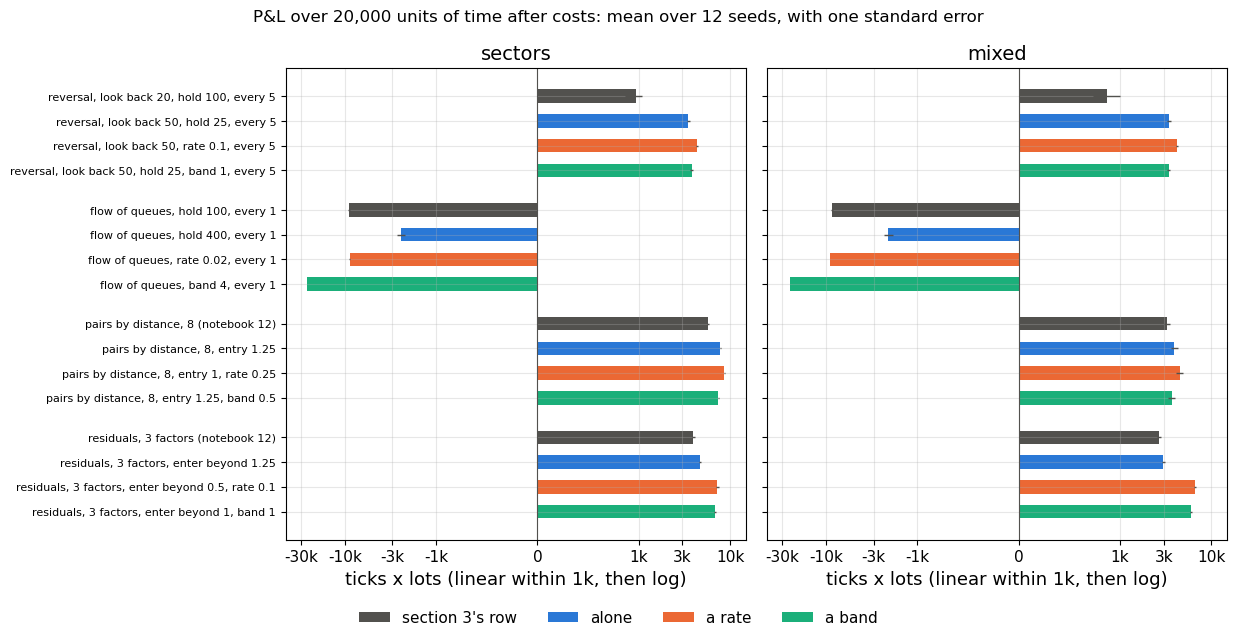

In [7]:
# Settings chosen on seeds 1 to 8, as the frontier's were. Both markets and the twelve seeds, the burn and the span of
# section 3, so that its rows and these compare to the tick.
LESS_TRADERS = {
    'reversal, look back 50, hold 25, every 5': cross_section(ReversalTrader, lookback=50, hold=25, interval=5.0),
    'reversal, look back 50, rate 0.1, every 5': cross_section(
        ReversalTrader, lookback=50, hold=1, rate=0.1, interval=5.0
    ),
    'reversal, look back 50, hold 25, band 1, every 5': cross_section(
        ReversalTrader, lookback=50, hold=25, band=1.0, interval=5.0
    ),
    'flow of queues, hold 400, every 1': cross_section(
        FlowTrader, lookback=1, hold=400, interval=1.0, measure='queues'
    ),
    'flow of queues, rate 0.02, every 1': cross_section(
        FlowTrader, lookback=1, hold=1, rate=0.02, interval=1.0, measure='queues'
    ),
    'flow of queues, band 4, every 1': cross_section(
        FlowTrader, lookback=1, hold=1, band=4.0, interval=1.0, measure='queues'
    ),
    'pairs by distance, 8, entry 1.25': pairs_by(entry=1.25),
    'pairs by distance, 8, entry 1, rate 0.25': pairs_by(entry=1.0, rate=0.25),
    'pairs by distance, 8, entry 1.25, band 0.5': pairs_by(entry=1.25, band=0.5),
    'residuals, 3 factors, enter beyond 1.25': residuals_by(open_at=1.25),
    'residuals, 3 factors, enter beyond 0.5, rate 0.1': residuals_by(open_at=0.5, rate=0.1),
    'residuals, 3 factors, enter beyond 1, band 1': residuals_by(open_at=1.0, band=1.0),
}
WAYS = ('alone', 'a rate', 'a band')  # alone: only the hold or the entry changed
REFERENCES = {  # each family, with the row of section 3's table it is set against
    'reversal': 'reversal, look back 20, hold 100, every 5',
    'queues': 'flow of queues, hold 100, every 1',
    'pairs': 'pairs by distance, 8 (notebook 12)',
    'residuals': 'residuals, 3 factors (notebook 12)',
}
listed = list(LESS_TRADERS)
NEW = {  # each family's three new rows by way
    family: dict(zip(WAYS, listed[3 * i : 3 * i + 3], strict=True)) for i, family in enumerate(REFERENCES)
}
assert all(family in name for family, ways in NEW.items() for name in ways.values())
# The burn must not cut into any trader's warm-up: section 3's burn is its longest warm-up and 400 more.
assert all(make(3).warm_up <= BURN - 400.0 for make in LESS_TRADERS.values()), 'the burn cuts into a warm-up'
assert all(make(3).netted for make in LESS_TRADERS.values()), 'a trader that does not net its orders'

less_frame, less_table = compare(LESS_TRADERS, BURN)


def family_rows(market):
    # Section 3's row for each family, then its three new rows.
    parts = []
    for family, reference in REFERENCES.items():
        parts.append(table.loc[market].loc[[reference]])
        parts.append(less_table.loc[market].loc[list(NEW[family].values())])
    return pd.concat(parts)


print(
    f'P&L over {SPAN:,.0f} units of time after a burn of {BURN:,.0f}, on seeds {SEEDS[0]} to {SEEDS[-1]}: the same as '
    "section 3's, whose row for each family comes first."
)
print('Entries are the states a trader asked for, which with a rate or a band is not the number of trades: lots is.')
for market in MARKETS:
    print(f'\n{market}')
    print(shown(family_rows(market)))

# Paired differences: the same market and seed, one trader less another, from section 3's frame and this one.
by_seed = pd.concat([frame, less_frame]).set_index(['market', 'trader', 'seed']).sort_index()
assert by_seed.index.is_unique
COMPARISONS = {
    'a rate less alone': lambda family: (NEW[family]['a rate'], NEW[family]['alone']),
    'a band less alone': lambda family: (NEW[family]['a band'], NEW[family]['alone']),
    "alone less section 3's row": lambda family: (NEW[family]['alone'], REFERENCES[family]),
}


def difference(market, one, other, column):
    return by_seed.loc[(market, one), column] - by_seed.loc[(market, other), column]  # by seed


paired_rows = []
for family in REFERENCES:
    for market in MARKETS:
        for comparison, pick in COMPARISONS.items():
            pnl = difference(market, *pick(family), 'pnl')
            risk = difference(market, *pick(family), 'risk_adjusted')
            paired_rows.append(
                {
                    'family': family,
                    'market': market,
                    'comparison': comparison,
                    'pnl': pnl.mean(),
                    'se': pnl.sem(),
                    'positive': f'{(pnl > 0).sum()} of {len(pnl)}',
                    'risk_adjusted': risk.mean(),
                    'risk_se': risk.sem(),
                    'risk_positive': f'{(risk > 0).sum()} of {len(risk)}',
                }
            )
paired = pd.DataFrame(paired_rows)
print(
    f'\nPaired differences, one trader less another on the same market and seed: mean, its se across the {len(SEEDS)} '
    'seeds, and the seeds above 0'
)
print(
    paired.set_index(['family', 'market', 'comparison'])
    .round({'pnl': 0, 'se': 0, 'risk_adjusted': 3, 'risk_se': 3})
    .to_string()
)

SECTION_3 = "section 3's row"
ROLE_COLORS = {SECTION_3: GRAY, 'alone': BLUE, 'a rate': ORANGE, 'a band': AQUA}
ORDER = [
    (role, name)
    for family, reference in REFERENCES.items()
    for role, name in ((SECTION_3, reference), *NEW[family].items())
]
places = [-(i + 0.6 * (i // 4)) for i in range(len(ORDER))]  # four rows to a family, with a gap between families
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.4), sharex=True, sharey=True)
for ax, market in zip(axes, MARKETS, strict=True):
    rows = pd.concat([table.loc[market], less_table.loc[market]])
    for role, color in ROLE_COLORS.items():
        picks = [i for i, (kind, _) in enumerate(ORDER) if kind == role]
        got = rows.loc[[ORDER[i][1] for i in picks]]
        ax.barh(
            [places[i] for i in picks],
            got.pnl,
            xerr=got.se,
            height=0.55,
            color=color,
            error_kw=dict(ecolor=GRAY, lw=1),
            label=role,
        )
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_yticks(places, [name for _, name in ORDER], fontsize=8)
    ax.set_title(market)
    ax.set_xlabel('ticks x lots (linear within 1k, then log)')
    ax.set_xscale('symlog', linthresh=1_000)  # since some lose a hundred times what others make
    ax.xaxis.set_major_locator(FixedLocator(PNL_TICKS))
    ax.minorticks_off()
    ax.xaxis.set_major_formatter(FuncFormatter(kilo))
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(
    f'P&L over {SPAN:,.0f} units of time after costs: mean over {len(SEEDS)} seeds, with one standard error',
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False)
plt.show()

In [8]:
# What a lot costs by the size of the order it went in. A market that keeps each order of its one trader: the lots it
# filled and what crossing the spread cost them, as lob.statarb's _trade counts them. Each of the test's twelve traders,
# in the sectors market, on three of its seeds, over its span after the same burn.
class Ledger(BookMarket):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.orders = []

    def _trade(self, trader, book, need):
        lots, paid = trader.lots, trader.spread_paid
        super()._trade(trader, book, need)
        if trader.lots > lots:
            self.orders.append((trader.lots - lots, trader.spread_paid - paid))


ORDER_SEEDS = SEEDS[:3]
SIZES = {'1 lot': (1, 1), '2 or 3': (2, 3), '4 or 5': (4, 5), '6 or more': (6, math.inf)}


def orders_of(name, seed):
    loadings, factors = MARKETS['sectors']
    trader = LESS_TRADERS[name](factors)
    market = Ledger(FactorValues(loadings), seed=seed, traders=(trader,))
    while market.time < BURN:
        market.step()
    market.orders.clear()  # score_portfolio counts from here
    score = score_portfolio(market, trader, BURN, SPAN)
    filled = np.array(market.orders, dtype=float).reshape(-1, 2)
    assert filled[:, 0].sum() == score['lots'], 'the ledger misses lots'
    assert abs(filled[:, 1].sum() - score['costs']) < 1e-6 * max(1.0, score['costs']), 'the ledger misses costs'
    return [{'trader': name, 'seed': seed, 'lots': lots, 'cost': cost} for lots, cost in filled]


ran = Parallel(n_jobs=-1)(delayed(orders_of)(name, seed) for name in LESS_TRADERS for seed in ORDER_SEEDS)
ledger = pd.DataFrame([row for rows in ran for row in rows])
ledger['size'] = pd.cut(ledger.lots, [0.5, 1.5, 3.5, 5.5, math.inf], labels=list(SIZES))
by_size = ledger.groupby(['trader', 'size'], sort=False, observed=False).agg(lots=('lots', 'sum'), cost=('cost', 'sum'))
lots_share = (by_size.lots / by_size.lots.groupby(level=0, sort=False).transform('sum')).unstack('size')
cost_a_lot_by_size = (by_size.cost / by_size.lots.replace(0, np.nan)).unstack('size')
whole = ledger.groupby('trader', sort=False).agg(lots=('lots', 'sum'), cost=('cost', 'sum'), orders=('lots', 'size'))
summary = pd.DataFrame(
    {
        'orders': whole.orders / len(ORDER_SEEDS),
        'lots': whole.lots / len(ORDER_SEEDS),
        'lots an order': ledger.groupby('trader', sort=False).apply(lambda g: (g.lots**2).sum() / g.lots.sum()),
        'cost a lot': whole.cost / whole.lots,
    }
).loc[list(LESS_TRADERS)]
print(
    f'Sectors market, seeds {ORDER_SEEDS[0]} to {ORDER_SEEDS[-1]}, each over {SPAN:,.0f} units after the burn: '
    'orders and lots a run, the lots of the order a lot went in (its mean), and what a lot cost'
)
print(summary.round({'orders': 0, 'lots': 0, 'lots an order': 1, 'cost a lot': 2}).to_string())
print('\nThe share of its lots that went in orders of each size')
print(lots_share.loc[list(LESS_TRADERS)].round(2).to_string())
print('\nWhat a lot cost, in ticks, in orders of each size (NaN: no order of that size)')
print(cost_a_lot_by_size.loc[list(LESS_TRADERS)].round(2).to_string())


Sectors market, seeds 101 to 103, each over 20,000 units after the burn: orders and lots a run, the lots of the order a lot went in (its mean), and what a lot cost
                                                   orders     lots  lots an order  cost a lot
trader                                                                                       
reversal, look back 50, hold 25, every 5           1692.0   5357.0            4.4        1.22
reversal, look back 50, rate 0.1, every 5          7025.0   7025.0            1.0        0.99
reversal, look back 50, hold 25, band 1, every 5   1319.0   3586.0            3.7        1.21
flow of queues, hold 400, every 1                   536.0   1860.0            4.8        1.40
flow of queues, rate 0.02, every 1                10370.0  10370.0            1.0        1.01
flow of queues, band 4, every 1                   32707.0  36087.0            1.2        1.07
pairs by distance, 8, entry 1.25                   2488.0   6085.0            2.7   

**Most of the differences below compare a family's bests, and not one setting changed.** The best with a rate or with a band was chosen on seeds 1 to 8 with its own hold or entry. So *a rate less alone* is, for reversal, a rate of 0.1 at a hold of 1 against a hold of 25; for the queues, a rate of 0.02 at a hold of 1 against a hold of 400, and a band of 4 likewise; for pairs, an entry of 1 with a rate of 0.25 against an entry of 1.25; and for the residuals, entering beyond 0.5 with a rate of 0.1, and beyond 1 with a band of 1, against beyond 1.25. Only reversal's band, added to a hold of 25, and pairs' band, added to an entry of 1.25, change one thing. The frontier's panels change one setting at a time from their starts (except the dashed curve for reversal, which holds 25 and changes the band), and are where to read what a rate does alone for pairs and residuals. Section 3's row differs from the best alone as well: reversal's look back of 20 and hold of 100 against 50 and 25, the queues' hold of 100 against 400, the pairs' entry of 2 against 1.25 (earlier, not later) and the residuals' beyond 1.5 against 1.25 (earlier too).

**Reversal at a look back of 50 pays more than three times what section 3's reversal does, and a rate pays most.** In the sectors market its best alone, held for 25 decisions, makes +3,485 (se 142) on 5,418 lots, against section 3's +968 (se 106) on 1,439: +2,517 (se 147, 12 of 12 seeds positive) more, and +0.015 (se 0.001, 12 of 12) per unit of risk. In the mixed market it makes +3,430 (se 138) against +868 (se 138), +2,562 (se 156, 12 of 12) more, and +0.018 (se 0.001, 12 of 12) per unit of risk. Section 3's small grid did not try a look back of 50 or a hold of 25. With a rate of 0.1 it makes +4,364 (se 109) and +4,203 (se 68), on 6,982 and 6,629 lots: +879 (se 208, 12 of 12) and +773 (se 151, 11 of 12) more than alone, and +0.017 (se 0.002) and +0.018 (se 0.001) per unit of risk, on 12 of 12 seeds in both markets. A band of 1 on the hold of 25 changes the P&L by +305 (se 145, 8 of 12 seeds positive) and -31 (se 138, 7 of 12), on about two thirds of the lots (3,602 and 3,378), and per unit of risk by +0.009 (se 0.001, 12 of 12) and +0.007 (se 0.001, 11 of 12).

**The flow of queues loses in every row, and holding longer loses least.** No row makes money on any seed in either market (0 of 12 each). Section 3's hold of 100 loses 9,047 (se 250) in the sectors market and 8,658 (se 238) in the mixed. A hold of 400 loses 2,430 (se 244) and 2,087 (se 236): +6,616 (se 336) and +6,571 (se 408) better, on 12 of 12 seeds, and +0.037 (se 0.002) and +0.041 (se 0.003) per unit of risk. A rate of 0.02 loses 8,823 (se 68) and 9,058 (se 66), about what section 3's row loses; against the hold of 400 the difference is -6,392 (se 258) and -6,972 (se 235), on 10,313 and 10,416 lots against 1,830 and 1,817. A band of 4 loses 25,862 (se 98) and 24,786 (se 66), on 36,249 and 33,966 lots. At these values, then, a rate or a band trades the queues more than a longer hold does, and loses more.

**Pairs earn more by entering earlier than section 3's, on more lots and less per unit of risk.** Entering at 1.25 makes +7,808 (se 91) against section 3's +5,706 (se 81) in the sectors market: +2,102 (se 84, 12 of 12 seeds positive) more, on 5,997 lots against 2,387, and -0.008 (se 0.001, 0 of 12) per unit of risk (0.062 against 0.070). In the mixed market it is +634 (se 99, 12 of 12) more, on 3,090 lots against 1,478, and -0.003 (se 0.001, 2 of 12).

**A rate adds a little to pairs, and a band takes a little away.** Entering at 1 with a rate of 0.25 makes +8,639 (se 105) and +4,484 (se 367), on 6,770 and 3,673 lots: +832 (se 86) and +566 (se 72) more than entering at 1.25 alone, on 12 of 12 seeds in both markets, and +0.006 (se 0.001) and +0.004 (se 0.001) per unit of risk, also on 12 of 12. That changes the entry along with the rate. The frontier's pairs panel, at an entry of 1.25, gives the rate alone: +4,288 (se 97) at 0.5 and +4,100 (se 92) at 0.25, against +3,856 (se 103) at 1. A band of 0.5 on the entry of 1.25 differs from alone by -418 (se 101, 1 of 12 seeds positive) and -232 (se 63, 1 of 12), on 5,383 and 2,772 lots against 5,997 and 3,090, and by +0.004 (se 0.001, 11 of 12) and +0.001 (se 0.001, 8 of 12) per unit of risk. Per unit of risk no pairs row beats section 3's in the sectors market (0.062, 0.068 and 0.066 against 0.070); in the mixed market only the rate's does (0.040 against 0.038).

**Residuals gain a little from entering earlier, and a great deal more from a rate or a band.** Entering beyond 1.25, where section 3's enter beyond 1.5, makes +4,625 (se 131) against +3,952 (se 143) in the sectors market: +674 (se 96, 11 of 12 seeds positive) more, on 7,042 lots against 4,296, and -0.002 (se 0.001, 2 of 12) per unit of risk. In the mixed market it is +296 (se 88, 10 of 12) more, and -0.003 (se 0.001, 1 of 12). Entering beyond 0.5 with a rate of 0.1 makes +7,223 (se 232) and +6,544 (se 154): +2,597 (se 207) and +3,562 (se 151) more than alone, on 12 of 12 seeds in both markets, and +0.009 (se 0.001) and +0.018 (se 0.001) per unit of risk, also on 12 of 12. Entering beyond 1 with a band of 1 makes +6,768 (se 150) and +6,037 (se 152): +2,142 (se 160) and +3,055 (se 179) more, on 12 of 12, and +0.012 (se 0.001) and +0.020 (se 0.001) per unit of risk, also on 12 of 12, on fewer lots than the rate's (6,366 and 6,244 against 9,129 and 8,880). Both beat section 3's row per unit of risk (0.039 and 0.042 against 0.033 in the sectors market, 0.039 and 0.041 against 0.024 in the mixed), though the rate holds 35.5 and 36.3 lots against section 3's 15.1 and 16.7.

**A rate's lots are the cheapest in every family.** With a rate a lot costs 1.00, 1.01, 1.00 and 1.00 ticks in the sectors market (reversal, the queues, pairs, residuals) and 0.96, 0.97, 0.95 and 0.96 in the mixed, against 1.03 to 1.39 in every other row, section 3's included. The frontier has every rate's lots at 0.99 to 1.04, as cheap as a band of 4's in the panels of reversal and the trades (0.99 to 1.00) and cheaper than any other point's in its panel. **The reason is the size of the orders.** In the table of orders (the sectors market, seeds 101 to 103), every order of a trader with a rate is for one lot, except 5% of the pairs' lots, which go in orders of two or three. A one-lot order fills at the best quote and pays half the spread: 0.98 to 1.02 ticks, whoever sends it. A hold sends larger orders, of 2.7 to 4.8 lots on average for the lot in it, and a band of 0.5 or 1 nearly as large (2.4 to 3.7); only the queues' band of 4, which trades whatever lies beyond it as each decision comes, sends mostly one-lot orders (81% of its lots, at 1.07 a lot). What a lot costs grows with the order, as a larger order takes the best quote and walks on into the book: reversal held for 25 pays 0.98 in one-lot orders, 1.09 in orders of two or three, 1.21 in four or five and 1.42 in six or more, and the pairs entering at 1.25 pay 1.15, 1.44 and 2.52 from two lots up. A rate splits each change into one-lot orders over the decisions that follow, and so pays only the half spread, the part of the cost in proportion to the lots.

It does not make a rate pay by itself: the queues' rate costs 1.01 a lot, and its 10,418 of costs on 10,313 lots are about what section 3's row pays (10,214, on 7,340 lots at 1.39).

**A band raises the exposure to the factors for the residuals and reversal.** The residuals' band holds 3.8 and 3.5 lots of it (root mean square), against 1.8 and 2.2 for the best alone and 1.6 and 1.9 in section 3's rows. Reversal's band holds 2.8 and 2.3, against 1.7 and 1.7 alone. A rate holds 2.2 and 2.7 for the residuals and 1.6 and 1.6 for reversal. The queues' band holds less, 2.7 and 2.1 against 3.7 and 4.2 at a hold of 400, and pairs' band holds less in the sectors market (0.9 against 1.3) and the same in the mixed (3.5 against 3.6).

**The two markets agree.** Every difference has the same sign in the mixed market as in the sectors market, on P&L and per unit of risk, except reversal's band on P&L, which is small in both (+305, se 145, and -31, se 138). Per unit of risk, a rate or a band beats section 3's rows for reversal and the residuals (so does reversal's best alone), and not for pairs (except a rate in the mixed market); the queues gain from holding longer, and from nothing else.

### In a Backtest's Terms

The scorecard and signal chart of three of the test's traders, in the sectors market on seed 101, as in section 4: reversal with a rate of 0.1 (look back 50, 5 lots of the largest), eight pairs by distance entering at 1 with a rate of 0.25 (2.5 lots of each pair), and stat-arb on PCA residuals opening beyond 1 with a band of 1 lot (5 lots a book), each deciding every 5 units. Each card runs from its trader's first order to the end of the run, and the tables count only the last 20,000 units, so a card's figure differs from its table's.

**The records agree with the fills.** Each card's record makes what its fills made, to within 1: +5,705 and +5,706 for reversal, +9,294 and +9,295 for the pairs, +9,359 and +9,360 for the residuals. The tables' figures for the same runs are +3,629, +9,175 and +6,305, in that order.

**The residuals' card holds more than its capital at its most.** It holds 1.10 times the capital of 150,000, above 1 on 0.1% of days, where the reversal and pairs cards hold 0.72 at their most, above 1 on 0.0% of days; none of section 4's cards held more than 0.99. On those days the residuals' figure is leveraged.

**In the charts, the positions move in small steps, and the residuals' mostly stays put.** Reversal's position in book 9, and the pairs' in book 9 (the first pair's largest leg), are built and unwound a little at a time. The residuals' position in book 0 mostly stays at one size through its long runs short and long, while its s-score moves.

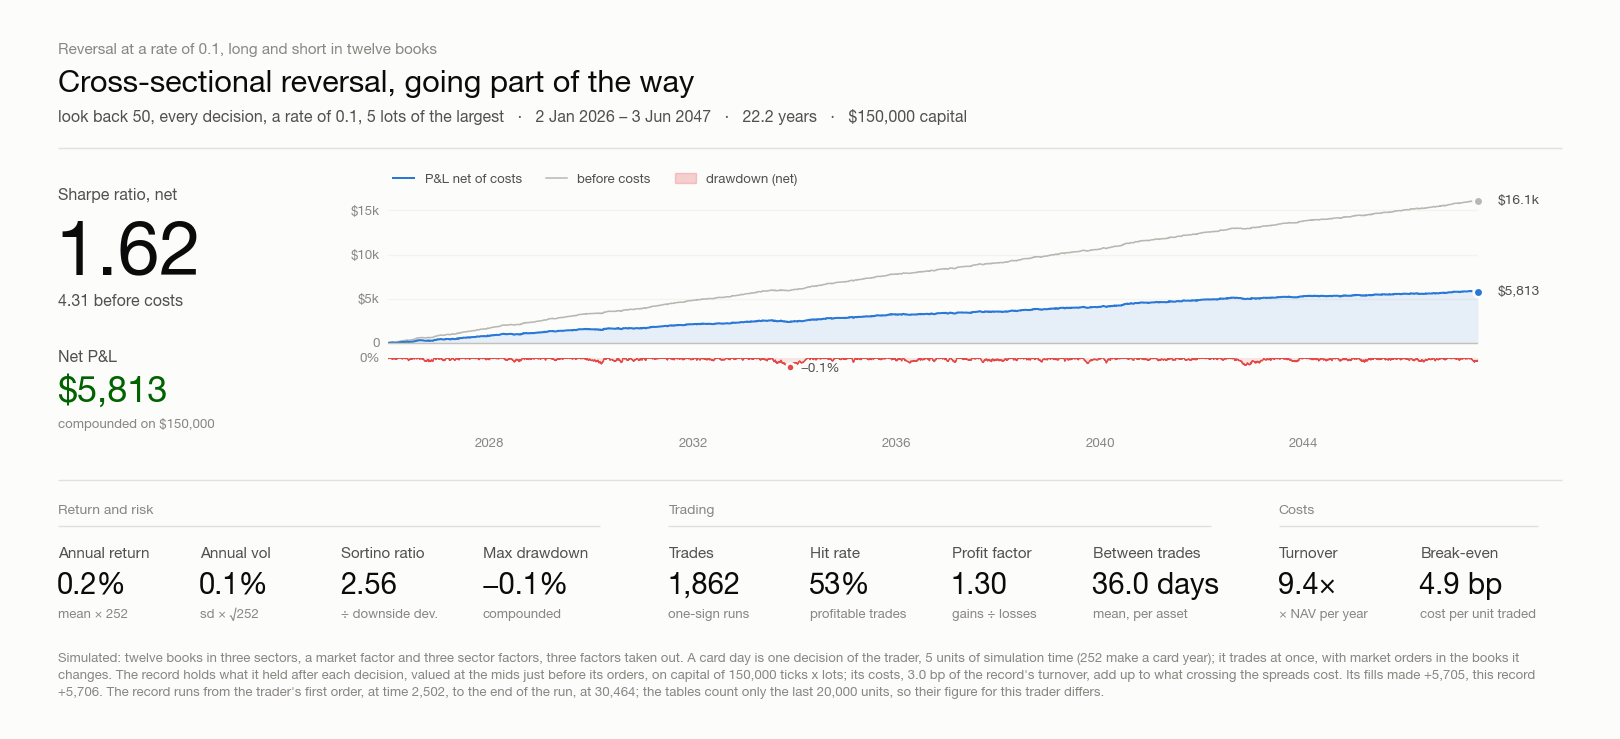

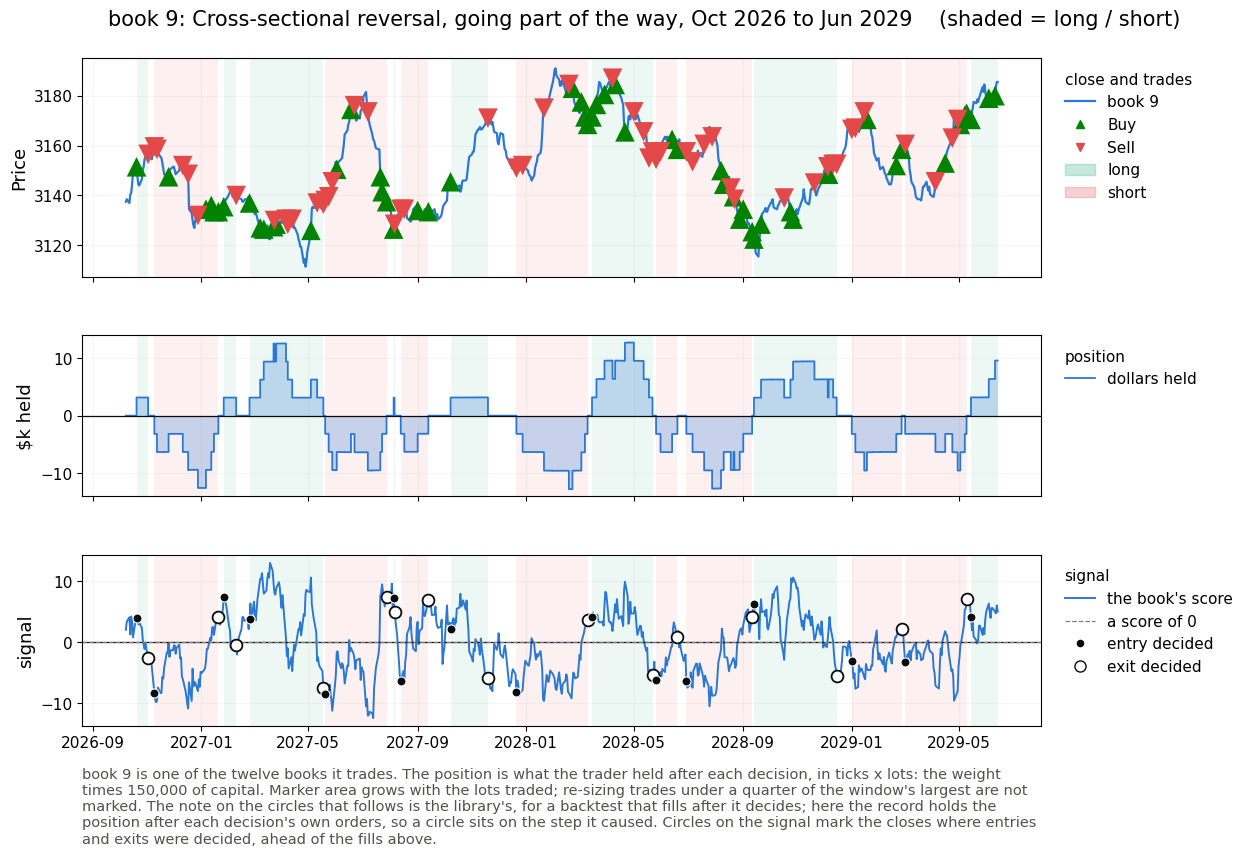

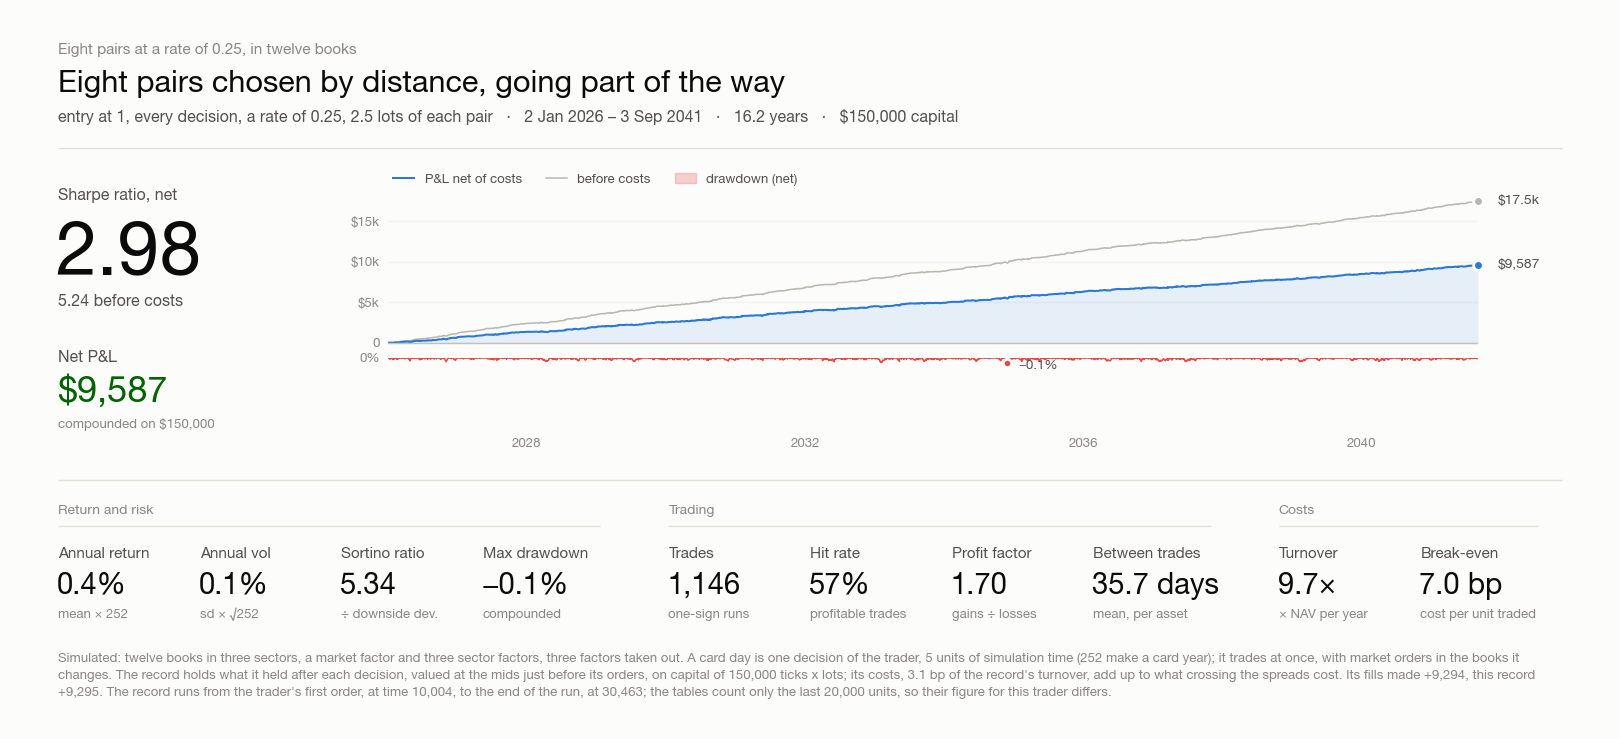

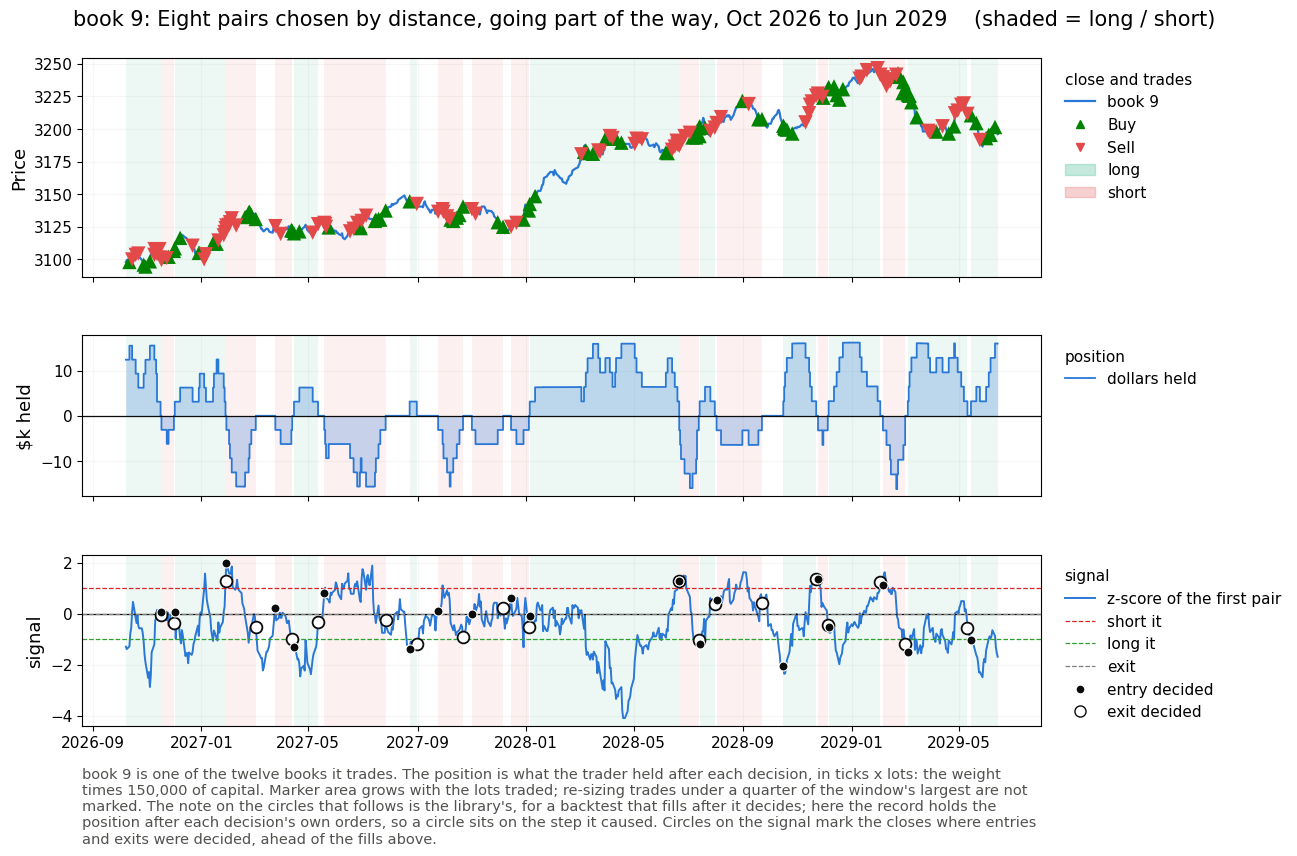

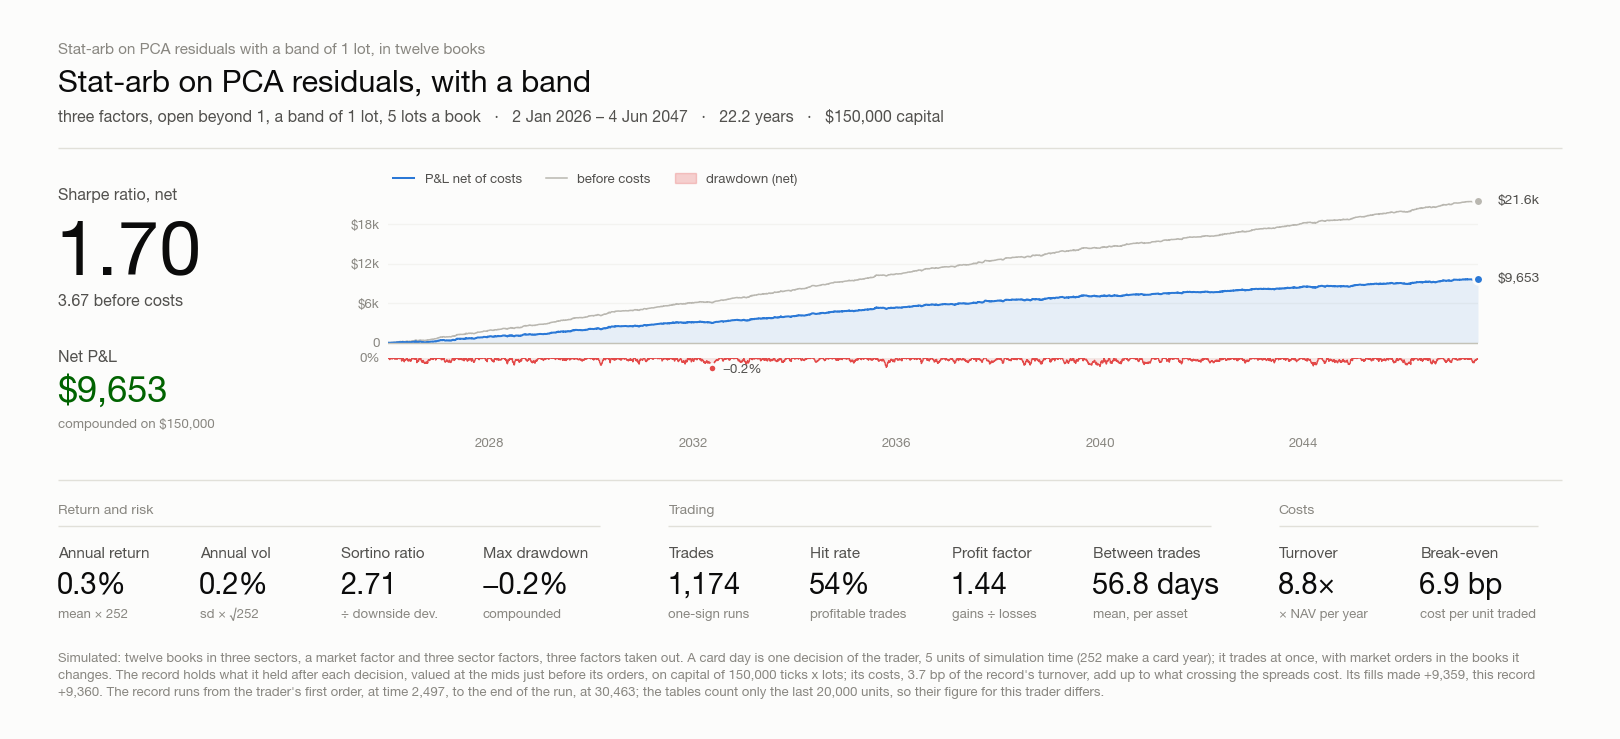

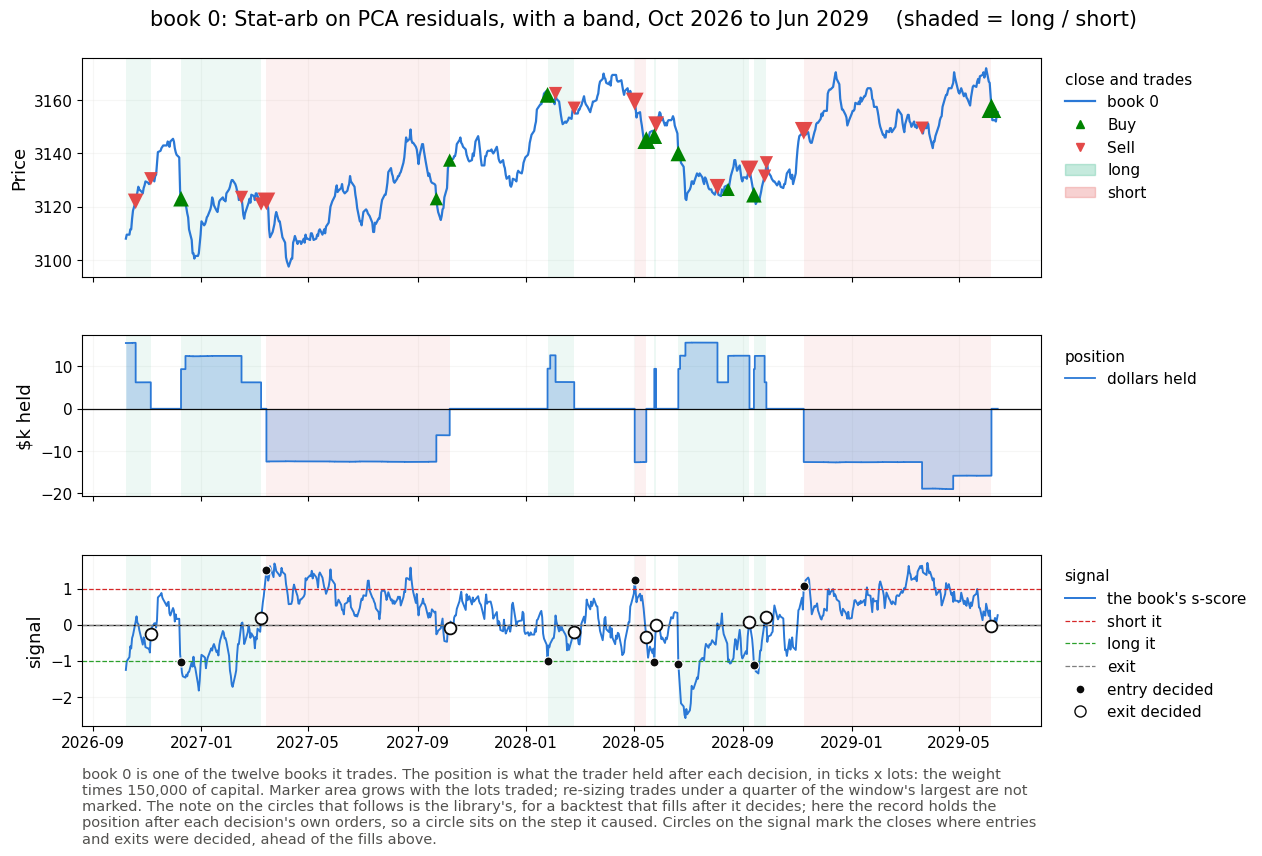

Each card against the fills, within what the run moves after its last decision: {'reversal': '+5,705 and +5,706', 'pairs': '+9,294 and +9,295', 'residuals': '+9,359 and +9,360'}
The most each card holds, as a multiple of the capital (above 1 the figure is leveraged): {'reversal': '0.72, above 1 on 0.0% of days', 'pairs': '0.72, above 1 on 0.0% of days', 'residuals': '1.10, above 1 on 0.1% of days'}
The capital of 150,000 is meant to be more than a card holds at its most (section 4); these hold more, as a multiple of it: {'residuals': '1.10'}.
The tables' figure for these runs, the last 20,000 units only: {'reversal': '+3,629', 'pairs': '+9,175', 'residuals': '+6,305'}


In [9]:
def most_changed(trader):
    held = np.array([step[2] for step in trader.history])
    return int(np.argmax((np.diff(held, axis=0) != 0).sum(axis=0)))  # the book whose lots change most often


def largest_leg(trader):
    return int(np.argmax(np.abs(trader.weights[0])))  # the book of the first pair's largest leg


def around(trader):
    # Lines at the level it enters at on either side of 0, and at the level it leaves at.
    enter, leave = trader.levels
    return [(enter, 'C3', 'short it'), (-enter, 'C2', 'long it'), (leave, 'C7', 'exit')]


LESS_CARDS = {
    'reversal': dict(
        trader='reversal, look back 50, rate 0.1, every 5',
        strategy='Cross-sectional reversal, going part of the way',
        detail='look back 50, every decision, a rate of 0.1, 5 lots of the largest',
        title='Reversal at a rate of 0.1, long and short in twelve books',
        signal_label="the book's score",
        levels=lambda trader: [(0.0, 'C7', 'a score of 0')],
        book=most_changed,
        relation=lambda book: book,
    ),
    'pairs': dict(
        trader='pairs by distance, 8, entry 1, rate 0.25',
        strategy='Eight pairs chosen by distance, going part of the way',
        detail='entry at 1, every decision, a rate of 0.25, 2.5 lots of each pair',
        title='Eight pairs at a rate of 0.25, in twelve books',
        signal_label='z-score of the first pair',
        levels=around,
        book=largest_leg,
        relation=lambda book: 0,
    ),
    'residuals': dict(
        trader='residuals, 3 factors, enter beyond 1, band 1',
        strategy='Stat-arb on PCA residuals, with a band',
        detail='three factors, open beyond 1, a band of 1 lot, 5 lots a book',
        title='Stat-arb on PCA residuals with a band of 1 lot, in twelve books',
        signal_label="the book's s-score",
        levels=around,
        book=lambda trader: 0,
        relation=lambda book: book,
    ),
}
less_runs = Parallel(n_jobs=-1)(delayed(recorded)(LESS_TRADERS[form['trader']], BURN) for form in LESS_CARDS.values())
less_done = dict(zip(LESS_CARDS, less_runs, strict=True))
less_agreement, less_peaks, most_held = {}, {}, {}
for name, form in LESS_CARDS.items():
    trader, fills = less_done[name]
    book = form['book'](trader)
    gross = record_of(trader)[2].abs().sum(axis=1)  # what it holds, as a multiple of the capital
    most_held[name] = gross.max()
    less_peaks[name] = f'{gross.max():.2f}, above 1 on {(gross > 1).mean():.1%} of days'
    less_agreement[name] = card(
        trader,
        fills,
        form['strategy'],
        form['detail'],
        form['title'],
        SETTING,
        form['signal_label'],
        form['levels'](trader),
        form['relation'](book),
        book,
        per_unit=5,
    )
print(
    'Each card against the fills, within what the run moves after its last decision:',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in less_agreement.items()},
)
print('The most each card holds, as a multiple of the capital (above 1 the figure is leveraged):', less_peaks)
over = {name: f'{most:.2f}' for name, most in most_held.items() if most > 1}
if over:
    print(
        f'The capital of {CAPITAL:,.0f} is meant to be more than a card holds at its most (section 4); these hold '
        f'more, as a multiple of it: {over}.'
    )
else:
    print(f'None of the three holds more than the capital of {CAPITAL:,.0f}, as section 4 sets it.')
less_counted = {
    name: less_frame[
        (less_frame.market == 'sectors') & (less_frame.trader == form['trader']) & (less_frame.seed == SEEDS[0])
    ].pnl.item()
    for name, form in LESS_CARDS.items()
}
print(
    f"The tables' figure for these runs, the last {SPAN:,.0f} units only:",
    {k: f'{v:+,.0f}' for k, v in less_counted.items()},
)

## 6. Sparse Mean-Reverting Baskets

**Notebook 12's baskets come from Johansen's test, and this section asks whether choosing them another way trades better.** `best_baskets` runs the trace test, at 95%, on every combination of a few books, an exhaustive search, and keeps the baskets whose statistic passes, the strongest first. Box and Tiao (1977) rank a portfolio instead by its *predictability*: fit a VAR(1) to the levels of the books, and the predictability of a portfolio is the share of its variance that the books' lagged levels explain, about 1 for a random walk and near 0 for noise. So the least predictable portfolio is the most mean-reverting one. Over all the books it has a leg in each. d'Aspremont (2011) asks for such portfolios with few legs, a hard problem that he attacks with a greedy search, and `lob/sparse_baskets.py` does that: it grows a basket from every pair of books, adding at each step the book that lowers the least predictability most, until the basket has the legs asked for, and ranks the distinct sets by their least predictability. As in `best_baskets`, the baskets that share no book with a better one come first.

**What it leaves out.** Any test of whether a basket is a relation: it returns the baskets asked for whether or not any is one, where Johansen's chooser returns only what its test accepts. A floor on a basket's swings: predictability is scale-free, so it does not see a basket's swing against what its legs cost to trade, and Cuturi and d'Aspremont (2013) add a variance threshold so that a basket is not chosen for swinging too little to pay for its legs. d'Aspremont's other searches, a semidefinite relaxation and an exact one: the greedy search is the cheapest, and as he notes can be far from the best. And lags beyond the first.

**The two markets offer different baskets to find.** In the sectors market the pairs within a sector are exact relations. In the mixed market no pair is a relation, the best triple nearly is, and every set of four books has at least one relation (in both markets the fair values share three factors, so any four books' loadings are dependent).

**The first part asks what each chooser picks.** Seven choosers, each on the history that a trader of the second part passes to its chooser at its first choice: the mids at its first 2,000 decisions, 5 units of time and the wait for the next event apart, with the trader alone in its market, on seeds 101 to 108. The table is of the traded baskets, because a trader sends no order before its first choice, so the history it chooses from does not depend on its chooser, its entry or its rate. A chooser that keeps a copy of what it is given records that history, and an assert in the cell checks, on seed 101 in both markets, that the rows of Box-Tiao's 4 of 3 on it are the weights that a trader of that chooser holds after its first choice; that is the one chooser and the one seed the notebook checks, and an independent check outside this notebook found a real trader's first weights equal to the chooser's rows on every seed, 101 to 108, in both markets, for Johansen's and Box-Tiao's baskets of 3 and of 4 books and for the dashboard's default. The choosers are pairs by distance, as in section 5, and Box-Tiao's, eight pairs each; Johansen's and Box-Tiao's four baskets of 3 books and four of 4 (*4 of 3* and *4 of 4*); and Box-Tiao's four baskets of all twelve books (*4 of all*), which are dense. For each row of weights it gives its legs, its *leftover exposure* to the true factors, ||w'B|| / ||w|| for weights w and the market's loadings B (0 for an exact relation), its predictability under one VAR(1) fitted to the history, the same for every chooser, and its *swing per lot*: the standard deviation of the basket's value over the history, in ticks, for one lot of its largest leg, over the lots held for it. For each chooser it gives the *books* that a seed's rows span between them (the distinct books), the most books that any two of its rows *share*, and the seconds it took.

**The second part trades them.** A `RelationTrader`, as in notebook 12 (2.5 lots of each pair and 5 of each basket's largest leg), on section 3's twelve seeds in both markets, with its burn and its span, so that these rows and section 5's compare to the tick. Section 5's pairs by distance, at an entry of 1 and a rate of 0.25, come first in each table as the reference row, not run again. Paired differences by seed are one trader less another on the same market and seed, and each is named for what it compares. The settings, an entry and a rate for each chooser, were chosen on seeds 1 to 8, as section 5's were: the combination of an entry and a rate with the most P&L after costs summed over the two markets, from entries of 0.75, 1, 1.5 and 2 and rates of 1, 0.25 and 0.1. Two rows were not chosen that way: the dashboard's default baskets row (Johansen, 4 of 3, an entry of 2 and no rate), and Box-Tiao's 4 of 4 at an entry of 1, set like for like with Johansen's. None of the seeds reported here chose any setting. A card of one trader follows.

What each chooser picks from the history that a trader of the trading cell below passes to its chooser at its first choice: its first 2,000 decisions, 5 units of time and the wait for the next event apart, with the trader alone in the market, seeds 101 to 108.
Checked: on seed 101, in both markets, the rows of Box-Tiao, 4 of 3 on this history are the weights that a trader of it, at an entry of 1 and a rate of 0.25, holds after its first choice.
rows_a_seed: baskets the chooser gave (mean over seeds). legs: books with a weight other than 0 (mean over rows). books: the distinct books across a seed's rows (mean over seeds). shared: the most books that any two of a seed's rows have in common (mean over seeds; 0 for a chooser that gave one row).
exposure: ||w'B|| / ||w|| for a row of weights w and the market's loadings B, the part of the basket that moves with the true factors (mean and largest over rows).
predictability: w'A gamma A'w / w'gamma w for a VAR(1) fitted to the history, one fit

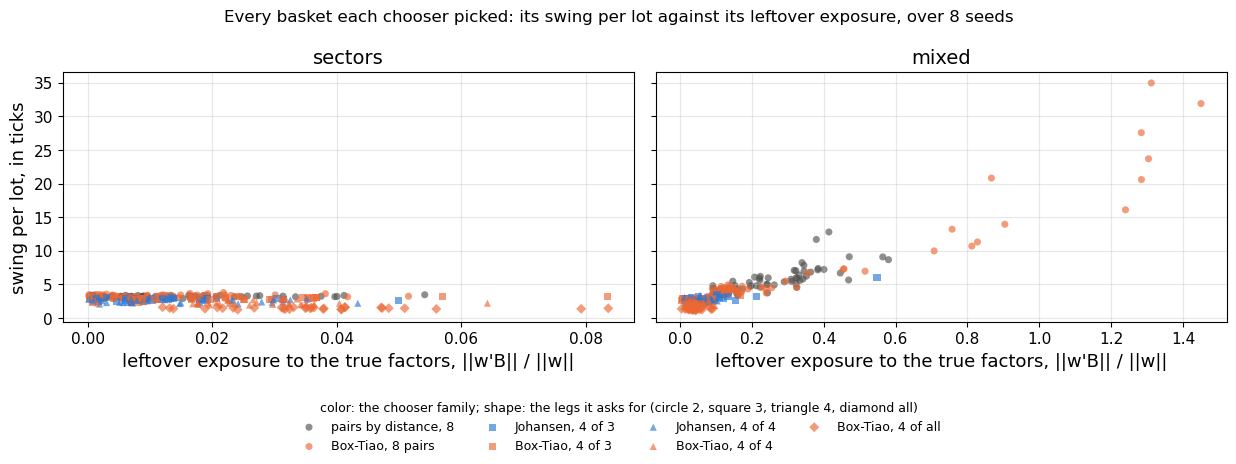

In [10]:
import itertools
import time

from lob.sparse_baskets import fit_var1, predictability, sparse_baskets
from lob.statarb import best_baskets

# What each chooser of relations picks, on the history a trader of the trading cell below passes to its chooser at its
# first choice. A chooser is as a RelationTrader of the trading cell below uses it (every=1: the history is already one
# mid a decision). Its entry is its family, the legs it asks for (0: all the books) and the function.
CHOOSERS = {
    'pairs by distance, 8': ('pairs by distance', 2, partial(pairs_by_distance, count=8)),
    'Box-Tiao, 8 pairs': ('Box-Tiao', 2, partial(sparse_baskets, count=8, legs=2, every=1)),
    'Johansen, 4 of 3': ('Johansen', 3, partial(best_baskets, count=4, legs=3, every=1)),
    'Box-Tiao, 4 of 3': ('Box-Tiao', 3, partial(sparse_baskets, count=4, legs=3, every=1)),
    'Johansen, 4 of 4': ('Johansen', 4, partial(best_baskets, count=4, legs=4, every=1)),
    'Box-Tiao, 4 of 4': ('Box-Tiao', 4, partial(sparse_baskets, count=4, legs=4, every=1)),
    'Box-Tiao, 4 of all': ('Box-Tiao', 0, partial(sparse_baskets, count=4, legs=0, every=1)),
}
FAMILY_COLORS = {'pairs by distance': GRAY, 'Johansen': BLUE, 'Box-Tiao': ORANGE}
LEG_MARKERS = {2: 'o', 3: 's', 4: '^', 0: 'D'}  # circle, square, triangle, diamond: 2, 3, 4 legs, all the books
# The chooser, entry and rate of the trading cell's BOX_TIAO_3: the trader whose first weights the assert below checks.
CHECKED = ('Box-Tiao, 4 of 3', 1.0, 0.25)


def relations_chosen_by(chooser, entry, rate):
    # Section 3's window, formation and interval, with this chooser, entry and rate; 2.5 lots of each pair and 5 of each
    # basket's largest leg, as the dashboard's pairs and baskets traders have.
    _, legs, choose = CHOOSERS[chooser]
    return lambda factors: RelationTrader(
        choose=choose, size=2.5 if legs == 2 else 5.0, rate=rate, **{**Z, 'entry': entry}
    )


def until_first_choice(market_name, seed, trader):
    # The trader alone in a fresh market of this seed, stepped until it has chosen once (its fits count one). The
    # traders of this notebook have no defer, so a choice is made on the spot, in the decision that asks for it.
    assert trader.defer is None, 'a trader that chooses elsewhere and takes up the choice later'
    market = BookMarket(FactorValues(MARKETS[market_name][0]), seed=seed, traders=(trader,))
    while not trader.fits:
        assert market.time <= trader.warm_up, 'no first choice by the time its warm-up is up'
        market.step()


def first_choice_history(market_name, seed):
    # The history a RelationTrader of the trading cell below passes to its chooser at its first choice, as a chooser
    # that keeps a copy of what it is given and chooses nothing is passed it: the mids at the trader's first FORMATION
    # decisions, EVERY units of time apart and then the wait for the next event (lob.statarb.WAIT is above its mean), so
    # that the last of them is a little after FORMATION * EVERY units of time.
    # Until that choice a RelationTrader holds nothing, sends no order, and draws no random number (the market's
    # streams are the market's own), so the path to it is the same whatever the trader's size, entry or rate and
    # whichever chooser it has. Only its interval matters, as it says when it decides, and this is section 3's.
    kept = []

    def record(history):
        kept.append(history.copy())
        return np.zeros((0, history.shape[1]))

    until_first_choice(market_name, seed, RelationTrader(choose=record, size=5.0, **{**Z, 'entry': 1.0}))
    assert len(kept) == 1 and kept[0].shape == (FORMATION, len(MARKETS[market_name][0]))
    return kept[0]


def first_weights(market_name, seed):
    # What a real trader of the trading cell below holds after its first choice: the weights of the trader CHECKED
    # names, alone in a fresh market of this seed, as soon as they are set.
    trader = relations_chosen_by(*CHECKED)(MARKETS[market_name][1])
    until_first_choice(market_name, seed, trader)
    return trader.weights.copy()


def picks_of(market_name, seed):
    # Every chooser on one history: how long it took, how many rows it gave and across how many books, and for each row
    # its legs, its leftover exposure to the true factors, its predictability and its swing per lot. The rows
    # themselves too, to be checked against a real trader's.
    loadings = MARKETS[market_name][0]
    history = first_choice_history(market_name, seed)
    a, gamma = fit_var1(history)  # one fit for every chooser, so that their rows' predictabilities compare
    calls, picked, rows_of = [], [], {}
    for chooser, (_, _, choose) in CHOOSERS.items():
        started = time.perf_counter()
        found = choose(history)
        seconds = time.perf_counter() - started
        rows_of[chooser] = found
        books = [set(np.flatnonzero(w)) for w in found]
        calls.append(
            {
                'market': market_name,
                'seed': seed,
                'chooser': chooser,
                'found': len(found),
                'books': len(set().union(*books)),  # distinct books across the rows
                'shared': max((len(x & y) for x, y in itertools.combinations(books, 2)), default=0),  # any two
                'seconds': seconds,
            }
        )
        for w in found:
            picked.append(
                {
                    'market': market_name,
                    'seed': seed,
                    'chooser': chooser,
                    'legs': int(np.count_nonzero(w)),
                    'exposure': float(np.linalg.norm(w @ loadings) / np.linalg.norm(w)),
                    'predictability': predictability(w, a, gamma),
                    'swing': float((history @ w).std() / np.abs(w).sum()),
                }
            )
    return calls, picked, rows_of


# The real traders' first weights go first, as they take as long as the longest of the rest.
chooser_cases = [(market_name, seed) for market_name in MARKETS for seed in FEW]
chooser_results = Parallel(n_jobs=-1)(
    [delayed(first_weights)(market_name, FEW[0]) for market_name in MARKETS]
    + [delayed(picks_of)(market_name, seed) for market_name, seed in chooser_cases]
)
first_held = dict(zip(MARKETS, chooser_results[: len(MARKETS)], strict=True))
chooser_runs = dict(zip(chooser_cases, chooser_results[len(MARKETS) :], strict=True))
for market_name, traded_rows in first_held.items():
    # The table is of the baskets that are traded: what the chooser gives on this history is what a trader holds after
    # its first choice.
    given_rows = chooser_runs[(market_name, FEW[0])][2][CHECKED[0]]
    assert given_rows.shape == traded_rows.shape and np.allclose(given_rows, traded_rows), (
        f"{CHECKED[0]}'s rows on the history differ from the weights a trader of it holds after its first choice, "
        f'in the {market_name} market on seed {FEW[0]}'
    )
chooser_calls = pd.DataFrame([call for calls, _, _ in chooser_runs.values() for call in calls])
chooser_rows = pd.DataFrame([row for _, picked, _ in chooser_runs.values() for row in picked])


def chooser_table(market_name):
    calls = chooser_calls[chooser_calls.market == market_name].groupby('chooser', sort=False)
    rows = chooser_rows[chooser_rows.market == market_name].groupby('chooser', sort=False)
    return pd.DataFrame(
        {
            'rows_a_seed': calls.found.mean(),
            'legs': rows.legs.mean(),
            'books': calls.books.mean(),
            'shared': calls.shared.mean(),
            'exposure': rows.exposure.mean(),
            'exposure_max': rows.exposure.max(),
            'predictability': rows.predictability.mean(),
            'swing_per_lot': rows.swing.mean(),
            'seconds': calls.seconds.median(),
        }
    ).reindex(list(CHOOSERS))


chooser_tables = {market_name: chooser_table(market_name) for market_name in MARKETS}
print(
    'What each chooser picks from the history that a trader of the trading cell below passes to its chooser at its '
    f'first choice: its first {FORMATION:,} decisions, {EVERY:g} units of time and the wait for the next event apart, '
    f'with the trader alone in the market, seeds {FEW[0]} to {FEW[-1]}.'
)
print(
    f'Checked: on seed {FEW[0]}, in both markets, the rows of {CHECKED[0]} on this history are the weights that a '
    f'trader of it, at an entry of {CHECKED[1]:g} and a rate of {CHECKED[2]:g}, holds after its first choice.'
)
print(
    "rows_a_seed: baskets the chooser gave (mean over seeds). legs: books with a weight other than 0 (mean over "
    "rows). books: the distinct books across a seed's rows (mean over seeds). shared: the most books that any two of "
    "a seed's rows have in common (mean over seeds; 0 for a chooser that gave one row)."
)
print(
    "exposure: ||w'B|| / ||w|| for a row of weights w and the market's loadings B, the part of the basket that moves "
    'with the true factors (mean and largest over rows).'
)
print(
    "predictability: w'A gamma A'w / w'gamma w for a VAR(1) fitted to the history, one fit for every chooser (mean "
    'over rows): about 1 for a random walk, 0 for noise.'
)
print(
    "swing_per_lot: the standard deviation of w'x over the history (ticks, for one lot of the largest leg), over the "
    'sum of |w|, the lots held for it (mean over rows). seconds: the median time to choose, on one core, with the '
    'other seeds running.'
)
print(
    'In the sectors market a pair within one sector, hedged one for one, has an exposure of 0 exactly, and an '
    'estimated hedge leaves a little; in the mixed market no pair is a relation, so every pair has some.'
)
for market_name in MARKETS:
    print(f'\n{market_name}')
    print(
        chooser_tables[market_name]
        .round(
            {
                'rows_a_seed': 1,
                'legs': 1,
                'books': 1,
                'shared': 1,
                'exposure': 3,
                'exposure_max': 3,
                'predictability': 3,
                'swing_per_lot': 2,
                'seconds': 2,
            }
        )
        .to_string()
    )

chooser_fig, chooser_axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for chooser_ax, market_name in zip(chooser_axes, MARKETS, strict=True):
    for chooser, spec in CHOOSERS.items():
        chooser_got = chooser_rows[(chooser_rows.market == market_name) & (chooser_rows.chooser == chooser)]
        chooser_ax.scatter(
            chooser_got.exposure,
            chooser_got.swing,
            s=26,
            alpha=0.65,
            color=FAMILY_COLORS[spec[0]],
            marker=LEG_MARKERS[spec[1]],
            edgecolors='none',
            label=chooser,
        )
    chooser_ax.set_title(market_name)
    chooser_ax.set_xlabel("leftover exposure to the true factors, ||w'B|| / ||w||")
chooser_axes[0].set_ylabel('swing per lot, in ticks')
chooser_handles, chooser_labels = chooser_axes[0].get_legend_handles_labels()
chooser_fig.suptitle(
    f'Every basket each chooser picked: its swing per lot against its leftover exposure, over {len(FEW)} seeds',
    fontsize=12,
)
chooser_fig.tight_layout(rect=(0, 0.16, 1, 1))
chooser_fig.legend(
    chooser_handles,
    chooser_labels,
    title='color: the chooser family; shape: the legs it asks for (circle 2, square 3, triangle 4, diamond all)',
    title_fontsize=9,
    fontsize=9,
    loc='lower center',
    ncol=4,
    frameon=False,
)
plt.show()

**Box-Tiao's baskets are the least predictable at 3 legs and more, but by little.** Every chooser's mean predictability is from 0.873 to 0.965, where a random walk's is about 1. In the sectors market Box-Tiao's baskets of 3 books have 0.885 against Johansen's 0.891, and its baskets of 4 0.875 against 0.889; in the mixed market 0.911 against 0.922 and 0.896 against 0.917. Its pairs have 0.957 against 0.965 for pairs by distance in the mixed market, and not less in the sectors market: 0.901 against 0.899. That Box-Tiao's baskets are lowest is what it asks for, on the history it chose from. More legs lower it: Box-Tiao's have 0.901, 0.885, 0.875 and 0.873 at 2, 3, 4 and 12 legs in the sectors market, and 0.957, 0.911, 0.896 and 0.887 in the mixed.

**In the sectors market every chooser leaves little of the true factors, and Johansen's baskets leave less than Box-Tiao's.** Every chooser's mean leftover exposure is 0.012 to 0.036, and no basket of any chooser leaves more than 0.084 (Box-Tiao's 4 of all). Johansen's 4 of 3 leave 0.012 and at most 0.050, Box-Tiao's 0.022 and at most 0.083. At 4 legs Johansen's leave 0.015 and at most 0.043, Box-Tiao's 0.026 and at most 0.064, and Box-Tiao's 4 of all 0.036 and at most 0.084. The pairs are alike, 0.013 and 0.012 for pairs by distance and Box-Tiao's.

**In the mixed market, where no pair is a relation, the pairs leave the most, and Box-Tiao's pairs more than pairs by distance on average.** Pairs by distance leave 0.252 on average and at most 0.580, and Box-Tiao's pairs 0.334 and at most 1.450, against 0.041 to 0.087 for every chooser of baskets. Box-Tiao's mean is lifted by a few pairs whose smaller leg is a small part of the larger, so that the pair is nearly a single book, which a chooser with no test of a relation can pick: its largest, 1.450, is two and a half times pairs by distance's 0.580, and an independent check outside this notebook found that its typical pair leaves less than pairs by distance's. The pairs at the upper right of the figure's mixed panel, with the largest leftover and the largest swing per lot, are Box-Tiao's. Box-Tiao's baskets leave less than Johansen's at the same legs: 0.055 and at most 0.168 against 0.087 and 0.548 at 3, and 0.043 and 0.096 against 0.056 and 0.103 at 4; its 4 of all leave 0.041 and at most 0.091. At 3 legs the gap is partly one basket: without Johansen's largest, 0.548, its other 31 rows average about 0.07 (worked out from the table's mean and the 0.548), still above Box-Tiao's 0.055.

**More legs make a basket swing less for each lot it holds, and Box-Tiao's swing less than Johansen's at 4 legs.** Box-Tiao's 4 of 3, 4 of 4 and 4 of all swing 2.85, 2.31 and 1.46 ticks a lot in the sectors market and 2.75, 2.26 and 1.41 in the mixed; Johansen's 4 of 3 and 4 of 4 swing 2.75 and 2.49 in the sectors market and 2.97 and 2.62 in the mixed. Box-Tiao's are lower at 4 legs in both markets and at 3 in the mixed market, and higher at 3 in the sectors market (2.85 against 2.75). So the least predictable chooser, the 4 of all (0.873 and 0.887), is the one whose baskets swing least per lot: predictability does not see a swing against what its lots cost. In the figure's mixed panel the swing per lot rises with the leftover exposure, from the baskets at the lower left to the pairs, whose 5.61 and 7.14 are the largest.

**Box-Tiao's baskets span fewer books than Johansen's, and at 4 legs in the sectors market share more of them.** Box-Tiao's four baskets of 3 span 8.9 books in the sectors market and 9.6 in the mixed, Johansen's 10.0 and 10.1; its four baskets of 4 span 9.4 and 10.2, and Johansen's span all 12 on every seed in both markets. The most books that two of a seed's baskets share is the same at 3 legs, 2.0 and 1.4 for both choosers, and at 4 legs 3.0 and 2.6 for Box-Tiao's against 2.4 and 2.5 for Johansen's (3.0 is as many as two different baskets of 4 can share, so in the sectors market two of Box-Tiao's differ by one book on every seed; in the mixed market 2.6 against 2.5 is one book on one seed of eight). The pairs go the other way: Box-Tiao's eight pairs span all 12 books on every seed, and pairs by distance 9.2 and 9.0.

**Box-Tiao chooses more than ten times as fast.** Johansen's 4 of 3 take 0.23 seconds in the sectors market and 0.20 in the mixed, and its 4 of 4 0.50 and 0.45; Box-Tiao's take 0.01 and 0.01, and 0.02 and 0.02. Pairs by distance, Box-Tiao's pairs and its 4 of all take 0.00. The times are medians of one call on one core, measured on the laptop with the other seeds' choices running, so compare them with each other and not as absolute times.

**Every chooser gave the rows asked for, on every seed.** The mean for each chooser in both tables is 8.0 pairs or 4.0 baskets a seed, so Johansen's test accepted four baskets of 3 books and four of 4 on each seed, in the mixed market too, where no pair is a relation and the best triple only nearly is. Box-Tiao's chooser has no test to fail.

P&L over 20,000 units of time after a burn of 10,465, on seeds 101 to 112: the same as section 5's, whose pairs by distance come first. With a rate below 1, entries are the states asked for, and not trades.

sectors
                                                      pnl     se  positive  before_costs    costs     lots  cost_a_lot  entries  gross  exposure  risk_adjusted
trader                                                                                                                                                         
pairs by distance, 8, entry 1, rate 0.25           8639.0  105.0  12 of 12       15440.0   6800.0   6770.0        1.00    860.0   18.8       1.5          0.068
baskets, Johansen, 4 of 3, entry 2 (notebook 12)   5105.0  125.0  12 of 12        9118.0   4014.0   2836.0        1.42    142.0   10.1       0.2          0.042
baskets, Johansen, 4 of 3, entry 1, rate 0.25      7149.0  175.0  12 of 12       15056.0   7908.0   7737.0        1.02    432.0   23.9       0.9

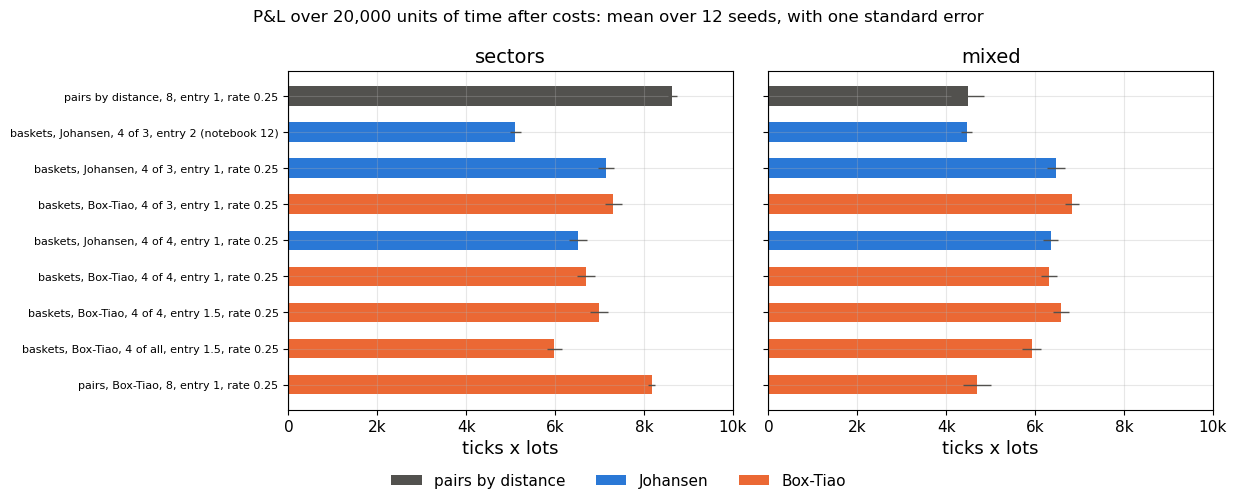

In [11]:
# Settings chosen on seeds 1 to 8, as section 5's were, for most rows: the entry and the rate with the most P&L after
# costs summed over the two markets, from entries of 0.75, 1, 1.5 and 2 and rates of 1, 0.25 and 0.1. The two exceptions
# are the dashboard's default, and Box-Tiao 4 of 4 at entry 1, set like for like with Johansen 4 of 4. Both markets and
# the twelve seeds, the burn and the span of section 3, so that these rows and section 5's compare to the tick. The
# first row of each table is section 5's pairs by distance, not run again.
PAIRS_BY_DISTANCE = 'pairs by distance, 8, entry 1, rate 0.25'  # section 5's row
DASHBOARD_BASKETS = 'baskets, Johansen, 4 of 3, entry 2 (notebook 12)'  # the dashboard's default baskets trader
JOHANSEN_3 = 'baskets, Johansen, 4 of 3, entry 1, rate 0.25'
BOX_TIAO_3 = 'baskets, Box-Tiao, 4 of 3, entry 1, rate 0.25'
JOHANSEN_4 = 'baskets, Johansen, 4 of 4, entry 1, rate 0.25'
BOX_TIAO_4 = 'baskets, Box-Tiao, 4 of 4, entry 1, rate 0.25'  # like for like with the Johansen row above
BOX_TIAO_4_BEST = 'baskets, Box-Tiao, 4 of 4, entry 1.5, rate 0.25'  # its own best
BOX_TIAO_ALL = 'baskets, Box-Tiao, 4 of all, entry 1.5, rate 0.25'
BOX_TIAO_PAIRS = 'pairs, Box-Tiao, 8, entry 1, rate 0.25'
BASKET_SETTINGS = {  # name: its chooser, its entry and its rate
    DASHBOARD_BASKETS: ('Johansen, 4 of 3', 2.0, 1.0),
    JOHANSEN_3: ('Johansen, 4 of 3', 1.0, 0.25),
    BOX_TIAO_3: ('Box-Tiao, 4 of 3', 1.0, 0.25),
    JOHANSEN_4: ('Johansen, 4 of 4', 1.0, 0.25),
    BOX_TIAO_4: ('Box-Tiao, 4 of 4', 1.0, 0.25),
    BOX_TIAO_4_BEST: ('Box-Tiao, 4 of 4', 1.5, 0.25),
    BOX_TIAO_ALL: ('Box-Tiao, 4 of all', 1.5, 0.25),
    BOX_TIAO_PAIRS: ('Box-Tiao, 8 pairs', 1.0, 0.25),
}


# relations_chosen_by, in the cell above, makes each of these from its chooser, entry and rate.
BASKET_TRADERS = {name: relations_chosen_by(*setting) for name, setting in BASKET_SETTINGS.items()}
# The trader whose first weights the cell above compared with its table's rows is this one.
assert BASKET_SETTINGS[BOX_TIAO_3] == CHECKED, "the cell above checked another trader's first weights"
assert PAIRS_BY_DISTANCE in LESS_TRADERS and PAIRS_BY_DISTANCE in less_table.index.get_level_values('trader')
# The burn must not cut into any trader's warm-up: section 3's burn is its longest warm-up and 400 more.
assert all(make(3).warm_up <= BURN - 400.0 for make in BASKET_TRADERS.values()), 'the burn cuts into a warm-up'
assert all(make(3).netted for make in BASKET_TRADERS.values()), 'a trader that does not net its orders'

basket_frame, basket_table = compare(BASKET_TRADERS, BURN)


def basket_rows(market_name):
    # Section 5's pairs by distance, then these.
    return pd.concat([less_table.loc[market_name].loc[[PAIRS_BY_DISTANCE]], basket_table.loc[market_name]])


print(
    f'P&L over {SPAN:,.0f} units of time after a burn of {BURN:,.0f}, on seeds {SEEDS[0]} to {SEEDS[-1]}: the same as '
    "section 5's, whose pairs by distance come first. With a rate below 1, entries are the states asked for, and not "
    'trades.'
)
for market_name in MARKETS:
    print(f'\n{market_name}')
    print(shown(basket_rows(market_name)))

# Paired differences: the same market and seed, one trader less another.
by_basket = pd.concat([less_frame, basket_frame]).set_index(['market', 'trader', 'seed']).sort_index()
assert by_basket.index.is_unique
BASKET_COMPARISONS = {
    'Box-Tiao less Johansen, 4 of 3 (entry 1, rate 0.25)': (BOX_TIAO_3, JOHANSEN_3),
    'Box-Tiao less Johansen, 4 of 4 (entry 1, rate 0.25)': (BOX_TIAO_4, JOHANSEN_4),
    'Box-Tiao 4 of 4 at its own best less Johansen 4 of 4': (BOX_TIAO_4_BEST, JOHANSEN_4),
    "Johansen 4 of 3 at its best less the dashboard's default": (JOHANSEN_3, DASHBOARD_BASKETS),
    "Box-Tiao 4 of 3 less pairs by distance (section 5's row)": (BOX_TIAO_3, PAIRS_BY_DISTANCE),
    "Box-Tiao pairs less pairs by distance (section 5's row)": (BOX_TIAO_PAIRS, PAIRS_BY_DISTANCE),
}


def basket_difference(market_name, one, other, column):
    return by_basket.loc[(market_name, one), column] - by_basket.loc[(market_name, other), column]  # by seed


basket_differences = []
for market_name in MARKETS:
    for basket_comparison, (one, other) in BASKET_COMPARISONS.items():
        pnl_gap = basket_difference(market_name, one, other, 'pnl')
        risk_gap = basket_difference(market_name, one, other, 'risk_adjusted')
        basket_differences.append(
            {
                'market': market_name,
                'comparison': basket_comparison,
                'pnl': pnl_gap.mean(),
                'se': pnl_gap.sem(),
                'positive': f'{(pnl_gap > 0).sum()} of {len(pnl_gap)}',
                'risk_adjusted': risk_gap.mean(),
                'risk_se': risk_gap.sem(),
                'risk_positive': f'{(risk_gap > 0).sum()} of {len(risk_gap)}',
            }
        )
basket_paired = pd.DataFrame(basket_differences)
print(
    f'\nPaired differences, one trader less another on the same market and seed: mean, its se across the {len(SEEDS)} '
    'seeds, and the seeds above 0'
)
print(
    basket_paired.set_index(['market', 'comparison'])
    .round({'pnl': 0, 'se': 0, 'risk_adjusted': 3, 'risk_se': 3})
    .to_string()
)

BASKET_ORDER = [PAIRS_BY_DISTANCE, *BASKET_SETTINGS]
BASKET_FAMILY = {PAIRS_BY_DISTANCE: 'pairs by distance'} | {
    name: CHOOSERS[chooser][0] for name, (chooser, _, _) in BASKET_SETTINGS.items()
}
basket_places = [-float(i) for i in range(len(BASKET_ORDER))]
# A linear axis, from 0 or from below it if a mean less its se is: this section's rows are within a few thousand of one
# another, which section 5's symlog axis squeezes. Ticks every 1k or 2k (more only if the range ever needs it).
basket_means = pd.concat([basket_rows(market_name) for market_name in MARKETS])
basket_low = min(0.0, (basket_means.pnl - basket_means.se).min())
basket_high = max(0.0, (basket_means.pnl + basket_means.se).max())
basket_step = next(
    (step for step in (1_000, 2_000, 5_000, 10_000, 20_000, 50_000) if (basket_high - basket_low) / step <= 6), 100_000
)
basket_ticks = np.arange(np.floor(basket_low / basket_step), np.ceil(basket_high / basket_step) + 1) * basket_step
basket_fig, basket_axes = plt.subplots(1, 2, figsize=(12.5, 5.0), sharex=True, sharey=True)
for basket_ax, market_name in zip(basket_axes, MARKETS, strict=True):
    basket_shown = basket_rows(market_name)
    for basket_role, basket_color in FAMILY_COLORS.items():
        picked = [i for i, name in enumerate(BASKET_ORDER) if BASKET_FAMILY[name] == basket_role]
        basket_got = basket_shown.loc[[BASKET_ORDER[i] for i in picked]]
        basket_ax.barh(
            [basket_places[i] for i in picked],
            basket_got.pnl,
            xerr=basket_got.se,
            height=0.55,
            color=basket_color,
            error_kw=dict(ecolor=GRAY, lw=1),
            label=basket_role,
        )
    basket_ax.axvline(0, color=GRAY, lw=0.8)
    basket_ax.set_yticks(basket_places, BASKET_ORDER, fontsize=8)
    basket_ax.set_title(market_name)
    basket_ax.set_xlabel('ticks x lots')
    basket_ax.set_xlim(basket_ticks[0], basket_ticks[-1])
    basket_ax.xaxis.set_major_locator(FixedLocator(basket_ticks))
    basket_ax.minorticks_off()
    basket_ax.xaxis.set_major_formatter(FuncFormatter(kilo))
basket_handles, basket_labels = basket_axes[0].get_legend_handles_labels()
basket_fig.suptitle(
    f'P&L over {SPAN:,.0f} units of time after costs: mean over {len(SEEDS)} seeds, with one standard error',
    fontsize=12,
)
basket_fig.tight_layout(rect=(0, 0.05, 1, 1))
basket_fig.legend(basket_handles, basket_labels, loc='lower center', ncol=3, frameon=False)
plt.show()

**Every row makes money on every seed in both markets, and Box-Tiao's chooser against Johansen's matters least to how much.** All nine rows of each table are positive on 12 of 12 seeds. In the sectors market they run from +5,105 (se 125, the dashboard's default) to +8,639 (se 105, pairs by distance), and in the mixed from +4,460 (se 123, the dashboard's default) to +6,839 (se 157, Box-Tiao's 4 of 3). The figure's axis is linear, from 0, so its bars compare in length, and a difference of a few hundred is a small step between them: read those from the tables.

**At the same settings, Box-Tiao's baskets make about what Johansen's do.** Box-Tiao less Johansen, 4 of 3, at an entry of 1 and a rate of 0.25: +156 (se 180, 7 of 12 seeds positive) in the sectors market and +367 (se 226, 9 of 12) in the mixed; for the 4 of 4 at the same settings, +172 (se 230, 6 of 12) and -44 (se 237, 6 of 12). None is as much as two of its standard errors from 0, and each is positive on 6 to 9 of 12 seeds. This holds for the seeds drawn here, and not for every seed that could be drawn. Johansen's chooser can hand a trader a basket with no relation in it: it takes first the baskets that share no book with a better one, so with four baskets of 3 from twelve books its fourth can be a triple apart from the first three, taken whenever its trace statistic passes the 95% value. The picks above are the baskets these traders hold, on eight of the twelve seeds (the assert in the picks' cell checks Box-Tiao's 4 of 3 on seed 101; the history before a first choice does not depend on the chooser, and an independent check outside this notebook found the other choosers' first weights equal to their picks on all eight seeds). In the sectors market no basket of Johansen's 4 of 3 leaves more than 0.050 (0.012 on average), against Box-Tiao's 0.083 (0.022); in the mixed market Johansen's leave 0.087 on average and at most 0.548, against Box-Tiao's 0.055 and 0.168. The notebook does not show what the other four seeds picked, or how much of a paired difference, none of these as much as two standard errors from 0, comes from any one basket. Per unit of risk the 4 of 3 differ by -0.002 (se 0.002, 5 of 12) and +0.000 (se 0.002, 6 of 12), which is no difference either. The rows' own P&L: +7,304 (se 192) for Box-Tiao against +7,149 (se 175) for Johansen in the sectors market, and +6,839 (se 157) against +6,472 (se 210) in the mixed.

**Per unit of risk, Box-Tiao's 4 of 4 are behind Johansen's.** The difference is -0.006 (se 0.002, 2 of 12 seeds positive) in the sectors market and -0.007 (se 0.002, 1 of 12) in the mixed, for the same P&L: Box-Tiao's trade more lots, 11,133 and 9,135 against 9,166 and 8,156, and hold more, 32.8 and 28.1 lots against 28.0 and 26.8. Part of that is the weights. An independent check outside this notebook found that for one lot of the largest leg Box-Tiao's baskets of 4 hold more lots in their other legs than Johansen's (in the mixed market many of Johansen's have a leg too small to hold at this size), and that the extra lots add risk and costs without adding P&L; the picks show their swing per lot lower, 2.31 and 2.26 against 2.49 and 2.62. The picks also show Box-Tiao's baskets of 4 spanning fewer books than Johansen's, 9.4 and 10.2 against 12.0 and 12.0, and in the sectors market sharing more of them, at most 3.0 between two against 2.4 (in the mixed market 2.6 against 2.5 is one book on one seed of eight), so some of its four are near-copies of one relation, as the same check found on seed 101 in the sectors market, which a count of books does not measure. The check found that on four seeds the extra lots held account for all of the extra risk of Box-Tiao's trader in the mixed market and for most of it in the sectors market, where the overlap adds a little, within the noise of four seeds; so the lots, not the books, are the larger part of the gap. The baskets of 3 span fewer books too (8.9 and 9.6 against 10.0 and 10.1) but share the same, 2.0 and 1.4, and per unit of risk they do not differ.

**Each chooser's own best is not like for like, and Box-Tiao's is ahead by about two standard errors in the sectors market only.** Box-Tiao's 4 of 4 does best at an entry of 1.5, where Johansen's does best at 1. Box-Tiao 4 of 4 at its own best, less Johansen 4 of 4, is +459 (se 205, 9 of 12 seeds positive) in the sectors market, a little over two standard errors and the only one of the six P&L differences between Box-Tiao's chooser and Johansen's (three in each market) that is over two, and +227 (se 264, 5 of 12) in the mixed; per unit of risk it is +0.001 (se 0.002, 7 of 12) and +0.001 (se 0.002, 5 of 12). An independent check outside this notebook, whose figures are not printed here, found that on seeds 1 to 8, the seeds that chose the entry, the same P&L comparison went the other way in the sectors market, by under two standard errors, so the sectors figure is not an edge the choosing seeds showed. The entry is changed along with the chooser. Entering at 1.5 instead of 1 gives Box-Tiao's 4 of 4 about the same P&L on about two thirds of the lots: +6,984 (se 197) on 7,207 lots against +6,697 (se 210) on 11,133 in the sectors market, and +6,580 (se 186) on 6,086 against +6,310 (se 183) on 9,135 in the mixed. These are differences of means on the same twelve seeds, not paired by seed.

**The settings matter more than the choice between Box-Tiao's chooser and Johansen's.** Johansen's 4 of 3 at an entry of 1 and a rate of 0.25, less the dashboard's default (an entry of 2 and no rate), is +2,044 (se 132, 12 of 12 seeds positive) in the sectors market and +2,012 (se 176, 12 of 12) in the mixed, against +156 and +367 for Box-Tiao's chooser less Johansen's at the same settings. This changes the entry and the rate together. At an entry of 1 and a rate of 0.25 it makes +7,149 (se 175) on 7,737 lots in the sectors market and +6,472 (se 210) on 6,818 in the mixed, against +5,105 (se 125) on 2,836 and +4,460 (se 123) on 2,468 for the default: more than two and a half times the lots, and more than twice the lots held, 23.9 and 25.6 against 10.1 and 12.3. A lot costs 1.02 and 0.96 against 1.42 and 1.23, as section 5 found for a rate. Per unit of risk the difference is -0.000 (se 0.001, 4 of 12) and +0.002 (se 0.001, 7 of 12): it makes more mostly because it holds more, and per unit of risk it is no better in the sectors market and a little better, by about two standard errors, in the mixed. Changing from pairs to baskets can move P&L as much: Box-Tiao's 4 of 3 less pairs by distance, below, is +2,355 in the mixed market, as large as the settings' +2,012 there, and -1,335 in the sectors market.

**Against pairs by distance, section 5's row at the same entry and rate, Box-Tiao's 4 of 3 make less in the sectors market and more in the mixed.** Box-Tiao 4 of 3 less pairs by distance is -1,335 (se 171, 0 of 12 seeds positive) in the sectors market and +2,355 (se 376, 12 of 12) in the mixed; per unit of risk -0.029 (se 0.002, 0 of 12) and +0.006 (se 0.003, 9 of 12). In the sectors market no basket row reaches the pairs' +8,639 (se 105): the most is +7,304 (se 192), and the pairs' 0.068 per unit of risk is above every basket row's 0.029 to 0.042. In the mixed market every basket row but the dashboard's default is above the pairs' +4,484 (se 367), at +5,925 to +6,839, on more lots (6,086 to 9,779 against 3,673) and with less exposure to the factors (1.1 to 2.1 lots against 3.7), as no pair there is a relation; per unit of risk the baskets run from 0.035 to 0.046 against the pairs' 0.040. Apart from the paired difference, these compare means on the same twelve seeds.

**Box-Tiao's pairs make less than pairs by distance in the sectors market and about the same in the mixed, and a little more per unit of risk in both.** Box-Tiao pairs less pairs by distance, both at an entry of 1 and a rate of 0.25, is -469 (se 134, 1 of 12 seeds positive) in the sectors market and +207 (se 254, 7 of 12) in the mixed; per unit of risk +0.003 (se 0.001, 8 of 12) and +0.009 (se 0.003, 9 of 12). They trade 6,614 and 4,015 lots against 6,770 and 3,673, and hold 3.8 lots of exposure to the factors in the mixed market against 3.7. In the picks Box-Tiao's eight pairs span all 12 books on every seed and pairs by distance 9.2 and 9.0, and they hold about the same lots (19.0 and 18.7 against 18.8 and 19.0), so here the chooser that spans more books is a little ahead per unit of risk on the same lots; the notebook does not test whether that is why.

**Box-Tiao's baskets of all twelve books make the least of the baskets' rows but the dashboard's default.** At an entry of 1.5 and a rate of 0.25 they make +5,984 (se 165) and +5,925 (se 209), on 10,562 and 9,779 lots and 29.9 and 28.2 lots held, against +6,984 and +6,580 for the 4 of 4 at the same entry. In the sectors market they hold the most exposure of any row, 1.6 lots.

**Box-Tiao's baskets hold less of the true factors than Johansen's at the same settings in three of the four rows and about the same in the mixed 4 of 4, and the table of picks says so for the mixed market; in the sectors market what is held is rounding to whole lots, not the baskets' leftover.** Box-Tiao's 4 of 3 hold 0.7 and 1.2 lots of exposure against Johansen's 0.9 and 2.1, and its 4 of 4 0.9 and 1.2 against 1.3 and 1.3: less in three of the four rows, and about the same in the mixed 4 of 4 (1.2 against 1.3), all unpaired means with no standard error. The table of picks says the same in the mixed market, at 3 legs (a leftover of 0.055 against 0.087) and at 4 (0.043 against 0.056), and there the leftover is the larger part of what is held. In the sectors market the picks go the other way (0.022 against 0.012 at 3 legs, 0.026 against 0.015 at 4), but every chooser's leftover there is small, 0.012 to 0.036 on average and at most 0.084, and what a trader holds of the factors is whole lots that do not net to 0 within a sector: a vector of one sector rounded to lots is an exact relation when its legs round to a net of 0 and a lot of exposure when they do not, and with a rate of 0.25 the position is the rounded aim on its way to a rounded target. An independent check outside this notebook found that on seeds 101 and 102 the aim of either 4 of 3 trader held no exposure to the factors while its position held some, more for Johansen's than for Box-Tiao's, and that Box-Tiao's is the lower because many of its baskets of 3 are pairs as held (their third legs, small weights from another sector, round to no lot) and many of its baskets of 4 are two near-equal pairs, which round cleanly where Johansen's within-sector vectors do not. In the mixed market Johansen's 4 of 3 hold the most exposure of any basket row, 2.1 lots, and its baskets leave the most of any chooser of baskets, 0.087 on average; the notebook does not show how much of either comes from one basket.

**A lot costs about a tick in every row with a rate, and more in the default's.** The rows with a rate of 0.25 pay 1.00 to 1.04 a lot in the sectors market and 0.95 to 0.99 in the mixed; the default's lots pay 1.42 and 1.23.

### In a Backtest's Terms

The scorecard and signal chart of Box-Tiao's four baskets of 3 books, entering at 1 with a rate of 0.25 (5 lots of the largest leg of each, deciding every 5 units), in the mixed market on seed 101 (the cards of sections 4 and 5 are in the sectors market), in the same form. It is the row with the most P&L in the mixed market, +6,839 (se 157), where it beats pairs by distance. The chart is of book 1, the first basket's largest leg, with that basket's z-score, lines at 1 and -1 where it enters, and a line where it exits. The card runs from the trader's first order to the end of the run, and the tables count only the last 20,000 units, so a card's figure differs from its table's.

**The record is 4 from the fills, further than section 5's cards were.** It makes +7,818, and its fills made +7,822. Section 5's cards were within 1 of their fills, and section 4's from 2 to 8 of theirs.

**The card does not hold more than its capital.** It holds at most 0.95 times the capital of 150,000, above 1 on 0.0% of days, so its figure is not leveraged, as section 4 sets it. Section 5's reversal and pairs cards held 0.72 at their most, and its residuals card 1.10.

**Seed 101 made more than the mean of the twelve seeds.** The table's figure for this run, the last 20,000 units only, is +7,684, against +6,839 (se 157) for the mean of the twelve seeds; the card's +7,818 is 134 more than the table's, as it counts from the trader's first order.

**In the chart, the position is built a step at a time and held in runs.** Book 1 goes short and long in runs, reached in small steps and then kept at one size for a long stretch while the first basket's z-score moves about, short when the z-score is high and long when it is low. In this window the z-score goes further below its line at -1 than above its line at 1.

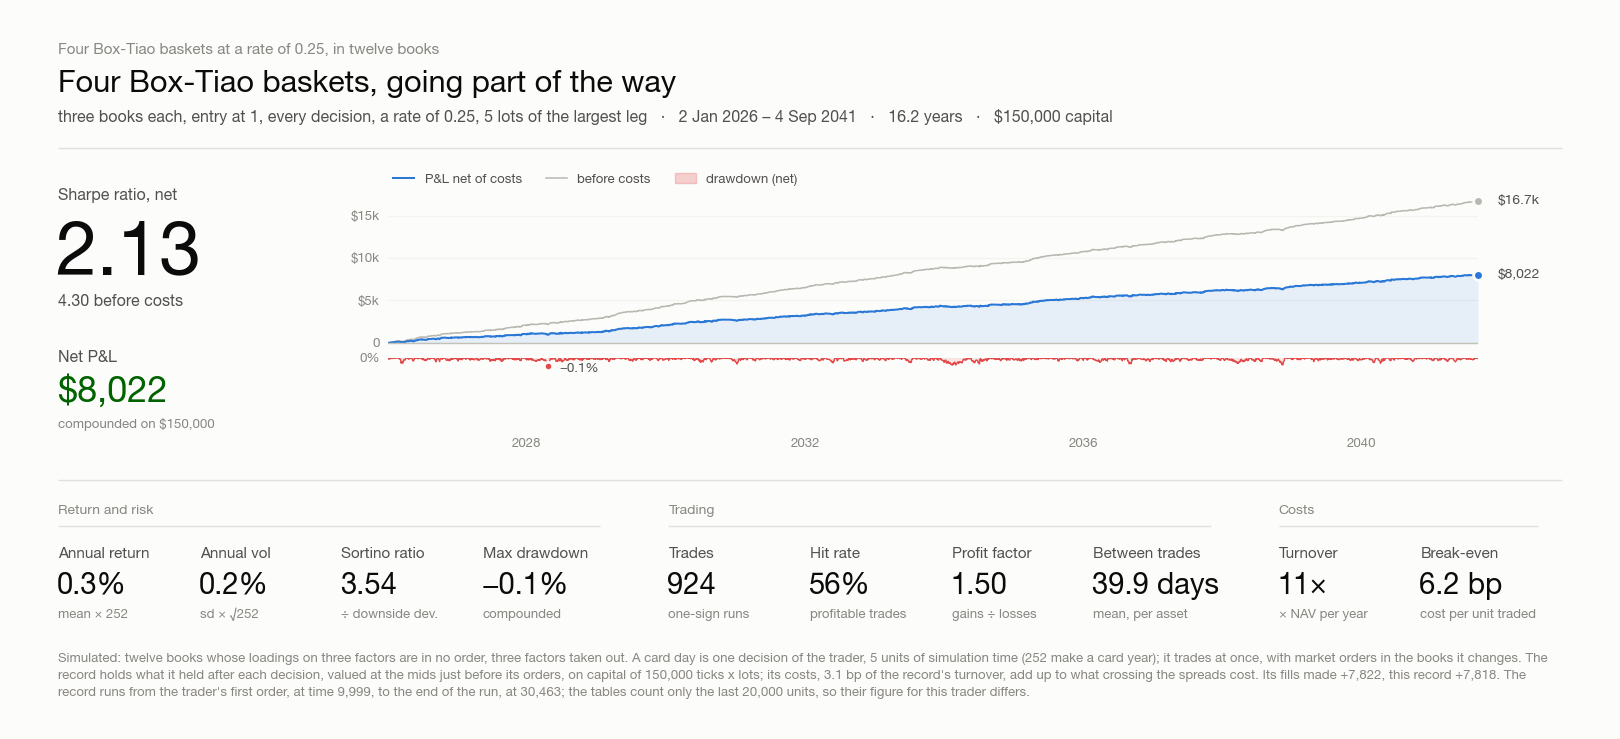

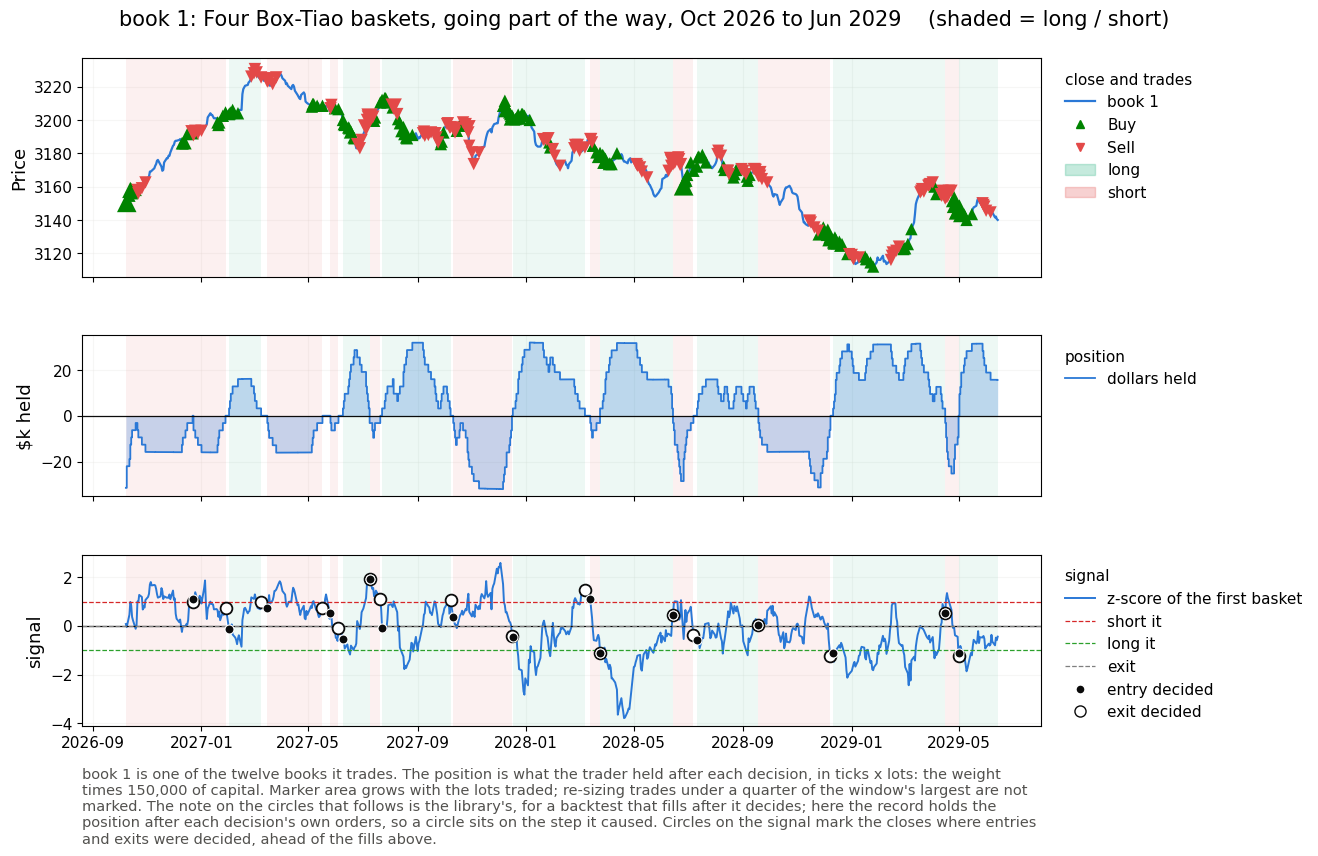

The card against the fills, within what the run moves after its last decision: +7,822 and +7,818
The most the card holds, as a multiple of the capital (above 1 the figure is leveraged): 0.95, above 1 on 0.0% of days
The card does not hold more than the capital of 150,000, as section 4 sets it.
The tables' figure for this run, the last 20,000 units only: +7,684


In [12]:
BASKET_CARD = dict(
    trader=BOX_TIAO_3,
    strategy='Four Box-Tiao baskets, going part of the way',
    detail='three books each, entry at 1, every decision, a rate of 0.25, 5 lots of the largest leg',
    title='Four Box-Tiao baskets at a rate of 0.25, in twelve books',
)
MIXED_SETTING = 'twelve books whose loadings on three factors are in no order, three factors taken out'
basket_trader, basket_fills = recorded(BASKET_TRADERS[BASKET_CARD['trader']], BURN, market='mixed')
basket_book = largest_leg(basket_trader)  # the first basket's largest leg
basket_gross = record_of(basket_trader)[2].abs().sum(axis=1)  # what it holds, as a multiple of the capital
basket_agreement = card(
    basket_trader,
    basket_fills,
    BASKET_CARD['strategy'],
    BASKET_CARD['detail'],
    BASKET_CARD['title'],
    MIXED_SETTING,
    'z-score of the first basket',
    around(basket_trader),
    0,
    basket_book,
    per_unit=5,
)
print(
    'The card against the fills, within what the run moves after its last decision:',
    f'{basket_agreement[0]:+,.0f} and {basket_agreement[1]:+,.0f}',
)
print(
    'The most the card holds, as a multiple of the capital (above 1 the figure is leveraged):',
    f'{basket_gross.max():.2f}, above 1 on {(basket_gross > 1).mean():.1%} of days',
)
if basket_gross.max() > 1:
    print(
        f'The capital of {CAPITAL:,.0f} is meant to be more than a card holds at its most (section 4); this holds '
        f'more, as a multiple of it: {basket_gross.max():.2f}.'
    )
else:
    print(f'The card does not hold more than the capital of {CAPITAL:,.0f}, as section 4 sets it.')
basket_counted = basket_frame[
    (basket_frame.market == 'mixed') & (basket_frame.trader == BASKET_CARD['trader']) & (basket_frame.seed == SEEDS[0])
].pnl.item()
print(f"The tables' figure for this run, the last {SPAN:,.0f} units only: {basket_counted:+,.0f}")

## 7. Conclusions

In [13]:
def said(r):
    return f'{r.pnl:+,.0f} (se {r.se:.0f}, {r.positive} seeds positive)'


def figures(mean, se, market, keys, column, digits=3):
    return ', '.join(
        f'{mean.loc[(market, key), column]:+.{digits}f} (se {se.loc[(market, key), column]:.{digits}f})' for key in keys
    )


def kind_of(name):
    return name.split(',')[0]


SHOWN = (1, 25, 100)
for market in MARKETS:
    print(
        f"- {market}, residual moves, a book's sum with its own next at {', '.join(map(str, SHOWN))} units: "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'own')}; with another book's next: "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'cross')}, of which the PCA forces "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'forced')}, leaving "
        f"{figures(memory_mean, memory_se, market, SHOWN, 'beyond')}."
    )
for market in MARKETS:
    for lag in (LAGS[0], LAGS[-1]):
        part = 1000 * decomposition.loc[(market, lag)]
        print(
            f'- {market}, the contrarian portfolio at lag {lag}: {part.profit:+.2f} (se {part.se:.2f}) thousandths of '
            f'a tick a decision, of which own {part.own:+.2f}, cross {part.cross:+.2f}, means {part.means:+.2f}.'
        )
for market in MARKETS:
    rows = knows.loc[market]
    top = rows.sort_values('ic', ascending=False).head(3)
    best = '; '.join(f'{name} {r.ic:.3f} (edge {r.edge:+.4f})' for name, r in top.iterrows())
    kinds = crossing[crossing.market == market].set_index('kind')
    cost = '; '.join(f'{kind} {r.cost_a_lot:.2f}' for kind, r in kinds.iterrows())
    print(f'- {market}, what the signals know, by IC: {best}. A lot traded costs, in ticks: {cost}.')
    top = rows.per_lot.idxmax()
    print(
        f'  The most any listener earns a lot traded is {rows.per_lot.max():+.3f}, at {top} (turnover '
        f'{rows.turnover[top]:.2f} a decision, edge {rows.edge[top]:+.4f} a gross lot held), against the least cost of '
        f'{kinds.cost_a_lot.min():.2f} a lot traded.'
    )
for market in MARKETS:
    rows = table.loc[market]
    new = rows[~rows.index.isin(BASELINES)]
    by_kind = new.groupby(new.index.map(kind_of), sort=False)
    best, tried = by_kind.pnl.idxmax(), by_kind.size()
    print(
        f'- {market}, {(new.pnl > 0).sum()} of {len(new)} settings make money after costs, '
        f'{(new.pnl - 2 * new.se > 0).sum()} of them by two standard errors (counts over the list fixed in advance, '
        'not a test). The best of the few tried of each kind, on these seeds: '
        + '; '.join(f'{name} {said(new.loc[name])} (best of {tried[kind]})' for kind, name in best.items())
        + '.'
    )
    worst = new.pnl.idxmin()
    r = new.loc[worst]
    print(
        f'  The worst, {worst}, makes {said(r)}: {r.before_costs:+,.0f} before costs and {r.costs:,.0f} of costs, '
        f'{r.lots:,.0f} lots at {r.cost_a_lot:.2f} a lot.'
    )
    print('  Notebook 12 here: ' + '; '.join(f'{name} {said(rows.loc[name])}' for name in BASELINES) + '.')
print(
    'Each card against the fills:',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in agreement.items()},
)


# Section 5: what trading less did, from the frontier's table and the test's.
for name, panel in PANELS.items():
    rows = sweep_table.loc[name]
    start = rows.loc[label_of(panel['start'])]
    along = []
    for curve in panel['curves']:
        got = rows.loc[[label_of(knobs) for knobs in points_of(panel, curve)]]
        top = got.pnl.idxmax()
        along.append(
            f"{curve} {got.loc[top, 'pnl']:+,.0f} (se {got.loc[top, 'se']:.0f}, best of {len(got)}) at "
            f"{got.loc[top, 'lots']:,.0f} lots ({top})"
        )
    print(
        f'- {name}, sectors market, {LESS_SPAN:,.0f} units: the start makes {start.pnl:+,.0f} at {start.lots:,.0f} '
        'lots. The best P&L after costs along each curve, the best of the points tried, on the seeds that report it: '
        + '; '.join(along)
        + '.'
    )
for family in REFERENCES:
    for market in MARKETS:
        rows = less_table.loc[market]
        new = '; '.join(
            f"{name} {said(rows.loc[name])}, {rows.loc[name, 'lots']:,.0f} lots, risk-adjusted "
            f"{rows.loc[name, 'risk_adjusted']:+.3f}"
            for name in NEW[family].values()
        )
        print(f'- {market}, {family}, over {SPAN:,.0f} units: {new}.')
        steps = '; '.join(
            f'{p.comparison} {said(p)}, risk-adjusted {p.risk_adjusted:+.3f} (se {p.risk_se:.3f}, '
            f'{p.risk_positive} seeds positive)'
            for _, p in paired[(paired.family == family) & (paired.market == market)].iterrows()
        )
        print(f'  Paired differences by seed: {steps}.')


# Section 6: what the choosers pick, and what trading them did.
for market_name in MARKETS:
    chosen = chooser_tables[market_name]
    print(
        f'- {market_name}, what the choosers pick, as leftover exposure to the true factors (mean and largest), '
        "swing per lot in ticks, seconds to choose, the distinct books across a seed's rows and the most books two of "
        'them share: '
        + '; '.join(
            f'{name} {r.exposure:.3f} and {r.exposure_max:.3f}, {r.swing_per_lot:.2f}, {r.seconds:.1f} s, '
            f'{r.books:.1f} books, {r.shared:.1f} shared'
            for name, r in chosen.iterrows()
        )
        + '.'
    )
for market_name in MARKETS:
    traded = basket_rows(market_name)
    print(
        f'- {market_name}, over {SPAN:,.0f} units: '
        + '; '.join(
            f"{name} {said(traded.loc[name])}, {traded.loc[name, 'lots']:,.0f} lots, exposure "
            f"{traded.loc[name, 'exposure']:.1f}, risk-adjusted {traded.loc[name, 'risk_adjusted']:+.3f}"
            for name in traded.index
        )
        + '.'
    )
    gaps = '; '.join(
        f'{p.comparison} {said(p)}, risk-adjusted {p.risk_adjusted:+.3f} (se {p.risk_se:.3f}, '
        f'{p.risk_positive} seeds positive)'
        for _, p in basket_paired[basket_paired.market == market_name].iterrows()
    )
    print(f'  Paired differences by seed: {gaps}.')

- sectors, residual moves, a book's sum with its own next at 1, 25, 100 units: -0.159 (se 0.002), -0.045 (se 0.004), -0.344 (se 0.006); with another book's next: +0.014 (se 0.000), +0.004 (se 0.000), +0.031 (se 0.001), of which the PCA forces +0.014 (se 0.000), +0.004 (se 0.000), +0.031 (se 0.001), leaving -0.000 (se 0.000), -0.000 (se 0.000), -0.000 (se 0.000).
- mixed, residual moves, a book's sum with its own next at 1, 25, 100 units: -0.140 (se 0.001), -0.006 (se 0.005), -0.339 (se 0.007); with another book's next: +0.012 (se 0.000), +0.000 (se 0.000), +0.029 (se 0.001), of which the PCA forces +0.013 (se 0.000), +0.001 (se 0.000), +0.031 (se 0.001), leaving -0.001 (se 0.000), -0.000 (se 0.000), -0.002 (se 0.000).
- sectors, the contrarian portfolio at lag 1: +45.05 (se 1.63) thousandths of a tick a decision, of which own -19.44, cross +64.57, means -0.08.
- sectors, the contrarian portfolio at lag 25: +0.18 (se 0.34) thousandths of a tick a decision, of which own -4.02, cross +4.2

**Limitations.** There is one type of market here, twelve books with two tables of loadings, and the signals might behave differently in another. Every trader uses market orders only; passive orders could change every comparison that costs decide, and are where a signal that is right for a few units of time might pay. The settings of sections 3 and 4 come from small grids on seeds 1 to 8, and those of section 5's test from grids of more settings a family on the same seeds, which the notebook does not print; a setting off those grids might do better. In section 3 the best of a kind is the best of the few settings tried (up to three) on the same seeds that report it, and in section 5's frontier the best along a curve is the best of three to five points on the same eight seeds (a panel has up to 15 settings). The counts of settings above two standard errors are counts over a list fixed in advance, so none of these is a test. The before-cost figure at high turnover includes each trader's own impact on the mid it is marked at, so it is not the worth of a signal; section 2's listeners measure that without trading. The order flow is known exactly from the model, which says whether each order bought or sold, where a real trader infers the aggressor side from quotes and prints, with errors.

**Limits of section 5.** The frontier is one market, the sectors, on eight seeds, and the test has four families, not seven. Momentum, which loses in section 3, is not in section 5. The residuals' best with a rate (entering beyond 0.5, at a rate of 0.1) and the queues' best rate (0.02) were at the edge of what was tried on seeds 1 to 8, so a lower one might do better. The band roughly doubles the residuals' exposure to the factors, from 1.6 and 1.9 lots in section 3's rows to 3.8 and 3.5 in the sectors and mixed markets. The aim is not Gârleanu and Pedersen's: it is the trader's own rule's, scaled to its size and not scaled down by the signal's decay or the costs, so the rate and the band show what going part of the way and a band do to these traders, and not what their costs make best. The traders of the dashboard's Pairs view (`lob/pairs.py`) have neither setting.

**Limits of section 6.** Box-Tiao's chooser tests nothing: it gives the baskets asked for whether or not any is a relation, where Johansen's gives only those its trace test accepts, so a basket it gives may have no relation in it. Predictability is scale-free and does not see a basket's swing against what its legs cost to trade (the least predictable chooser, Box-Tiao's baskets of all twelve books, swings least per lot), and the variance threshold of Cuturi and d'Aspremont (2013) is not added. The search is greedy, grown from every pair, and not exhaustive, so it can miss the least predictable set of its size, and it fits one lag. The traders' settings, an entry and a rate for each chooser, were chosen on seeds 1 to 8 from a small grid (four entries and three rates, whose results the notebook does not print), except the dashboard's default baskets row and Box-Tiao's 4 of 4 at an entry of 1; a setting off the grid might do better, and a chooser's own best is not like for like with another's. The seconds to choose are the laptop's, medians of one call on one core while other seeds' choices ran, so they compare the choosers with each other and are not times to expect elsewhere. What the choosers pick is from one history a seed, the one a trader passes to its chooser at its first choice, on eight seeds (101 to 108) of the twelve the traders' tables use, so the table says nothing of the other four; the assert that its picks are the traded ones is on seed 101 and on one chooser, Box-Tiao's 4 of 3, and the history is the same for every chooser. Johansen's chooser can hand the trader a basket with no relation: it takes first the baskets that share no book with a better one, so with four baskets of 3 from twelve books its fourth can be a triple apart from the first three, taken whenever its trace statistic passes the 95% value. In the picks no basket of its 4 of 3 leaves more than 0.050 in the sectors market, and the largest in the mixed market is 0.548, against Box-Tiao's 0.168; the notebook does not show how often a trader on other seeds holds such a basket or what it does to its P&L, so the likeness of the two choosers at the same settings holds for the seeds drawn here. Box-Tiao's four baskets of 3 span 8.9 and 9.6 books, so they overlap one another.